# Machine Learning for Supply Chain & Risk Management


## Why this notebook?

Supply chains and risk portfolios generate more data than any planner can read: shipments, supplier accounts, demand histories, audits. **Machine learning (ML)** is a toolbox for turning this data into *predictions* (will this delivery be late? will this supplier default? how many units will we sell next week?) and into *insights* (what drives delays?).

You are **not** expected to become a programmer. The goal is that you can:

1. **Frame** a business question as a learning problem (what do we predict, from what?).
2. **Understand** how the main algorithms "think" (linear models, SVM, k-NN, decision trees, ensemble methods, neural networks) and why they sometimes fail.
3. **Evaluate** a model honestly (overfitting, cross-validation, the right metric for the right business cost).
4. **Interpret and challenge** a model's output. A crucial skill for a risk manager.

## How to work with this notebook

* Run the cells **from top to bottom** (`Shift + Enter`). Do not skip cells: later cells reuse earlier results.
* Cells marked *"run this cell, no need to read it"* only prepare data or plots.
* Each section contains **questions** of four kinds:

| Type | What we expect from you |
|---|---|
| *Analysis* | reason about a concept or a result, in your own words |
| *Interpretation* | read a table / a plot / a number and explain what it means **for the business** |
| *Implementation* | fill in the blanks `____` in a short piece of code (a few words, never a full program) |
| *Discussion* | open question: give a reasoned, nuanced opinion, as you would in front of a committee |

* Write your answers in the cell of the question (double-click on the cell, type after **Your answer:**, then run it).
* Implementation cells contain `____` : replace each of them, then run the cell (if you use *Run All* before filling them, these cells will simply raise an error, this is expected). Variable names and comments tell you what is expected.

## Roadmap

| Part | Topic | Business context / dataset |
|---|---|---|
| 0 | Setup | — |
| 1 | What is machine learning? | vocabulary, examples |
| 2 | Meet the data | **A** Shipments · **B** Supplier financial risk |
| 3 | Learning and overfitting | **C** Weekly demand |
| 4 | Measuring performance | regression & classification metrics |
| 5 | Linear and logistic regression | lead time (A) · supplier default (B) |
| 6 | Support Vector Machines | margin, kernels · **D** Supplier audit (2 variables) · supplier default (B) |
| 7 | k-Nearest Neighbours | supplier audit (D) · late delivery (A) |
| 8 | Cross-validation and tuning | how to choose hyper-parameters without cheating |
| 9 | Decision trees | hand-made Gini calculation, classification & regression trees |
| 10 | Ensemble methods | bagging, random forests, AdaBoost, gradient boosting |
| 11 | Neural networks | the neuron, the perceptron, the multi-layer perceptron |
| 12 | Interpretability & explainability | opening the black box |
| 13 | Wrap-up | cheat sheet, mini-case, quiz |
| 14 | Final project | complete study on **E** Stock-outs and **F** Freight costs · deep dive on trees and ensembles |

## Part 0: Setup

The next cells load the Python libraries (nothing to modify) and define a few helper functions used for plots.

In [1]:
# ---- Libraries (run this cell, no need to read it) ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import warnings
warnings.filterwarnings("ignore")

# Colours used everywhere: BLUE = "normal / on-time", ORANGE = "problem / late / default"
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8985"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)
RANDOM_STATE = 42          # a fixed "seed" makes random operations reproducible

In [2]:
# ---- Helper functions for plots (run this cell, no need to read it) ----
from sklearn.metrics import confusion_matrix

def show_confusion(y_true, y_pred, ax=None, title=None):
    # Draws a confusion matrix: rows = reality, columns = prediction.
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    ax = ax or plt.gca()
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["predicted 0", "predicted 1"], yticklabels=["actual 0", "actual 1"])
    ax.set_title(title or "Confusion matrix")
    return cm

def plot_boundary(model, df, features, target, ax=None, title=None):
    # Colours the 2-D plane according to the class predicted by `model` (fitted on `features`).
    ax = ax or plt.gca()
    f1, f2 = features
    xx, yy = np.meshgrid(np.linspace(df[f1].min() - .5, df[f1].max() + .5, 300),
                         np.linspace(df[f2].min() - .5, df[f2].max() + .5, 300))
    grid = pd.DataFrame({f1: xx.ravel(), f2: yy.ravel()})
    zz = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-.5, .5, 1.5], colors=["#d3e3f8", "#fbd9cc"])
    ax.scatter(df[f1], df[f2], c=np.where(df[target] == 1, ORANGE, BLUE),
               edgecolor="white", linewidth=.5, s=26)
    ax.set_xlabel(f1); ax.set_ylabel(f2)
    if title: ax.set_title(title)

from sklearn.tree import plot_tree
import re
from matplotlib.colors import to_rgb

def draw_tree(model, feature_names, class_names=("on-time", "late"), ax=None, **kwargs):
    # Draws a classification tree with our colours: blue = mostly on-time, orange = mostly late
    ax = ax or plt.gca()
    arts = plot_tree(model, feature_names=list(feature_names), class_names=list(class_names), filled=True,
                     rounded=True, ax=ax, **kwargs)
    for art in arts:
        m = re.search(r"value = \[([\d.]+), ([\d.]+)\]", art.get_text())
        if not m or art.get_bbox_patch() is None:
            continue
        a, b = float(m.group(1)), float(m.group(2))
        p_late = b / (a + b)
        strength = 0.25 + 0.65 * abs(p_late - .5) * 2
        base = np.array(to_rgb(ORANGE if p_late > .5 else BLUE))
        art.get_bbox_patch().set_facecolor(tuple((1 - strength) * np.ones(3) + strength * base))

### Synthetic datasets

All datasets in this course are **synthetic**: they are generated by a small program that mimics realistic supply-chain and risk mechanisms (congested hubs delay deliveries, leveraged suppliers default more often…). Using simulated data has a big advantage for learning: **we know the rules that generated the data**, so we can check whether the algorithms find them.

The following cell contains the generators. *Run it, you do not need to read it.*

In [3]:
import numpy as np, pandas as pd

def make_shipments(n=3000, seed=7):
    rng = np.random.default_rng(seed)
    distance = np.clip(rng.gamma(2.0, 260, n), 20, 2500).round(0)
    # transport mode depends on distance
    u = rng.random(n)
    mode = np.where(distance > 1200,
             np.select([u < .45, u < .70, u < .88], ['sea', 'air', 'rail'], 'road'),
             np.select([u < .60, u < .80, u < .94], ['road', 'rail', 'air'], 'sea'))
    order_size = rng.poisson(40, n)
    hub_load = np.clip(rng.beta(4, 2.2, n) * 100, 5, 100).round(1)
    reliability = np.clip(rng.beta(9, 2, n), 0.3, 1).round(2)
    peak = (rng.random(n) < 0.30).astype(int)
    weather = np.clip(rng.exponential(2.2, n), 0, 10).round(1)
    express = (rng.random(n) < 0.20).astype(int)

    base = pd.Series(mode).map({'road': 1.0, 'rail': 2.0, 'sea': 6.0, 'air': 0.5}).values
    speed = pd.Series(mode).map({'road': 500, 'rail': 400, 'sea': 650, 'air': 3000}).values
    nominal = base + distance / speed + 0.02 * order_size          # what the planner expects
    promised = np.ceil(nominal * (1 - 0.25 * express) + 2.5)        # promised delivery (days)

    delay = (0.22 * np.maximum(hub_load - 75, 0)                     # congestion kicks in above 75 %
             + 4.0 * (1 - reliability)
             + 1.2 * peak
             + 0.15 * weather * np.where(np.isin(mode, ['sea', 'road']), 1.6, 0.6)
             + 0.0008 * distance * peak)                             # peak hurts long routes more
    lead = nominal * (1 - 0.25 * express) + delay
    lead = lead + rng.normal(0, 0.25 + 0.07 * lead)
    lead = np.clip(lead, 0.5, None).round(2)

    df = pd.DataFrame(dict(distance_km=distance, transport_mode=mode, order_size=order_size,
                           hub_load=hub_load, supplier_reliability=reliability,
                           peak_season=peak, weather_severity=weather, express=express,
                           promised_days=promised, lead_time=lead))
    df['late'] = (df['lead_time'] > df['promised_days']).astype(int)
    return df

def make_suppliers(n=4000, seed=11):
    rng = np.random.default_rng(seed)
    debt = np.clip(rng.gamma(4, 0.15, n), 0.05, 2.0).round(2)
    current = np.clip(rng.normal(1.6, 0.5, n), 0.3, 3.5).round(2)
    margin = np.clip(rng.normal(7, 6, n), -20, 30).round(1)
    growth = np.clip(rng.normal(4, 9, n), -30, 40).round(1)
    country = np.clip(rng.normal(4, 2, n), 1, 10).round(1)
    years = np.clip(rng.gamma(2.5, 3, n), 0, 25).round(0)
    single = (rng.random(n) < 0.35).astype(int)
    late_pct = np.clip(rng.gamma(1.5, 4, n) + 0.5 * country, 0, 45).round(1)

    z = (-4.2 + 1.9 * debt - 0.6 * current - 0.05 * margin - 0.015 * growth
         + 0.18 * country + 0.03 * late_pct - 0.04 * years
         + 1.8 * (current < 1.0)                                     # liquidity squeeze
         + 1.5 * (late_pct > 20)                                     # chronic delivery problems
         + 3.0 * ((debt > 0.9) & (margin < 3)))                      # interaction: leveraged AND unprofitable
    p = 1 / (1 + np.exp(-z))
    default = (rng.random(n) < p).astype(int)
    return pd.DataFrame(dict(debt_ratio=debt, current_ratio=current, profit_margin_pct=margin,
                             revenue_growth_pct=growth, country_risk=country, years_relationship=years,
                             single_source=single, late_orders_pct=late_pct, default_12m=default))

def make_demand(seed=3):
    rng = np.random.default_rng(seed)
    days = np.arange(1, 366)
    f = lambda d: (500 + 150 * np.sin(2 * np.pi * (d - 100) / 365)
                   + 160 * np.exp(-0.5 * ((d - 355) / 12) ** 2))     # seasonal wave + year-end peak
    demand = f(days) + rng.normal(0, 40, len(days))
    return pd.DataFrame(dict(day_of_year=days, demand=demand.round(0))), f

def make_audit(n=400, seed=5):
    from sklearn.datasets import make_moons
    X, y = make_moons(n_samples=n, noise=0.28, random_state=seed)
    defect = np.clip(3.2 + 2.0 * X[:, 0], 0.1, None)
    delay = np.clip(4.5 + 2.6 * X[:, 1], 0, None)
    return pd.DataFrame(dict(defect_rate_pct=defect.round(2), avg_delay_days=delay.round(2), at_risk=y))

## Part 1: What is machine learning?

### 1.1 Learning from examples

Traditional software applies rules **written by a human**: *"if the supplier's debt ratio is above 1.2, flag it"*. In machine learning we go the other way round: we give the computer **examples** (past suppliers *and what happened to them*) and ask it to **discover the rules** by itself.

Vocabulary you will see all along the course:

| Term | Meaning | Example (late deliveries) |
|---|---|---|
| **Observation** (row) | one example | one shipment |
| **Features** $X$ (columns, "predictors", "explanatory variables") | what we know *before* the event | distance, transport mode, hub load… |
| **Target** $y$ (label, "response") | what we want to predict | `late` (yes/no) or `lead_time` (days) |
| **Model** | a function $f$ such that $y \approx f(X)$ | a decision tree, a regression… |
| **Training** | letting the algorithm adjust $f$ on known examples | |
| **Prediction** | applying $f$ to a *new* observation | a shipment leaving tomorrow |

### 1.2 Types of problems

* **Supervised learning** — the target is known in the historical data.
  * **Classification**: the target is a *category* (late / on-time; default / no default).
  * **Regression**: the target is a *number* (lead time in days; weekly demand).
* **Unsupervised learning** — there is no target; we look for structure (e.g. grouping similar customers into segments). *This course focuses on supervised learning.*

### 1.3 The usual workflow

```
Business question → Data → Split train/test → Train a model → Evaluate → Tune → Explain → Decide / monitor
```

A machine-learning project is much more about **framing and evaluating honestly** than about picking a fancy algorithm. That is the spirit of this notebook.

**Question 1** &nbsp;·&nbsp; *Analysis*

For each situation below, say whether it is a **classification**, a **regression** or an **unsupervised** problem, and name the **target** when there is one.

* (a) Forecast the number of units of a product sold next month.
* (b) Predict whether a supplier will go bankrupt within 12 months.
* (c) Group your 5,000 customers into segments with similar ordering behaviour, without any predefined group.
* (d) Estimate the delivery lead time (in days) of a shipment before it leaves.
* (e) Detect fraudulent invoices among those received this week (you have a history of invoices already audited).

> **Your answer:** 

## Part 2: Meet the data

Before any modelling, we **look at the data**. Two datasets are introduced in this part.

### Dataset A: Shipments (logistics)

Each row is one shipment from a supplier to a customer. We know everything below *before* the shipment leaves, except the outcome.

| Column | Description |
|---|---|
| `distance_km` | distance to destination |
| `transport_mode` | `road`, `rail`, `sea` or `air` |
| `order_size` | number of items in the order |
| `hub_load` | load of the origin hub, in % of its capacity |
| `supplier_reliability` | historical reliability score of the supplier (0 to 1) |
| `peak_season` | 1 if shipped in Oct–Dec, else 0 |
| `weather_severity` | weather index along the route (0 = calm, 10 = storm) |
| `express` | 1 if express shipping |
| `promised_days` | delivery time promised to the customer |
| `lead_time` | **outcome** — actual delivery time (days) |
| `late` | **outcome** — 1 if `lead_time > promised_days`, else 0 |

We will use `lead_time` as a **regression** target and `late` as a **classification** target.

In [4]:
shipments = make_shipments()          # Dataset A
print("Shape (rows, columns):", shipments.shape)
display(shipments.head(8))
display(shipments.describe().T[["mean", "std", "min", "max"]])

Shape (rows, columns): (3000, 11)


,distance_km,transport_mode,order_size,hub_load,supplier_reliability,peak_season,weather_severity,express,promised_days,lead_time,late
0,434.0,road,41,91.7,0.85,0,0.1,0,6.0,7.02,1
1,348.0,air,49,42.4,0.74,1,1.5,0,5.0,3.46,0
2,298.0,sea,32,71.5,0.94,1,3.2,0,10.0,9.53,0
3,454.0,sea,46,75.8,0.81,0,0.7,0,11.0,8.79,0
4,288.0,rail,45,91.9,0.83,1,1.0,1,6.0,8.13,1
5,619.0,road,49,39.9,0.95,0,0.6,0,6.0,3.11,0
6,470.0,sea,38,76.1,0.77,0,3.0,0,10.0,9.54,0
7,424.0,rail,40,24.0,0.90,0,0.4,1,6.0,3.35,0


,mean,std,min,max
distance_km,511.280,369.622,20.00,2500.00
order_size,40.230,6.241,21.00,62.00
hub_load,64.533,17.713,5.80,98.90
supplier_reliability,0.818,0.111,0.30,1.00
peak_season,0.309,0.462,0.00,1.00
weather_severity,2.189,2.146,0.00,10.00
express,0.194,0.395,0.00,1.00
promised_days,6.099,1.752,4.00,14.00
lead_time,5.389,2.400,0.95,15.85
late,0.283,0.450,0.00,1.00


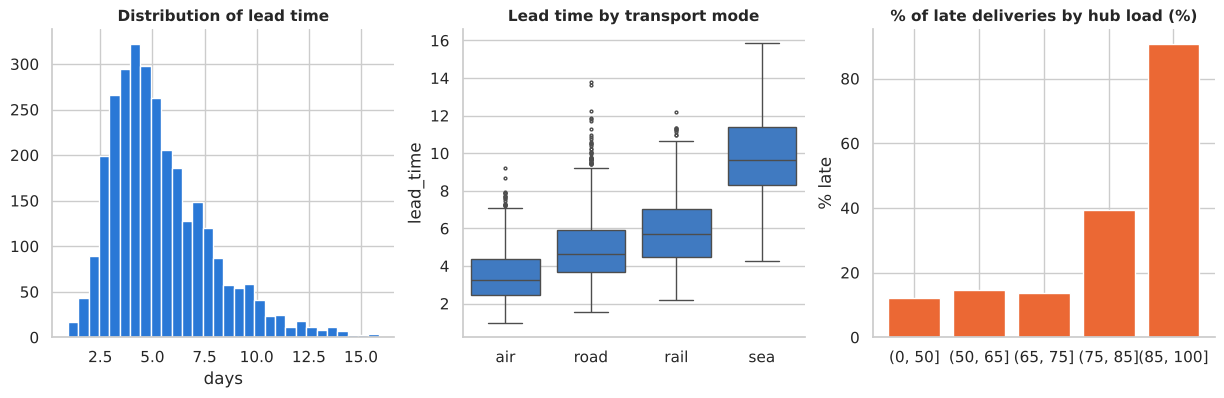

Overall share of late deliveries: 28.3%


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1) Distribution of the lead time
axes[0].hist(shipments["lead_time"], bins=30, color=BLUE, edgecolor="white")
axes[0].set_title("Distribution of lead time"); axes[0].set_xlabel("days")

# 2) Lead time by transport mode
order = ["air", "road", "rail", "sea"]
sns.boxplot(data=shipments, x="transport_mode", y="lead_time", order=order, color=BLUE, ax=axes[1], fliersize=2)
axes[1].set_title("Lead time by transport mode"); axes[1].set_xlabel("")

# 3) Share of late deliveries by hub load class
shipments["hub_load_class"] = pd.cut(shipments["hub_load"], [0, 50, 65, 75, 85, 100])
late_by_load = shipments.groupby("hub_load_class", observed=True)["late"].mean() * 100
axes[2].bar(late_by_load.index.astype(str), late_by_load.values, color=ORANGE)
axes[2].set_title("% of late deliveries by hub load (%)"); axes[2].set_ylabel("% late")

plt.show()
shipments = shipments.drop(columns="hub_load_class")
print(f"Overall share of late deliveries: {shipments['late'].mean():.1%}")

**Question 2** &nbsp;·&nbsp; *Interpretation*

Describe the distribution of the lead time (shape, typical value, extreme values). Which transport mode is the slowest and which one is the most variable? Does this match your intuition of the supply chain?

> **Your answer:** 

**Question 3** &nbsp;·&nbsp; *Interpretation*

Look at the third plot. How does the share of late deliveries evolve with the hub load? Is the relationship *linear* (a constant increase) or does something change at some point? What could it mean operationally?

> **Your answer:** 

**Correlations.** The correlation between two numeric variables ranges from $-1$ (perfect opposite movement) to $+1$ (perfect common movement); $0$ means *no linear relationship*.

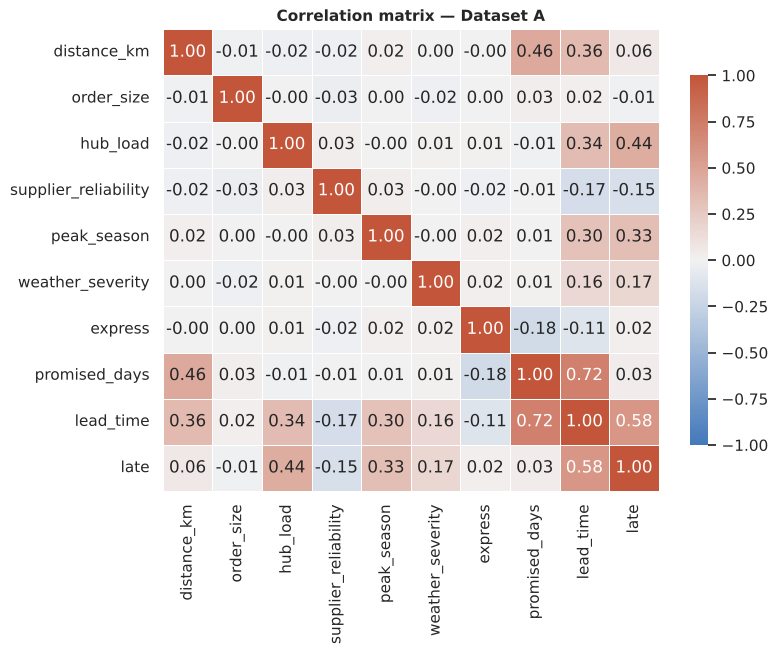

In [6]:
numeric = shipments.drop(columns="transport_mode")
corr = numeric.corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=sns.diverging_palette(250, 20, as_cmap=True), center=0,
            vmin=-1, vmax=1, linewidths=.5, cbar_kws={"shrink": .8})
plt.title("Correlation matrix — Dataset A")
plt.show()

**Question 4** &nbsp;·&nbsp; *Interpretation*

Which variables are the most correlated with `lead_time`? Why is `lead_time` also strongly correlated with `promised_days`? Name one relationship in the data that you know exists (see the previous plot) but that a *linear correlation* describes poorly.

> **Your answer:** 

**Question 5** &nbsp;·&nbsp; *Analysis*

We want to predict `late` **before the shipment leaves**. Can we use `lead_time` as a feature? And `promised_days`? Explain. (This mistake is called **data leakage** and is one of the most frequent in real projects.)

> **Your answer:** 

**Question 6** &nbsp;·&nbsp; *Implementation*

Complete the code to compute (i) the average lead time and (ii) the share of late deliveries depending on whether the shipment took place in peak season (`peak_season = 1`) or not. Then comment in one sentence.

> **Your answer:** 

In [ ]:
# groupby splits the table into groups, then we compute the mean of some columns in each group
shipments.groupby("____")[["lead_time", "late"]].____()

### Dataset B: Supplier financial risk (risk management)

Each row is one **supplier** observed at some date. The target `default_12m` equals 1 if the supplier **defaulted (bankruptcy, payment stop) in the following 12 months**. Defaults are *rare*, as in real life, which makes this dataset a good playground for evaluation metrics.

| Column | Description |
|---|---|
| `debt_ratio` | total debt / total assets |
| `current_ratio` | current assets / current liabilities (liquidity; below 1 is worrying) |
| `profit_margin_pct` | net profit margin (%) |
| `revenue_growth_pct` | yearly revenue growth (%) |
| `country_risk` | country risk score (1 = very safe, 10 = very risky) |
| `years_relationship` | years since we work with this supplier |
| `single_source` | 1 if we have no alternative supplier for its products |
| `late_orders_pct` | % of orders delivered late over the past year |
| `default_12m` | **target** — 1 if the supplier defaulted within 12 months |

In [8]:
suppliers = make_suppliers()          # Dataset B
print("Shape (rows, columns):", suppliers.shape)
display(suppliers.head(6))

counts = suppliers["default_12m"].value_counts()
print(f"\nNumber of suppliers that did not default: {counts[0]}  |  defaulted: {counts[1]}  ({counts[1]/len(suppliers):.1%})")
display(suppliers.groupby("default_12m").mean().T.rename(columns={0: "no default", 1: "default"}))

Shape (rows, columns): (4000, 9)


,debt_ratio,current_ratio,profit_margin_pct,revenue_growth_pct,country_risk,years_relationship,single_source,late_orders_pct,default_12m
0,0.56,1.84,9.8,-5.9,3.9,6.0,1,15.5,0
1,0.98,1.33,9.4,-11.5,2.2,8.0,0,5.3,0
2,0.47,1.72,-2.5,15.3,4.6,9.0,0,4.3,0
3,0.73,1.77,4.3,-2.8,1.7,11.0,1,17.0,0
4,0.79,1.51,6.9,-6.2,3.5,12.0,1,10.8,0
5,1.13,0.41,5.8,-10.1,5.3,4.0,0,5.7,1



Number of suppliers that did not default: 3692  |  defaulted: 308  (7.7%)


default_12m,no default,default
debt_ratio,0.586,0.862
current_ratio,1.624,1.256
profit_margin_pct,7.208,4.394
revenue_growth_pct,3.952,3.736
country_risk,4.045,4.553
years_relationship,7.423,7.312
single_source,0.345,0.325
late_orders_pct,7.774,8.889


**Question 7** &nbsp;·&nbsp; *Interpretation*

Compare the two columns of the last table. Which variables seem to differ the most between defaulting and non-defaulting suppliers? Keep in mind that the scales differ from one variable to another.

> **Your answer:** 

**Question 8** &nbsp;·&nbsp; *Implementation*

Compute the **default rate** (share of defaults) for suppliers that are a single source (`single_source = 1`) versus those that are not. Is there a notable difference? What does it tell you about this variable?

> **Your answer:** 

In [ ]:
suppliers.groupby("____")["____"].____()

## Part 3: Learning and overfitting

### Dataset C: Daily demand of a seasonal product

We observe, during **one year**, the daily demand (units) of a seasonal product as a function of the **day of the year** (1 to 365). The pattern is a smooth seasonal wave plus a **year-end peak** (gift season), and a lot of random noise (customers do not behave exactly the same every day). Because the data is simulated, we can also draw the *true underlying demand curve* (dashed grey), in real life this curve is of course unknown, and this is precisely what a model tries to approximate.

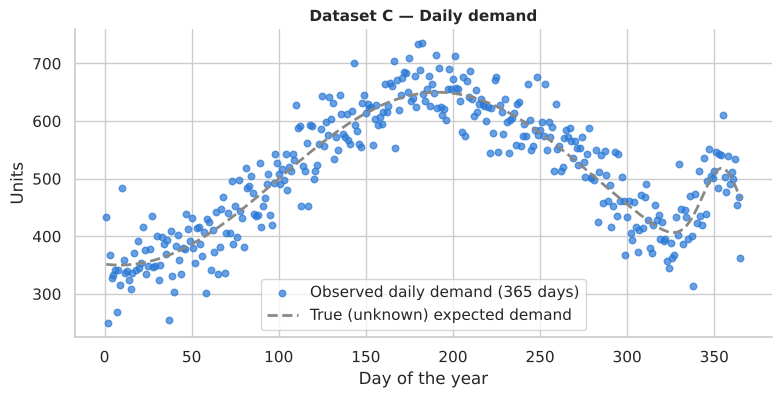

,day_of_year,demand
0,1,433.0
1,2,249.0
2,3,367.0
3,4,328.0
4,5,332.0


In [10]:
demand, true_demand = make_demand()     # Dataset C  (true_demand is the hidden "true" function)
days_grid = np.arange(1, 366)

plt.figure(figsize=(9, 4))
plt.scatter(demand["day_of_year"], demand["demand"], s=22, color=BLUE, alpha=.7, label="Observed daily demand (365 days)")
plt.plot(days_grid, true_demand(days_grid), "--", color=GRAY, lw=2, label="True (unknown) expected demand")
plt.xlabel("Day of the year"); plt.ylabel("Units"); plt.legend(); plt.title("Dataset C — Daily demand")
plt.show()
display(demand.head())

### 3.1 Train set and test set

If we evaluate a model on the very same data that was used to build it, we measure its **memory**, not its **ability to predict the future**. A model is useful only if it works on **new data**. Hence the basic rule of machine learning:

> **Split the data: a *training set* (to fit the model) and a *test set* (kept aside, used only to evaluate it).**

Here we imagine a **young product with little history**: only **40 days** of sales are used for training, and the remaining days are kept for the test.

In [11]:
from sklearn.model_selection import train_test_split

Xd = demand[["day_of_year"]]
yd = demand["demand"]
Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, train_size=40, random_state=RANDOM_STATE)
print("Training observations:", len(Xd_train), "| Test observations:", len(Xd_test))

Training observations: 40 | Test observations: 325


### 3.2 Model complexity: underfitting and overfitting

We fit a **polynomial regression**: demand $= a_0 + a_1 \cdot day + a_2 \cdot day^2 + \dots + a_d \cdot day^d$. The **degree** $d$ is the *complexity* of the model, it is a *hyper-parameter*: a setting that we choose **before** training (as opposed to the coefficients $a_i$, which are learnt from data).

The error is measured by the **RMSE** (root mean squared error): the typical size of the prediction error, in units of demand. We will study it in detail in Part 4.

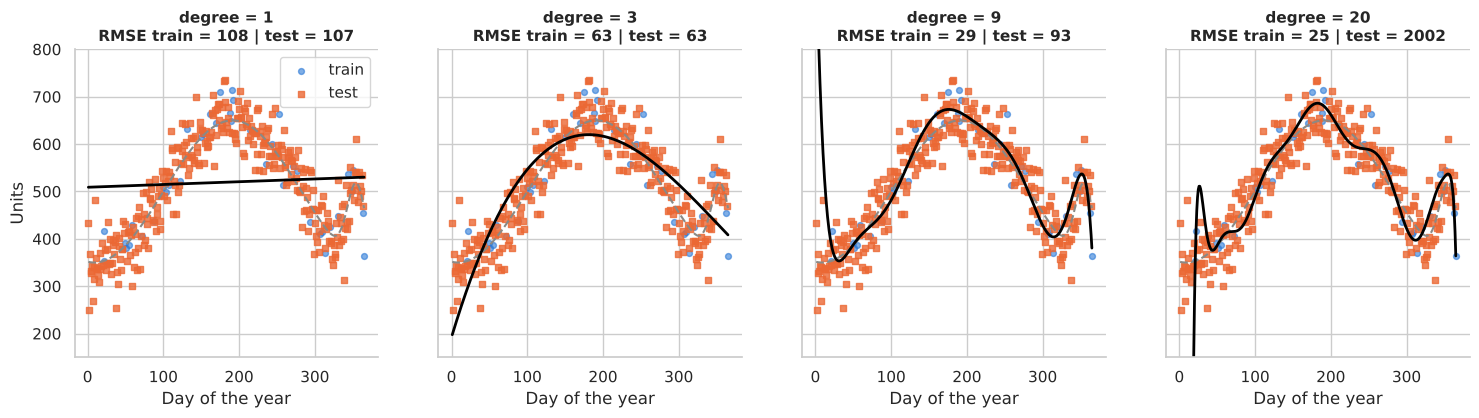

In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

def poly_model(degree):
    # scale the day to [-1, 1], create the powers day, day^2, ..., day^degree, then fit a linear regression
    return make_pipeline(MinMaxScaler(feature_range=(-1, 1)), PolynomialFeatures(degree), LinearRegression())

degrees = [1, 3, 9, 20]
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
grid = pd.DataFrame({"day_of_year": days_grid})

for ax, d in zip(axes, degrees):
    model = poly_model(d).fit(Xd_train, yd_train)
    rmse_tr = root_mean_squared_error(yd_train, model.predict(Xd_train))
    rmse_te = root_mean_squared_error(yd_test, model.predict(Xd_test))
    ax.scatter(Xd_train, yd_train, s=18, color=BLUE, alpha=.6, label="train")
    ax.scatter(Xd_test, yd_test, s=22, color=ORANGE, marker="s", alpha=.8, label="test")
    ax.plot(days_grid, true_demand(days_grid), "--", color=GRAY, lw=1.5)
    ax.plot(days_grid, model.predict(grid), color="black", lw=2)
    ax.set_title(f"degree = {d}\nRMSE train = {rmse_tr:.0f} | test = {rmse_te:.0f}")
    ax.set_xlabel("Day of the year")
axes[0].set_ylabel("Units"); axes[0].legend(); axes[0].set_ylim(150, 800)     # the y-axis is cut: a curve can explode outside the training range
plt.show()

**Question 9** &nbsp;·&nbsp; *Interpretation*

Describe the prediction curve (black) for $d=1$ and for $d=20$. Compare each curve with the true demand (dashed). Which one is too *simple*? Which one follows the noise of the training data?

> **Your answer:** 

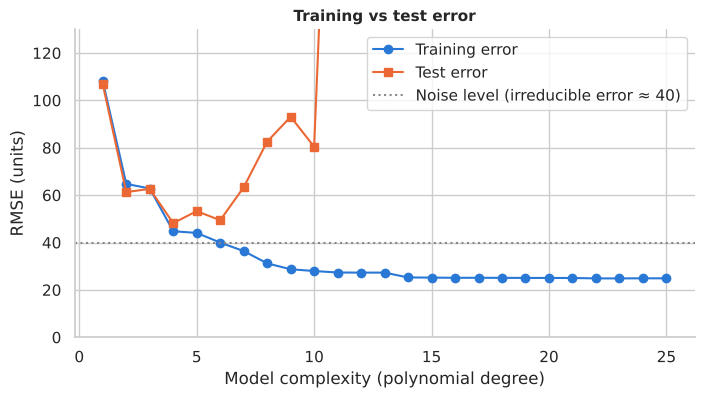

Degree with the lowest test error: 4


In [13]:
# Training and test error for every degree between 1 and 25
degs = range(1, 26)
rmse_train, rmse_test = [], []
for d in degs:
    m = poly_model(d).fit(Xd_train, yd_train)
    rmse_train.append(root_mean_squared_error(yd_train, m.predict(Xd_train)))
    rmse_test.append(root_mean_squared_error(yd_test, m.predict(Xd_test)))

plt.figure(figsize=(8, 4))
plt.plot(degs, rmse_train, "o-", color=BLUE, label="Training error")
plt.plot(degs, rmse_test, "s-", color=ORANGE, label="Test error")
plt.axhline(40, color=GRAY, ls=":", label="Noise level (irreducible error ≈ 40)")
plt.ylim(0, 130)
plt.xlabel("Model complexity (polynomial degree)"); plt.ylabel("RMSE (units)")
plt.title("Training vs test error"); plt.legend(); plt.show()
print("Degree with the lowest test error:", list(degs)[int(np.argmin(rmse_test))])

**Question 10** &nbsp;·&nbsp; *Interpretation*

Describe how the training error and the test error evolve when complexity increases. Where is the "sweet spot"? Why does the test error go **up** again for very large degrees while the training error keeps going down?

> **Your answer:** 

**Question 11** &nbsp;·&nbsp; *Analysis*

Explain in your own words, with a business analogy (e.g. a planner who learns last year's sales by heart), what **underfitting** and **overfitting** mean. Why is the *test* error — and not the training error — the one a manager should look at?

> **Your answer:** 

**Question 12** &nbsp;·&nbsp; *Implementation*

Fit a polynomial model of degree **6** and print its training and test RMSE. Compare with the table above: where does it stand?

> **Your answer:** 

In [ ]:
model6 = poly_model(____).fit(Xd_train, yd_train)
print("Train RMSE:", round(root_mean_squared_error(yd_train, model6.predict(____)), 1))
print("Test  RMSE:", round(root_mean_squared_error(yd_test, model6.predict(____)), 1))

### 3.3 The bias–variance trade-off

The error of a model on new data has three ingredients:

$$\text{Error} = \underbrace{\text{Bias}^2}_{\text{model too simple}} + \underbrace{\text{Variance}}_{\text{model too sensitive to the training sample}} + \underbrace{\text{Noise}}_{\text{cannot be removed}}$$

* A **simple** model (degree 1) has a high **bias**: it misses the real shape of the demand, whatever the data.
* A **very complex** model (degree 20) has a high **variance**: if we collected another year of data, the curve would change a lot.
* The art of machine learning is to find the **right level of complexity** — and, as we will see in Part 10, ensemble methods are clever ways to reduce variance (bagging) or bias (boosting).

**Question 13** &nbsp;·&nbsp; *Analysis*

In which category of the decomposition above would you put each of these situations? (a) A forecasting model that always predicts the yearly average demand. (b) A model that reproduces exactly every demand spike of the past year, including those caused by one-off events. (c) The random behaviour of customers that no model can predict.

> **Your answer:** 

## Part 4: Measuring performance

A model is only as good as the way we measure it — and the "right" measure depends on **the cost of errors for the business**.

### 4.1 Regression metrics (numeric target)

Let $y_i$ be the actual value and $\hat y_i$ the prediction for observation $i$ (among $n$). The error is $e_i = y_i - \hat y_i$.

| Metric | Formula | Reading |
|---|---|---|
| **MAE** — mean absolute error | $\frac1n\sum_i \lvert e_i\rvert$ | the average error, in the unit of the target (days, units…) |
| **RMSE** — root mean squared error | $\sqrt{\frac1n\sum_i e_i^2}$ | like MAE, but **large errors weigh much more** |
| **R²** | $1-\dfrac{\sum_i e_i^2}{\sum_i (y_i-\bar y)^2}$ | share of the variability explained, compared to the naive model "always predict the mean" ($R^2=0$ is as bad as the mean, $R^2=1$ is perfect) |

Let us compute them by hand on five shipments.

In [15]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

actual    = np.array([4, 6, 5, 9, 3])     # real lead times (days)
predicted = np.array([5, 6, 4, 7, 3])     # lead times predicted by a model

table = pd.DataFrame({"actual": actual, "predicted": predicted})
table["error"] = table["actual"] - table["predicted"]
table["abs error"] = table["error"].abs()
table["squared error"] = table["error"] ** 2
display(table)

mae  = table["abs error"].mean()
rmse = np.sqrt(table["squared error"].mean())
sst  = ((actual - actual.mean()) ** 2).sum()          # error of the naive model "always predict the mean"
r2   = 1 - table["squared error"].sum() / sst

print(f"By hand    -> MAE = {mae:.2f} days | RMSE = {rmse:.2f} days | R² = {r2:.2f}")
print(f"With sklearn-> MAE = {mean_absolute_error(actual, predicted):.2f} days | RMSE = {root_mean_squared_error(actual, predicted):.2f} days | R² = {r2_score(actual, predicted):.2f}")

,actual,predicted,error,abs error,squared error
0,4,5,-1,1,1
1,6,6,0,0,0
2,5,4,1,1,1
3,9,7,2,2,4
4,3,3,0,0,0


By hand    -> MAE = 0.80 days | RMSE = 1.10 days | R² = 0.72
With sklearn-> MAE = 0.80 days | RMSE = 1.10 days | R² = 0.72


**MAE or RMSE?** Consider two forecasting tools evaluated on the same 4 shipments: tool A is *always wrong by 2 days*; tool B is *perfect three times but wrong by 8 days once* (a container stuck at a port, for instance).

In [16]:
errors_A = np.array([2, 2, 2, 2])
errors_B = np.array([0, 0, 0, 8])
for name, e in [("Tool A", errors_A), ("Tool B", errors_B)]:
    print(f"{name}: MAE = {np.mean(np.abs(e)):.1f} days | RMSE = {np.sqrt(np.mean(e**2)):.1f} days")

Tool A: MAE = 2.0 days | RMSE = 2.0 days
Tool B: MAE = 2.0 days | RMSE = 4.0 days


**Question 14** &nbsp;·&nbsp; *Interpretation*

The two tools have the same MAE but different RMSE. Which metric would you use if a single 8-day delay can stop a production line? And which one if all delays cost roughly the same per day?

> **Your answer:** 

**Question 15** &nbsp;·&nbsp; *Implementation*

Compute the MAE of the five shipments above **without** using sklearn, in a single line of numpy.

> **Your answer:** 

In [ ]:
mae_manual = np.mean(np.abs(actual ____ predicted))
print(mae_manual)

### 4.2 Classification metrics (categorical target)

For a yes/no target, every prediction falls into one of **four** cases, summarised in the **confusion matrix**. We call "positive" the event we want to detect (here: **default**).

| | Predicted: no default | Predicted: default |
|---|---|---|
| **Actual: no default** | True Negative (TN) | **False Positive (FP)** — false alarm |
| **Actual: default** | **False Negative (FN)** — missed default | True Positive (TP) |

| Metric | Formula | Question it answers |
|---|---|---|
| **Accuracy** | $\frac{TP+TN}{TP+TN+FP+FN}$ | What share of predictions are correct? |
| **Precision** | $\frac{TP}{TP+FP}$ | When the model raises an alarm, how often is it right? |
| **Recall** (sensitivity) | $\frac{TP}{TP+FN}$ | What share of the real defaults do we catch? |
| **F1-score** | $2\cdot\frac{\text{precision}\times\text{recall}}{\text{precision}+\text{recall}}$ | a compromise between precision and recall |

We use Dataset B (suppliers). First, we keep 25% of the suppliers for the test. The option `stratify` makes sure both sets contain the same share of defaults (~8%).

In [18]:
Xb = suppliers.drop(columns="default_12m")
yb = suppliers["default_12m"]
Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb, test_size=0.25, stratify=yb, random_state=RANDOM_STATE)
print(f"Default rate - train: {yb_train.mean():.1%} | test: {yb_test.mean():.1%}")

Default rate - train: 7.7% | test: 7.7%


Let us compare two very simple "models":

1. **The lazy model**: it predicts *"no default"* for every supplier.
2. **A rule of thumb** used by a credit analyst: *flag the supplier if its `debt_ratio` is above 0.8*.

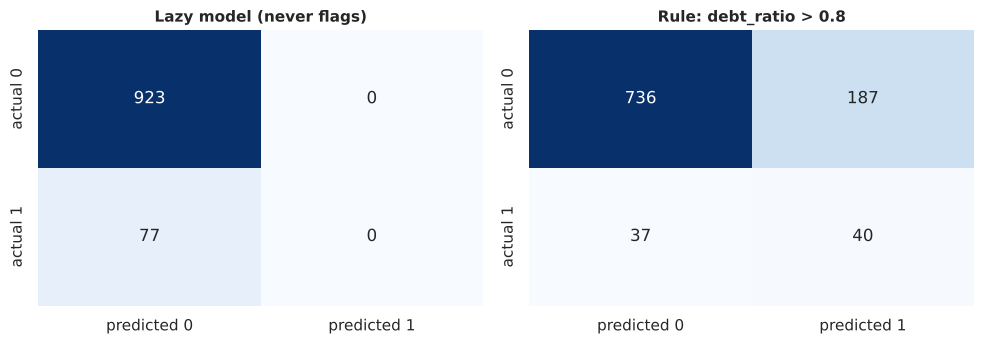

,Lazy model,Rule debt_ratio > 0.8
accuracy,0.923,0.776
precision,0.000,0.176
recall,0.000,0.519
F1,0.000,0.263
# flagged suppliers,0.000,227.000


In [19]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

pred_lazy = np.zeros(len(yb_test), dtype=int)                       # always "no default"
pred_rule = (Xb_test["debt_ratio"] > 0.8).astype(int)               # rule of thumb

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
show_confusion(yb_test, pred_lazy, axes[0], "Lazy model (never flags)")
show_confusion(yb_test, pred_rule, axes[1], "Rule: debt_ratio > 0.8")
plt.tight_layout(); plt.show()

results = pd.DataFrame({
    name: {"accuracy": accuracy_score(yb_test, p), "precision": precision_score(yb_test, p, zero_division=0),
           "recall": recall_score(yb_test, p), "F1": f1_score(yb_test, p, zero_division=0),
           "# flagged suppliers": int(np.sum(p))}
    for name, p in [("Lazy model", pred_lazy), ("Rule debt_ratio > 0.8", pred_rule)]})
display(results.round(3))

**Question 16** &nbsp;·&nbsp; *Analysis*

The lazy model reaches a very high accuracy although it never detects anything. Why? What does this teach you about using accuracy when the event of interest is **rare** (defaults, fraud, stock-outs…)?

> **Your answer:** 

**Question 17** &nbsp;·&nbsp; *Interpretation*

For the rule `debt_ratio > 0.8`: explain in plain business language what its **precision** and its **recall** mean (use the numbers). Is it an efficient screening tool?

> **Your answer:** 

**Question 18** &nbsp;·&nbsp; *Analysis*

A missed default (FN) can mean a production stop, an emergency sourcing operation and lost sales, say **€30,000**, whereas a false alarm (FP) means an extra audit or a back-up supplier contract, say **€3,000**. Given these costs, do you prefer a model with a high precision or a high recall? What should then be done to the decision rule?

> **Your answer:** 

**Question 19** &nbsp;·&nbsp; *Implementation*

Test another rule of thumb: *flag a supplier if its `current_ratio` is **below 1.0*** (it may not be able to pay its short-term debts). Compute its precision and recall on the test set.

> **Your answer:** 

In [ ]:
pred_rule2 = (Xb_test["current_ratio"] ____ 1.0).astype(int)
print("Precision:", round(precision_score(yb_test, ____), 3))
print("Recall   :", round(recall_score(yb_test, ____), 3))

## Part 5: Linear and logistic regression: the reference models

Before using sophisticated algorithms, always start with a **simple, interpretable baseline**. If a complex model cannot beat it clearly, it is not worth its cost.

### 5.1 Linear regression: forecasting the lead time (Dataset A)

A linear regression assumes that the target is a **weighted sum** of the features:

$$\widehat{\text{lead time}} = b_0 + b_1\cdot \text{distance} + b_2\cdot \text{hub load} + b_3 \cdot \text{reliability} + \dots$$

Each coefficient $b_j$ has a direct reading: *"all other things being equal, one more unit of feature $j$ changes the lead time by $b_j$ days"*. The algorithm chooses the $b_j$ that minimise the sum of squared errors on the training set.

**Preparing the features.** Models need *numbers*. The categorical variable `transport_mode` is converted into 0/1 columns (*one-hot encoding*); `road` is the reference mode, so `mode_sea` measures the difference between sea and road. We do **not** use `promised_days` here: we want to model the physical drivers of the lead time (the promise is itself a planner's estimate).

In [21]:
from sklearn.dummy import DummyRegressor

feature_cols = ["distance_km", "order_size", "hub_load", "supplier_reliability",
                "peak_season", "weather_severity", "express"]
modes = pd.get_dummies(shipments["transport_mode"], prefix="mode", dtype=int).drop(columns="mode_road")
X_ship = pd.concat([shipments[feature_cols], modes], axis=1)           # features for the regression
y_lead = shipments["lead_time"]                                        # target (days)

Xs_train, Xs_test, ys_train, ys_test = train_test_split(X_ship, y_lead, test_size=0.25, random_state=RANDOM_STATE)

baseline = DummyRegressor(strategy="mean").fit(Xs_train, ys_train)      # naive model: always the average lead time
lin = LinearRegression().fit(Xs_train, ys_train)

def regression_scores(model, X, y):
    p = model.predict(X)
    return {"MAE (days)": mean_absolute_error(y, p), "RMSE (days)": root_mean_squared_error(y, p), "R²": r2_score(y, p)}

scores = pd.DataFrame({"Naive (mean)": regression_scores(baseline, Xs_test, ys_test),
                       "Linear regression": regression_scores(lin, Xs_test, ys_test)}).T
display(scores.round(3))

coefs = pd.DataFrame({"coefficient (days per unit)": lin.coef_}, index=X_ship.columns)
print(f"Intercept: {lin.intercept_:.2f} days")
display(coefs.round(3))

,MAE (days),RMSE (days),R²
Naive (mean),1.854,2.427,-0.000
Linear regression,0.896,1.126,0.785


Intercept: 2.79 days


,coefficient (days per unit)
distance_km,0.002
order_size,0.020
hub_load,0.048
supplier_reliability,-4.025
peak_season,1.558
weather_severity,0.177
express,-0.774
mode_air,-1.566
mode_rail,0.916
mode_sea,4.523


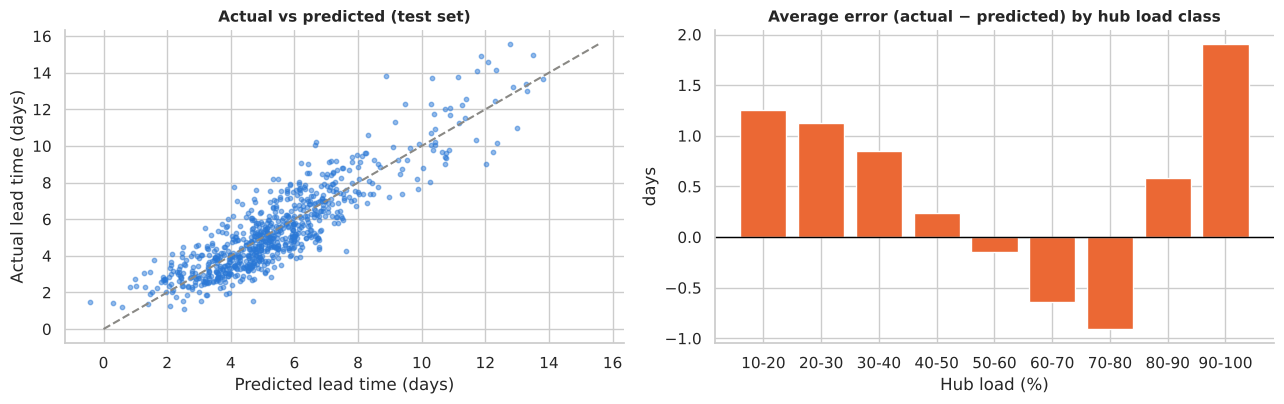

In [22]:
pred_lin = lin.predict(Xs_test)
resid = ys_test - pred_lin

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].scatter(pred_lin, ys_test, s=10, color=BLUE, alpha=.5)
lims = [0, max(ys_test.max(), pred_lin.max())]
axes[0].plot(lims, lims, "--", color=GRAY); axes[0].set_xlabel("Predicted lead time (days)"); axes[0].set_ylabel("Actual lead time (days)")
axes[0].set_title("Actual vs predicted (test set)")

# Average error of the model according to the hub load
hub_bins = pd.cut(Xs_test["hub_load"], np.arange(0, 101, 10))
mean_resid = resid.groupby(hub_bins, observed=True).mean()
axes[1].bar([f"{int(i.left)}-{int(i.right)}" for i in mean_resid.index], mean_resid.values, color=ORANGE)
axes[1].axhline(0, color="black", lw=1)
axes[1].set_title("Average error (actual − predicted) by hub load class"); axes[1].set_xlabel("Hub load (%)"); axes[1].set_ylabel("days")
plt.tight_layout(); plt.show()

**Question 20** &nbsp;·&nbsp; *Interpretation*

Read the coefficient table. (a) By how many days does the lead time increase for **100 additional kilometres**? (b) What is the effect of the sea mode compared with road? (c) What does the coefficient of `supplier_reliability` mean — keep in mind that this score varies only between 0.3 and 1. (d) Does `order_size` matter?

> **Your answer:** 

**Question 21** &nbsp;·&nbsp; *Interpretation*

Compare the linear regression with the naive model (R², RMSE). Then look at the left plot: are the predictions good on average? Where does the model seem to be less reliable?

> **Your answer:** 

**Question 22** &nbsp;·&nbsp; *Analysis*

Look at the right plot (average error by hub load). What does it reveal about the **assumption of a linear relationship** between hub load and lead time? Which phenomenon, already seen in Part 2, is missed by the linear model?

> **Your answer:** 

**Question 23** &nbsp;·&nbsp; *Implementation*

Use the model to predict the lead time of a **long, sea shipment of 800 km in peak season, leaving a very congested hub (90% of load)**, with a supplier of reliability 0.7. Fill in the blanks.

> **Your answer:** 

In [ ]:
new_shipment = pd.DataFrame([{
    "distance_km": 800, "order_size": 40, "hub_load": ____, "supplier_reliability": 0.7,
    "peak_season": 1, "weather_severity": 3, "express": 0,
    "mode_rail": 0, "mode_sea": ____, "mode_air": 0}])[X_ship.columns]

print("Predicted lead time (days):", lin.____(new_shipment).round(1))

### 5.2 Logistic regression: predicting supplier default (Dataset B)

For a yes/no target, a linear regression is not appropriate (it could output "-0.3" or "1.7" as a probability). The **logistic regression** keeps the weighted sum $z = b_0 + b_1 x_1 + \dots$ but passes it through an *S-shaped* function that squeezes it between 0 and 1:

$$\hat p = P(\text{default}) = \frac{1}{1+e^{-z}}$$

* A positive coefficient **increases** the probability of default; a negative one decreases it.
* $e^{b_j}$ is the **odds ratio**: how the *odds* $\frac{p}{1-p}$ are multiplied when the feature increases by one unit.

Because the features have very different scales (a debt ratio around 0.6, a number of years around 7…), we first **standardise** them (subtract the mean, divide by the standard deviation). A coefficient then reads *"effect of one standard deviation"* and the coefficients become **comparable** across variables.

,coefficient,odds ratio (+1 std)
debt_ratio,0.832,2.298
country_risk,0.358,1.431
late_orders_pct,0.099,1.104
single_source,-0.007,0.993
revenue_growth_pct,-0.054,0.948
years_relationship,-0.093,0.911
profit_margin_pct,-0.629,0.533
current_ratio,-0.802,0.448


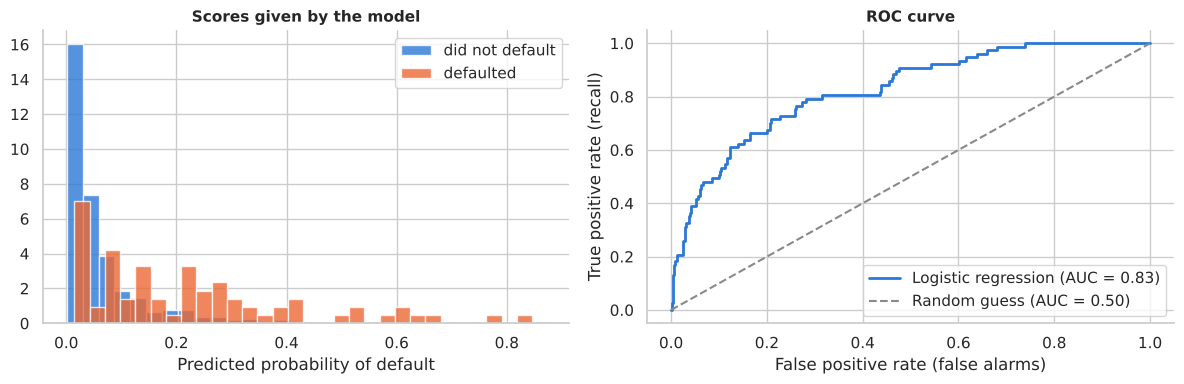

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve

logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logit.fit(Xb_train, yb_train)
proba_test = logit.predict_proba(Xb_test)[:, 1]          # estimated probability of default for each test supplier

coefs_logit = pd.DataFrame({"coefficient": logit[-1].coef_[0],
                            "odds ratio (+1 std)": np.exp(logit[-1].coef_[0])}, index=Xb.columns)
display(coefs_logit.sort_values("coefficient", ascending=False).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(proba_test[yb_test == 0], bins=30, alpha=.8, color=BLUE, label="did not default", density=True)
axes[0].hist(proba_test[yb_test == 1], bins=30, alpha=.8, color=ORANGE, label="defaulted", density=True)
axes[0].set_xlabel("Predicted probability of default"); axes[0].set_title("Scores given by the model"); axes[0].legend()

fpr, tpr, _ = roc_curve(yb_test, proba_test)
auc = roc_auc_score(yb_test, proba_test)
axes[1].plot(fpr, tpr, color=BLUE, lw=2, label=f"Logistic regression (AUC = {auc:.2f})")
axes[1].plot([0, 1], [0, 1], "--", color=GRAY, label="Random guess (AUC = 0.50)")
axes[1].set_xlabel("False positive rate (false alarms)"); axes[1].set_ylabel("True positive rate (recall)")
axes[1].set_title("ROC curve"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

**The ROC curve and the AUC.** For *every possible threshold* above which we flag a supplier, the ROC curve plots the share of real defaults caught (recall) against the share of false alarms. The **AUC** (area under the curve) summarises the ability of the model to **rank** risky suppliers above safe ones, independently of any threshold: 0.5 = random ranking, 1.0 = perfect ranking.

**Question 24** &nbsp;·&nbsp; *Interpretation*

Which variables increase the default risk, which ones reduce it? Which variable has the strongest effect once all variables are on the same scale? Is there something surprising (e.g. a variable whose effect is close to zero)?

> **Your answer:** 

**Question 25** &nbsp;·&nbsp; *Interpretation*

The AUC of the model is displayed on the ROC curve. Explain what it means in one sentence, for a manager who has never seen it. Is the model a perfect crystal ball? Do you think it is useful anyway?

> **Your answer:** 

**Choosing the decision threshold.** The model outputs a probability; **we** decide above which probability a supplier is flagged. The default threshold of 0.5 is rarely appropriate when defaults are rare and expensive. We evaluate the *total cost* on the test set for each threshold, with the costs discussed in Part 4 (missed default: **€30,000**, false alarm: **€3,000**).

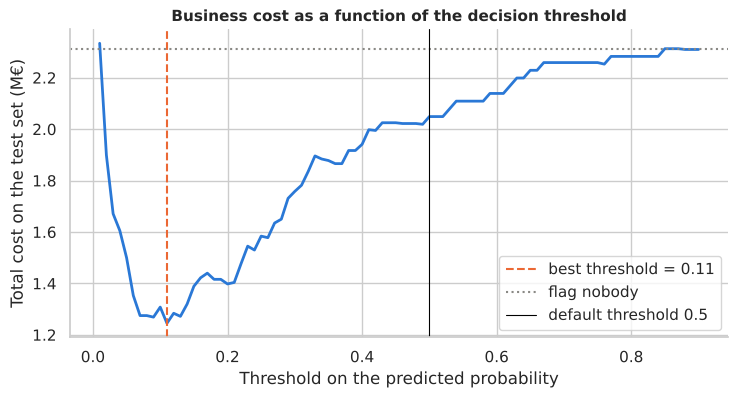

Best threshold: 0.11 -> cost = 1.25 M€  (flag nobody: 2.31 M€ | flag everybody: 2.77 M€)
At this threshold: 206 suppliers flagged out of 1000 | recall = 0.66 | precision = 0.25


In [25]:
COST_FN, COST_FP = 30_000, 3_000     # cost of a missed default / of a false alarm (€)

def business_cost(y_true, proba, threshold):
    flagged = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, flagged).ravel()
    return fn * COST_FN + fp * COST_FP

thresholds = np.linspace(0.01, 0.9, 90)
costs = [business_cost(yb_test, proba_test, t) for t in thresholds]
best_t = thresholds[int(np.argmin(costs))]

cost_nobody = yb_test.sum() * COST_FN                      # flag nobody: we pay for all defaults
cost_everybody = (len(yb_test) - yb_test.sum()) * COST_FP  # flag everybody: we pay all the false alarms

plt.figure(figsize=(8.5, 4))
plt.plot(thresholds, np.array(costs) / 1e6, color=BLUE, lw=2)
plt.axvline(best_t, color=ORANGE, ls="--", label=f"best threshold = {best_t:.2f}")
plt.axhline(cost_nobody / 1e6, color=GRAY, ls=":", label="flag nobody")
plt.axvline(0.5, color="black", lw=.8, label="default threshold 0.5")
plt.xlabel("Threshold on the predicted probability"); plt.ylabel("Total cost on the test set (M€)")
plt.title("Business cost as a function of the decision threshold"); plt.legend(); plt.show()

best_flagged = (proba_test >= best_t).astype(int)
print(f"Best threshold: {best_t:.2f} -> cost = {min(costs)/1e6:.2f} M€  "
      f"(flag nobody: {cost_nobody/1e6:.2f} M€ | flag everybody: {cost_everybody/1e6:.2f} M€)")
print(f"At this threshold: {best_flagged.sum()} suppliers flagged out of {len(yb_test)} | "
      f"recall = {recall_score(yb_test, best_flagged):.2f} | precision = {precision_score(yb_test, best_flagged):.2f}")

**Question 26** &nbsp;·&nbsp; *Analysis*

Why is the best threshold much lower than 0.5? What would happen to the best threshold if a missed default cost only €3,000 instead of €30,000? (Reason first, then check by changing `COST_FN` and re-running the two previous cells.)

> **Your answer:** 

**Question 27** &nbsp;·&nbsp; *Implementation*

Compute by yourself the confusion matrix and the total cost obtained with a threshold of **0.10**. Then compare with the best threshold found above.

> **Your answer:** 

In [ ]:
flagged = (proba_test >= ____).astype(int)
tn, fp, fn, tp = confusion_matrix(yb_test, flagged).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print("Total cost (M€):", (fn * ____ + fp * ____) / 1e6)

### 5.3 What linear models cannot do

Both models above are **additive**: each feature acts independently and its effect is *proportional*. They cannot capture by themselves:

* **thresholds** — a hub that works perfectly until 75% of load and then collapses;
* **interactions** — a supplier that is dangerous only if it is *both* highly indebted *and* unprofitable.

Real supply-chain and risk data are full of such effects. Two families of methods overcome this limit in very different ways: **kernels** (Support Vector Machines, Part 6), which bend the frontier by creating new variables implicitly, and **decision trees** (Part 9), which cut the data with successive thresholds. Neural networks (Part 11) are a third answer.

## Part 6: Support Vector Machines (SVM): "the widest street"

### 6.1 The idea: separate the two classes with the widest possible margin

Logistic regression (Part 5.2) draws a **straight frontier** between suppliers that default and suppliers that do not. When the two groups can be separated, there are usually **many** straight lines that do the job. Which one should we choose?

The **Support Vector Machine** gives a geometric answer: choose the line that stays **as far as possible from both groups**. Imagine the widest possible *street* that you can draw between blue houses and orange houses:

* the middle of the street is the **frontier**;
* the edges of the street form the **margin**;
* the observations lying on the edges of the street (or inside it) are the **support vectors**: they alone determine where the frontier is. Moving any other observation (without crossing the street) changes nothing.

Like the logistic regression, the SVM computes a **score** $f(x) = b + w_1 x_1 + w_2 x_2 + \dots$ and predicts class 1 when $f(x) > 0$. The edges of the street are the lines $f(x) = -1$ and $f(x) = +1$, and the width of the street is $2 / \lVert w \rVert$: the SVM looks for the weights $w$ that make this width as large as possible.

A toy example: 28 suppliers described by two ratios, labelled *risky* (orange) or *safe* (blue). *Run the cell: it also defines a helper `plot_svm` that draws the frontier (solid line), the edges of the margin (dashed lines) and circles the support vectors.*

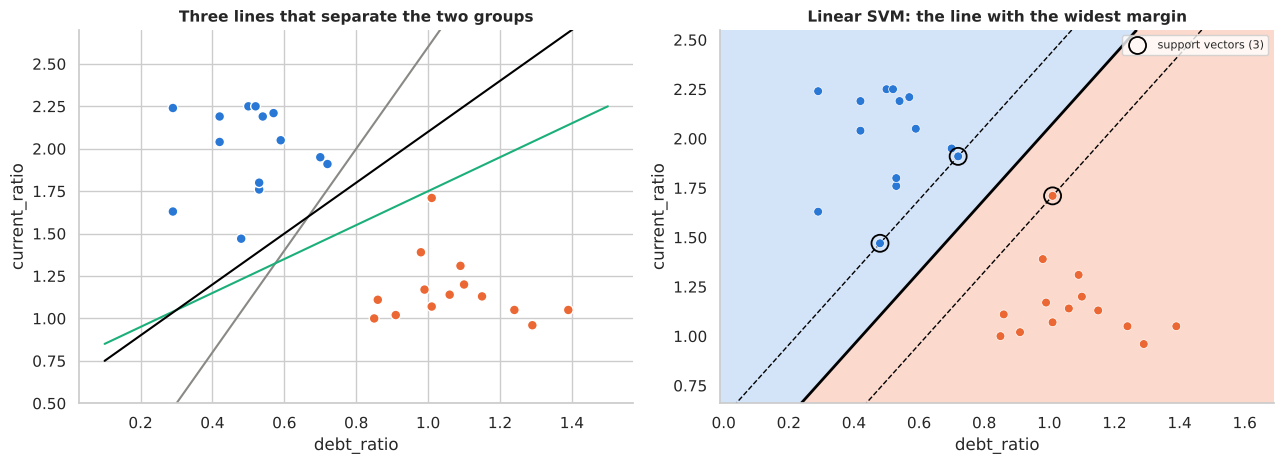

Width of the street (margin): 0.35  |  number of support vectors: 3


In [27]:
from sklearn.svm import SVC

# ---- A toy dataset: 28 suppliers, 2 ratios ----
rng = np.random.default_rng(4)
n = 14
toy = pd.DataFrame({
    "debt_ratio":    np.r_[rng.normal(0.50, 0.13, n), rng.normal(1.10, 0.13, n)].round(2),
    "current_ratio": np.r_[rng.normal(2.00, 0.25, n), rng.normal(1.20, 0.25, n)].round(2),
    "risky":         np.r_[np.zeros(n, int), np.ones(n, int)]})
toy_features = ["debt_ratio", "current_ratio"]

def plot_svm(model, df, features, target, ax=None, title=None, show_sv=True):
    # Draws the SVM frontier (solid), the edges of the margin (dashed) and circles the support vectors.
    # `df` must be the data used to fit the model.
    ax = ax or plt.gca()
    f1, f2 = features
    xx, yy = np.meshgrid(np.linspace(df[f1].min() - .3, df[f1].max() + .3, 300),
                         np.linspace(df[f2].min() - .3, df[f2].max() + .3, 300))
    grid_svm = pd.DataFrame({f1: xx.ravel(), f2: yy.ravel()})
    zz = model.decision_function(grid_svm).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-1e9, 0, 1e9], colors=["#d3e3f8", "#fbd9cc"])
    ax.contour(xx, yy, zz, levels=[-1, 0, 1], colors=["black"], linestyles=["--", "-", "--"], linewidths=[1, 2, 1])
    ax.scatter(df[f1], df[f2], c=np.where(df[target] == 1, ORANGE, BLUE), edgecolor="white", linewidth=.5, s=40, zorder=3)
    if show_sv:
        svc = model[-1] if hasattr(model, "steps") else model          # the SVM itself (last step of a pipeline)
        sv = df.iloc[svc.support_]
        ax.scatter(sv[f1], sv[f2], s=150, facecolors="none", edgecolors="black", linewidths=1.3, zorder=4,
                   label=f"support vectors ({len(sv)})")
        ax.legend(loc="upper right", fontsize=8)
    ax.set_xlabel(f1); ax.set_ylabel(f2)
    if title: ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].scatter(toy["debt_ratio"], toy["current_ratio"], c=np.where(toy["risky"] == 1, ORANGE, BLUE), edgecolor="white", s=50)
xs = np.linspace(0.1, 1.5, 10)
for (slope, intercept), color in zip([(3.0, -0.4), (1.0, 0.75), (1.5, 0.6)], [GRAY, AQUA, "black"]):
    axes[0].plot(xs, slope * xs + intercept, color=color, lw=1.5)
axes[0].set_ylim(0.5, 2.7); axes[0].set_xlabel("debt_ratio"); axes[0].set_ylabel("current_ratio")
axes[0].set_title("Three lines that separate the two groups")

svm_toy = SVC(kernel="linear", C=1000).fit(toy[toy_features], toy["risky"])      # a (very large) C forbids any error
plot_svm(svm_toy, toy, toy_features, "risky", axes[1], "Linear SVM: the line with the widest margin")
plt.tight_layout(); plt.show()
print(f"Width of the street (margin): {2 / np.linalg.norm(svm_toy.coef_[0]):.2f}  |  number of support vectors: {len(svm_toy.support_)}")

**Question 28** &nbsp;·&nbsp; *Interpretation*

(a) On the left, the three lines classify **all** the training suppliers correctly. Which one would you trust the least for a *new* supplier, and why? (b) On the right, how many support vectors are there? What would happen to the SVM frontier if we removed the supplier located at `debt_ratio` ≈ 0.3, `current_ratio` ≈ 2.25 from the data? And if we removed one of the circled suppliers?

> **Your answer:** 

### 6.2 Soft margin: the hyper-parameter `C`

In real data the two groups **overlap**: a few safe suppliers look risky and vice versa, and no line can separate them perfectly. The SVM then accepts that some observations are inside the street or on the wrong side, but it **pays a penalty** for each violation. It looks for the best compromise:

$$\text{minimise} \quad \underbrace{\frac{1}{\text{width of the street}}}_{\text{we want a wide street}} \; + \; C \times \underbrace{\text{(total size of the violations)}}_{\text{we want few errors}}$$

* **Large `C`**: violations are expensive → narrow street that tries to classify every training point correctly (risk of **overfitting**).
* **Small `C`**: violations are cheap → wide street, many support vectors, the frontier is decided by "the crowd" rather than by a few points (more **bias**, more **stability**).

We add three atypical suppliers to our toy example and compare three values of `C`.

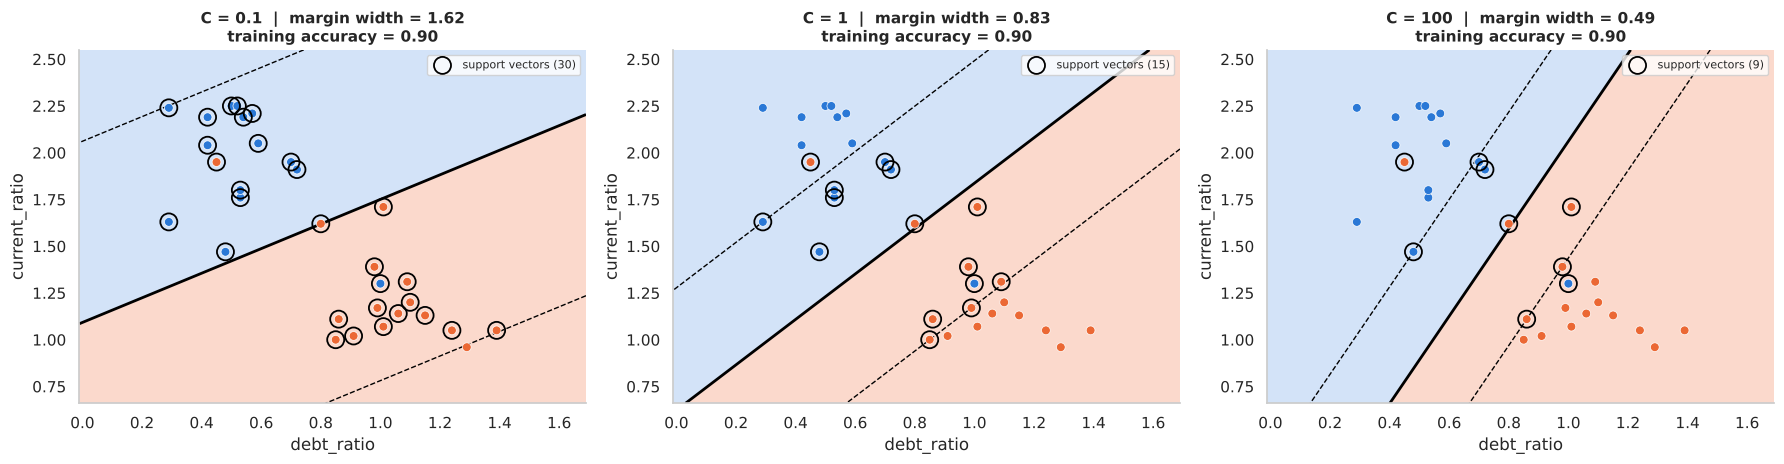

In [28]:
toy2 = pd.concat([toy, pd.DataFrame({"debt_ratio": [1.00, 0.45, 0.80], "current_ratio": [1.30, 1.95, 1.62],
                                       "risky": [0, 1, 1]})], ignore_index=True)       # 3 atypical suppliers

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, C in zip(axes, [0.1, 1, 100]):
    svm_c = SVC(kernel="linear", C=C).fit(toy2[toy_features], toy2["risky"])
    width = 2 / np.linalg.norm(svm_c.coef_[0])
    plot_svm(svm_c, toy2, toy_features, "risky", ax,
             f"C = {C}  |  margin width = {width:.2f}\ntraining accuracy = {svm_c.score(toy2[toy_features], toy2['risky']):.2f}")
plt.tight_layout(); plt.show()

**Question 29** &nbsp;·&nbsp; *Interpretation*

Describe how the width of the street and the number of support vectors change when `C` goes from 0.1 to 100. Which value of `C` gives a frontier that depends on only a handful of suppliers? Which hyper-parameter seen in Part 3 (polynomial regression) plays a similar role, i.e. controls the **complexity** of the model?

> **Your answer:** 

### 6.3 A linear SVM for supplier default (Dataset B)

We now apply a linear SVM to the 8 financial variables of Dataset B and compare it with the logistic regression of Part 5.2. Two practical points:

* **Standardisation is mandatory**: the SVM measures *distances* to the frontier, so a variable with large numbers would dominate (we will come back to this trap in Part 7.2). We use the same `make_pipeline(StandardScaler(), ...)` as for the logistic regression.
* **Rare events**: only ~8% of the suppliers default. For an SVM, the "cheapest" street is then often to put *everybody* on the safe side and to pay a few violations. The option `class_weight="balanced"` makes each violation by a defaulting supplier **≈ 11 times more expensive** (the ratio safe/default), exactly like the business costs of Part 4.

The SVM does not give a probability but a **score** $f(x)$ (a signed distance to the frontier): positive = default side. The AUC only needs a *ranking* of the suppliers, so it can be computed from this score.

,test AUC,# flagged suppliers,recall,precision
Logistic regression (threshold 0.5),0.825,12.0,0.117,0.75
"Linear SVM, balanced (score > 0)",0.835,290.0,0.753,0.20


Number of support vectors: 1747 out of 3000 training suppliers


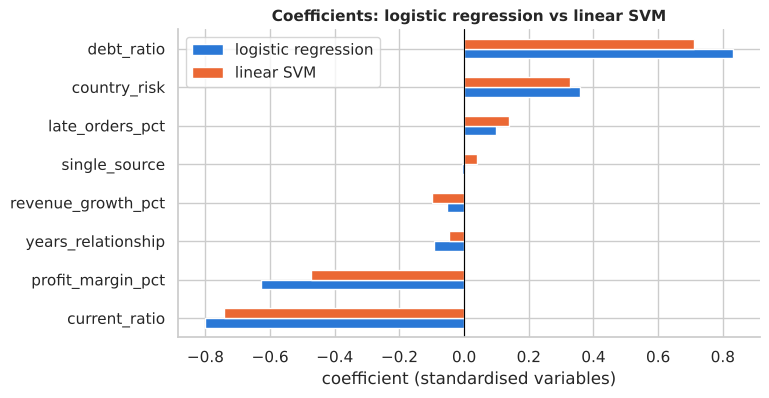

In [29]:
svm_lin = make_pipeline(StandardScaler(), SVC(kernel="linear", C=1, class_weight="balanced"))
svm_lin.fit(Xb_train, yb_train)
score_svm = svm_lin.decision_function(Xb_test)          # signed distance to the frontier (> 0: "default" side)

svm_rows = {}
for name, s, flagged in [("Logistic regression (threshold 0.5)", proba_test, (proba_test >= 0.5).astype(int)),
                         ("Linear SVM, balanced (score > 0)", score_svm, svm_lin.predict(Xb_test))]:
    svm_rows[name] = {"test AUC": roc_auc_score(yb_test, s), "# flagged suppliers": int(flagged.sum()),
                      "recall": recall_score(yb_test, flagged), "precision": precision_score(yb_test, flagged)}
display(pd.DataFrame(svm_rows).T.round(3))

coef_compare = pd.DataFrame({"logistic regression": logit[-1].coef_[0], "linear SVM": svm_lin[-1].coef_[0]}, index=Xb.columns)
print(f"Number of support vectors: {svm_lin[-1].n_support_.sum()} out of {len(Xb_train)} training suppliers")
coef_compare.sort_values("logistic regression").plot.barh(figsize=(7.5, 4), color=[BLUE, ORANGE])
plt.axvline(0, color="black", lw=.8); plt.xlabel("coefficient (standardised variables)")
plt.title("Coefficients: logistic regression vs linear SVM"); plt.show()

**Question 30** &nbsp;·&nbsp; *Interpretation*

(a) Compare the signs and the ranking of the coefficients of the two models. Do they tell the same story about what drives the default risk? (b) Compare their AUC. Why are the two models so close? (c) The two models flag very different numbers of suppliers. Is it a sign that one of them is much better? (Think about the threshold and the option `class_weight`.)

> **Your answer:** 

**Question 31** &nbsp;·&nbsp; *Implementation*

What happens if we **forget** the option `class_weight="balanced"`? Fit the same linear SVM with `class_weight=None` (the default), then print the number of suppliers it flags on the test set and its coefficients. Explain the result.

> **Your answer:** 

In [ ]:
svm_unbalanced = make_pipeline(StandardScaler(), SVC(kernel="linear", C=1, class_weight=____))
svm_unbalanced.fit(Xb_train, ____)
print("Number of flagged suppliers on the test set:", svm_unbalanced.predict(____).sum())
print("Coefficients:", svm_unbalanced[-1].coef_[0].round(3))

### 6.4 Kernels: when a straight line is not enough

#### A one-variable example: the cold chain

Vaccines and many drugs must be transported between **2 °C and 8 °C**. A shipment is *damaged* if the temperature was too **low** *or* too **high**. With the temperature alone, no single threshold separates damaged and intact shipments: we need two thresholds, which a linear model cannot produce.

The trick: **create a new variable**, here $\text{temperature}^2$. In the plane (temperature, temperature²) the points lie on a parabola, and a **straight line** can now separate the two groups. Coming back to the temperature axis, this straight line corresponds to **two thresholds**.

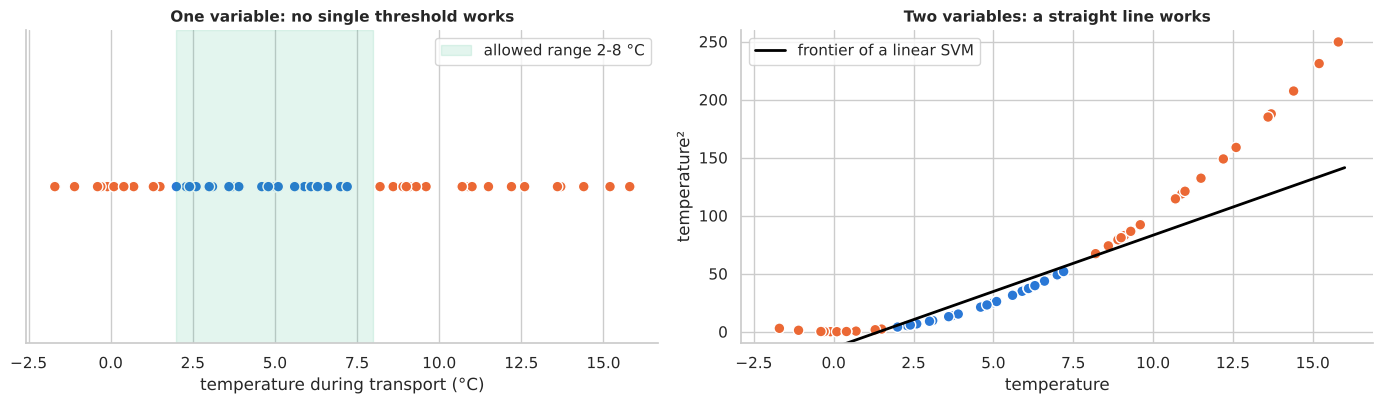

The straight line corresponds to two thresholds on the temperature: 1.7 °C and 8.0 °C
Training accuracy: 1.0


In [31]:
rng = np.random.default_rng(8)
cold = pd.DataFrame({"temperature": rng.uniform(-2, 16, 60).round(1)})                    # 60 pharmaceutical shipments
cold["damaged"] = ((cold["temperature"] < 2) | (cold["temperature"] > 8)).astype(int)       # outside the 2-8 °C range
cold["temperature_squared"] = cold["temperature"] ** 2                                      # the new variable

svm_cold = SVC(kernel="linear", C=100).fit(cold[["temperature", "temperature_squared"]], cold["damaged"])
w, b = svm_cold.coef_[0], svm_cold.intercept_[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
colors_cold = np.where(cold["damaged"] == 1, ORANGE, BLUE)
axes[0].scatter(cold["temperature"], np.zeros(len(cold)), c=colors_cold, s=60, edgecolor="white")
axes[0].axvspan(2, 8, color=AQUA, alpha=.12, label="allowed range 2-8 °C"); axes[0].set_yticks([]); axes[0].legend()
axes[0].set_xlabel("temperature during transport (°C)"); axes[0].set_title("One variable: no single threshold works")
xs = np.linspace(-2, 16, 100)
axes[1].scatter(cold["temperature"], cold["temperature_squared"], c=colors_cold, s=60, edgecolor="white")
axes[1].plot(xs, -(b + w[0] * xs) / w[1], color="black", lw=2, label="frontier of a linear SVM")
axes[1].set_ylim(-10, 260); axes[1].legend(loc="upper left")
axes[1].set_xlabel("temperature"); axes[1].set_ylabel("temperature²"); axes[1].set_title("Two variables: a straight line works")
plt.tight_layout(); plt.show()

thresholds_found = np.sort(np.roots([w[1], w[0], b]))        # where the straight line crosses the parabola
print(f"The straight line corresponds to two thresholds on the temperature: {thresholds_found[0]:.1f} °C and {thresholds_found[1]:.1f} °C")
print("Training accuracy:", svm_cold.score(cold[["temperature", "temperature_squared"]], cold["damaged"]))

**Question 32** &nbsp;·&nbsp; *Analysis*

(a) Compare the two thresholds found by the SVM with the real rule (2 °C and 8 °C). (b) Why can a logistic regression using only `temperature` not reproduce this rule? What could you *add* to the logistic regression so that it can? (c) In this example **we** chose the right new variable because we knew the rule. Why is it difficult to do the same with 8 or 10 variables?

> **Your answer:** 

#### The kernel trick

The mathematics of the SVM have a remarkable property: to find the frontier and to make a prediction, the algorithm never needs the new variables themselves; it only needs to know **how similar two observations are**. This similarity function is called a **kernel**. Choosing a kernel = choosing implicitly a (possibly huge) set of new variables:

| Kernel | Similarity between two observations $x$ and $x'$ | Shape of the frontier |
|---|---|---|
| `linear` | $x \cdot x'$ (weighted sum) | straight line (hyperplane) |
| `poly` (degree $d$) | $(1 + x\cdot x')^d$ | polynomial curve (squares, products… up to degree $d$) |
| `rbf` (Gaussian, the default) | $\exp(-\gamma \,\lVert x - x'\rVert^2)$ | any smooth shape |

With the **RBF kernel**, the score of a new observation is a sum over the support vectors: *each support vector "votes" for its class with a weight that decreases with its distance to the new observation*. The hyper-parameter $\gamma$ (`gamma`) controls the **radius of influence** of each support vector:

* small $\gamma$ → each support vector influences a large zone → smooth frontier;
* large $\gamma$ → each support vector influences only its immediate neighbourhood → very irregular frontier, "islands" around points.

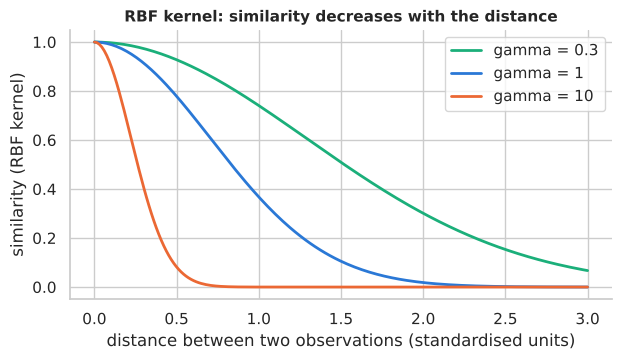

In [32]:
distance = np.linspace(0, 3, 200)
plt.figure(figsize=(7, 3.5))
for g, color in [(0.3, AQUA), (1, BLUE), (10, ORANGE)]:
    plt.plot(distance, np.exp(-g * distance ** 2), color=color, lw=2, label=f"gamma = {g}")
plt.xlabel("distance between two observations (standardised units)"); plt.ylabel("similarity (RBF kernel)")
plt.title("RBF kernel: similarity decreases with the distance"); plt.legend(); plt.show()

### Dataset D: Supplier audit (2 variables)

A purchasing department audits suppliers and records two indicators: the **defect rate** (% of defective parts found) and the **average delivery delay** (days). After a deep investigation, each supplier is labelled **at risk** (1) or **reliable** (0). With only two variables we can *draw* what the algorithms learn. The pattern is deliberately non-linear: a straight line cannot separate the two groups.

,defect_rate_pct,avg_delay_days,at_risk
0,2.93,4.28,1
1,1.15,4.24,0
2,2.52,7.97,0
3,4.36,6.31,0
4,6.38,3.79,1


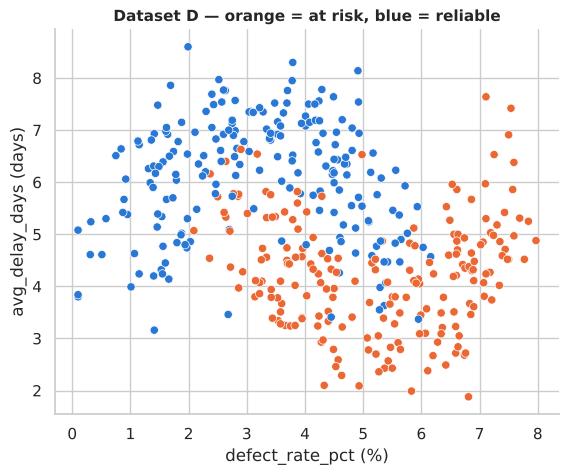

In [33]:
audit = make_audit()                  # Dataset D
display(audit.head())

plt.figure(figsize=(6.5, 5))
plt.scatter(audit["defect_rate_pct"], audit["avg_delay_days"], c=np.where(audit["at_risk"] == 1, ORANGE, BLUE),
            edgecolor="white", linewidth=.5, s=36)
plt.xlabel("defect_rate_pct (%)"); plt.ylabel("avg_delay_days (days)")
plt.title("Dataset D — orange = at risk, blue = reliable"); plt.show()

audit_features = ["defect_rate_pct", "avg_delay_days"]
audit_train, audit_test = train_test_split(audit, test_size=0.3, stratify=audit["at_risk"], random_state=RANDOM_STATE)

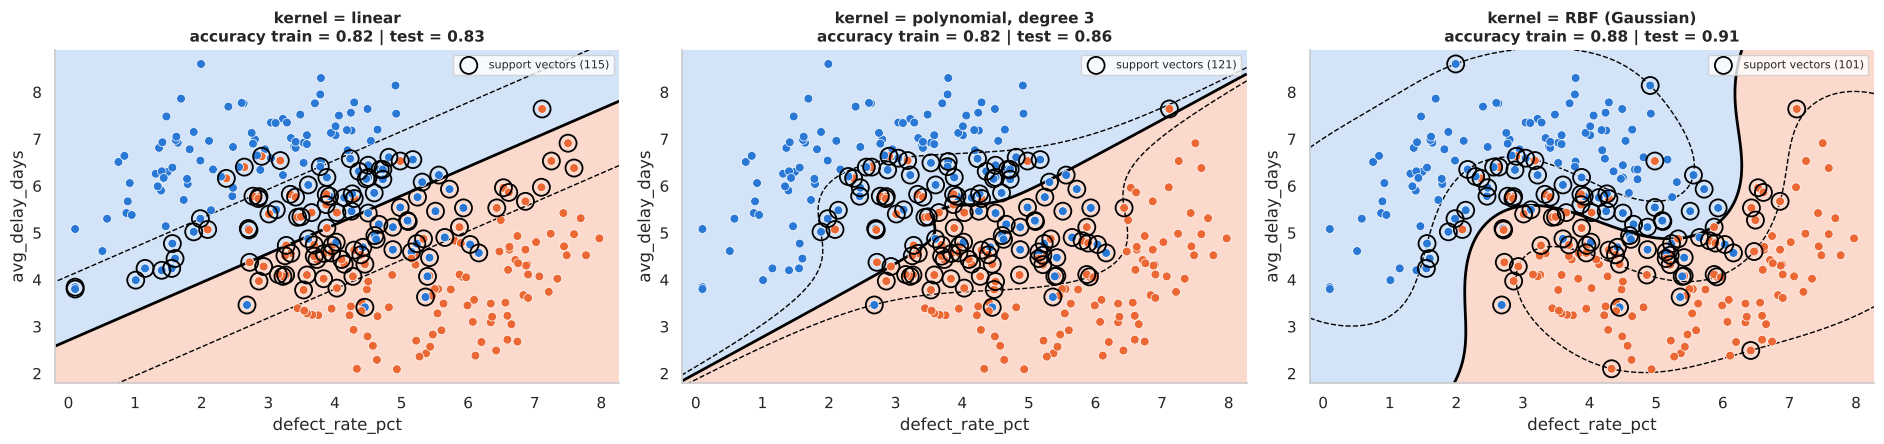

In [34]:
kernels = [("linear", dict(kernel="linear")), ("polynomial, degree 3", dict(kernel="poly", degree=3)), ("RBF (Gaussian)", dict(kernel="rbf"))]
fig, axes = plt.subplots(1, 3, figsize=(19, 4.6))
for ax, (name, params) in zip(axes, kernels):
    svm_k = make_pipeline(StandardScaler(), SVC(C=1, **params)).fit(audit_train[audit_features], audit_train["at_risk"])
    acc_tr = svm_k.score(audit_train[audit_features], audit_train["at_risk"])
    acc_te = svm_k.score(audit_test[audit_features], audit_test["at_risk"])
    plot_svm(svm_k, audit_train, audit_features, "at_risk", ax, f"kernel = {name}\naccuracy train = {acc_tr:.2f} | test = {acc_te:.2f}")
plt.tight_layout(); plt.show()

**Question 33** &nbsp;·&nbsp; *Interpretation*

Compare the three kernels: shape of the frontier, train and test accuracy, number of support vectors. Which kernel fits the "two moons" shape of the data best? Why does the linear SVM reach only ≈ 83% whatever the value of `C`?

> **Your answer:** 

#### The two hyper-parameters of the RBF SVM: `C` and `gamma`

We fit nine RBF SVMs, for three values of `C` (cost of the violations) and three values of `gamma` (radius of influence).

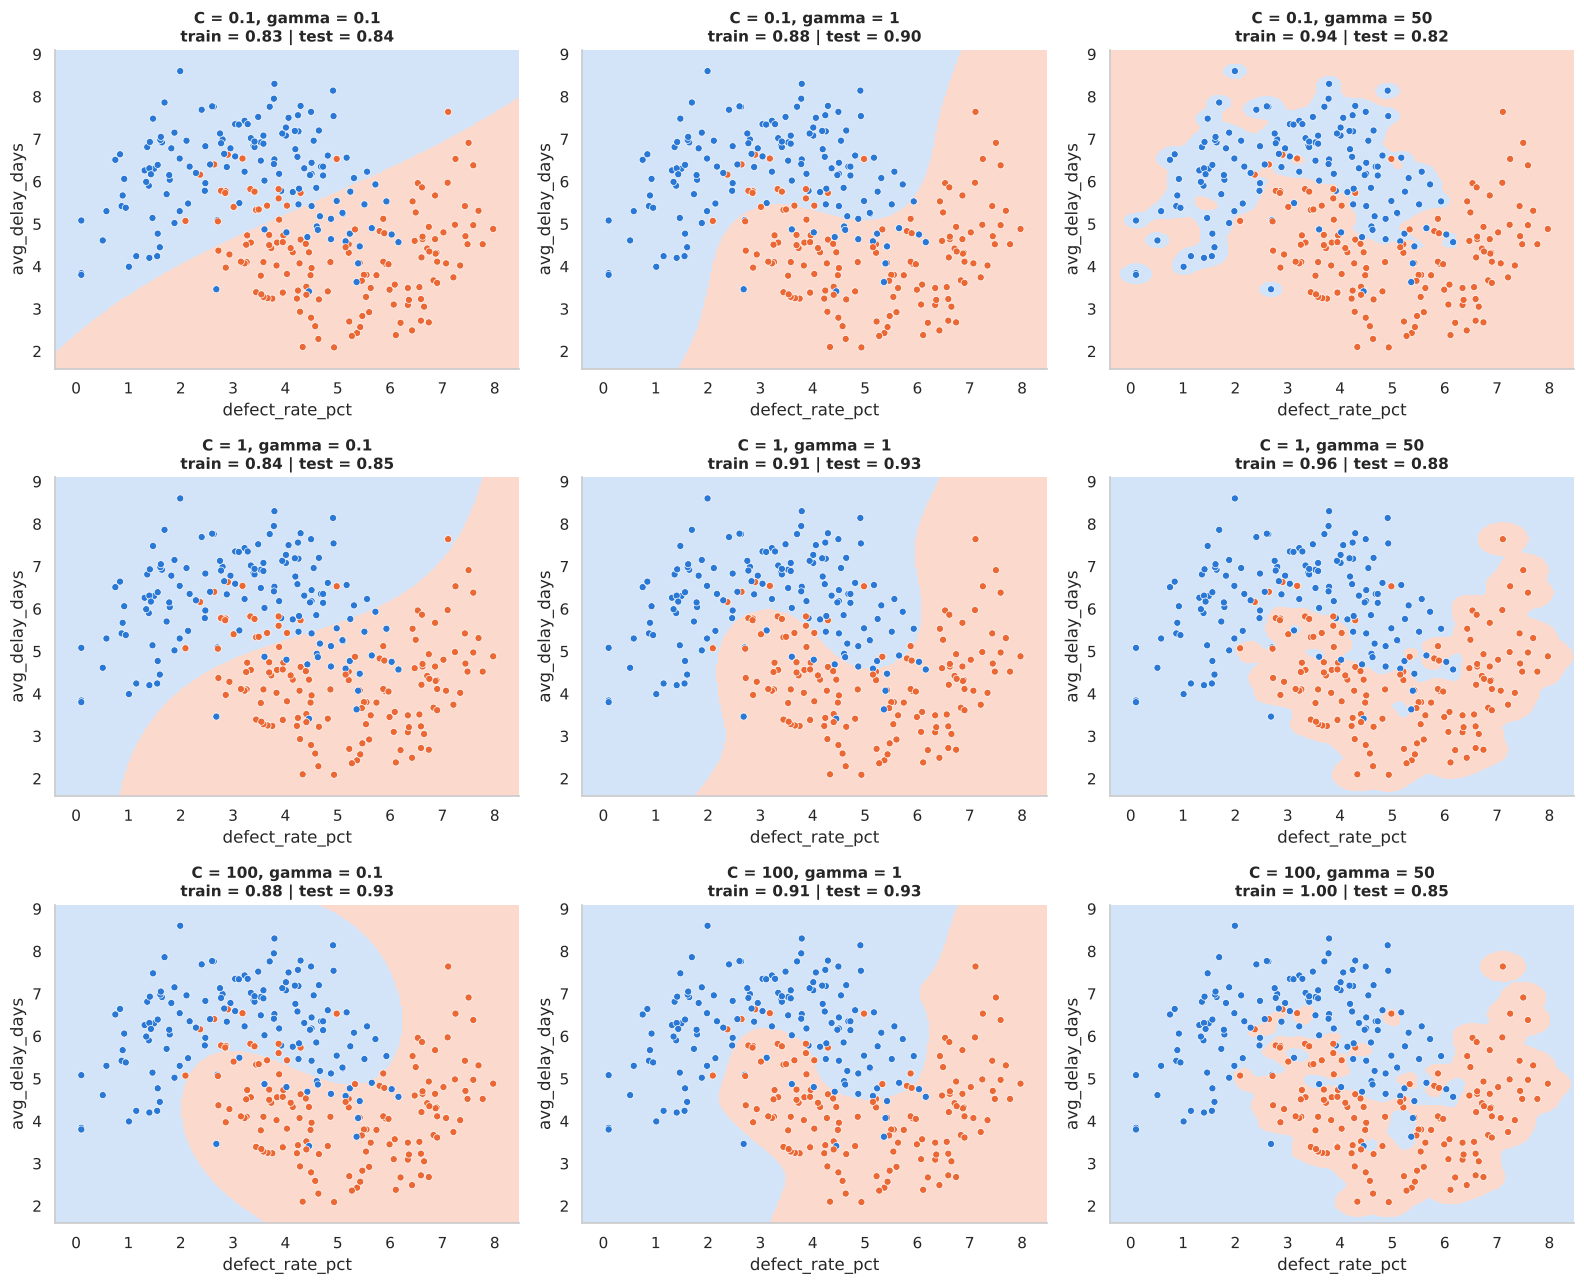

In [35]:
fig, axes = plt.subplots(3, 3, figsize=(16, 13))
for i, C in enumerate([0.1, 1, 100]):
    for j, g in enumerate([0.1, 1, 50]):
        svm_cg = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=C, gamma=g)).fit(audit_train[audit_features], audit_train["at_risk"])
        acc_tr = svm_cg.score(audit_train[audit_features], audit_train["at_risk"])
        acc_te = svm_cg.score(audit_test[audit_features], audit_test["at_risk"])
        plot_boundary(svm_cg, audit_train, audit_features, "at_risk", axes[i, j],
                      f"C = {C}, gamma = {g}\ntrain = {acc_tr:.2f} | test = {acc_te:.2f}")
plt.tight_layout(); plt.show()

**Question 34** &nbsp;·&nbsp; *Interpretation*

(a) Read each row from left to right: what is the effect of increasing `gamma`? (b) Read each column from top to bottom: what is the effect of increasing `C`? (c) Which combinations underfit, which ones overfit? Which one would you recommend? (d) We have just chosen hyper-parameters by looking at the **test** accuracy: why is it a bad practice (see Part 8)?

> **Your answer:** 

**Question 35** &nbsp;·&nbsp; *Implementation*

Fit an RBF SVM with **`C = 10`** and **`gamma = 2`** on the training audit data (with standardisation), print its training and test accuracy, and draw its frontier with `plot_svm`. Where does it stand compared with the nine models above?

> **Your answer:** 

In [ ]:
my_svm = make_pipeline(StandardScaler(), SVC(kernel="____", C=____, gamma=____))
my_svm.fit(audit_train[audit_features], audit_train["at_risk"])
print("Train accuracy:", round(my_svm.score(audit_train[audit_features], audit_train["at_risk"]), 3))
print("Test accuracy :", round(my_svm.score(audit_test[audit_features], audit_test["at_risk"]), 3))
plot_svm(my_svm, ____, audit_features, "at_risk", title="My SVM")
plt.show()

### 6.5 SVM in practice: units, cost and regression

**Units.** Like every method based on distances, an RBF SVM is very sensitive to the units of the variables (we will study this trap in detail with k-NN, Part 7.2). Let us fit an RBF SVM on the supplier default data (Dataset B) with and without standardisation, and compare it with the logistic regression (test AUC ≈ 0.825).

In [37]:
import time
svm_variants = {
    "RBF SVM, raw variables":          SVC(kernel="rbf", C=1, class_weight="balanced"),
    "RBF SVM, standardised variables": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1, class_weight="balanced")),
}
svm_rows = {}
for name, model in svm_variants.items():
    start = time.time()
    model.fit(Xb_train, yb_train)
    svm_rows[name] = {"test AUC": roc_auc_score(yb_test, model.decision_function(Xb_test)), "training time (s)": time.time() - start}
display(pd.DataFrame(svm_rows).T.round(3))

,test AUC,training time (s)
"RBF SVM, raw variables",0.774,0.260
"RBF SVM, standardised variables",0.815,0.186


**Question 36** &nbsp;·&nbsp; *Implementation*

(a) What is the effect of the standardisation? (b) With standardisation, try **`C = 0.1`** and **`C = 10`** (complete the loop). Which value gives the best AUC? Does a well-tuned RBF SVM beat the logistic regression (≈ 0.825) on this dataset? (Strictly speaking, `C` should be chosen by cross-validation, as in Part 8.)

> **Your answer:** 

In [ ]:
for C in [0.1, 10]:
    svm_b = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=____, class_weight="balanced"))
    svm_b.fit(Xb_train, yb_train)
    print(f"C = {C:>4}: test AUC = {roc_auc_score(yb_test, svm_b.decision_function(____)):.3f}")

**Cost.** Training an SVM requires comparing the observations **pairwise**: the computing time grows roughly with the *square* (or more) of the number of observations. A few thousand rows take a second; a few million shipments become impractical (specialised linear solvers such as `LinearSVC` then exist, but only for the linear kernel).

**Regression.** SVMs also exist for numerical targets (**SVR**, support vector regression): the street becomes a **tube** of width $\varepsilon$ around the predictions, errors smaller than $\varepsilon$ are ignored and larger errors are penalised with the cost `C`. We will use it in Part 11.4 for the lead time.

**Question 37** &nbsp;·&nbsp; *Discussion*

Give two **strengths** and three **weaknesses** of SVMs for a company that wants to score its suppliers or its shipments (think about the shape of the frontier, the rare events, the units, the computing time, the probabilities and the explanation of a decision to a purchasing committee). In which situation would you prefer an RBF SVM to a logistic regression?

> **Your answer:** 

## Part 7: k-Nearest Neighbours (k-NN): "tell me who your neighbours are"

### 7.1 The idea

To predict the outcome for a new observation, **look at the $k$ most similar observations in the training data** (its *nearest neighbours*) and let them vote (classification) or average their values (regression). There is no formula to learn: the model *is* the data.

The only real choice is the hyper-parameter **$k$**:
* $k=1$: the prediction copies the single closest example → very flexible, very sensitive to noise;
* $k$ large: the prediction averages many examples → smooth, stable, but may miss local patterns.

### Back to Dataset D: Supplier audit (2 variables)

We use again the supplier audit introduced in Part 6.4 (defect rate and average delivery delay, target `at_risk`), with the same train/test split.

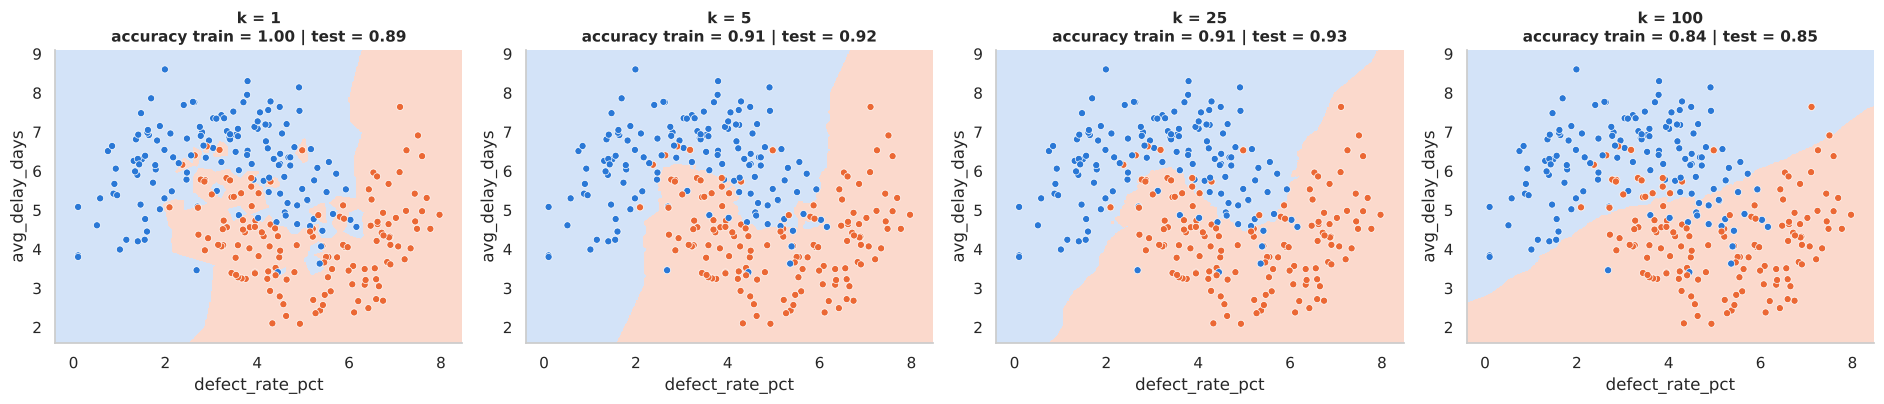

In [39]:
from sklearn.neighbors import KNeighborsClassifier

ks = [1, 5, 25, 100]
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
for ax, k in zip(axes, ks):
    knn = KNeighborsClassifier(n_neighbors=k).fit(audit_train[audit_features], audit_train["at_risk"])
    acc_tr = knn.score(audit_train[audit_features], audit_train["at_risk"])
    acc_te = knn.score(audit_test[audit_features], audit_test["at_risk"])
    plot_boundary(knn, audit_train, audit_features, "at_risk", ax, f"k = {k}\naccuracy train = {acc_tr:.2f} | test = {acc_te:.2f}")
plt.tight_layout(); plt.show()

**Question 38** &nbsp;·&nbsp; *Interpretation*

Describe how the coloured regions change when $k$ increases from 1 to 100. Which value of $k$ produces "islands" around isolated points? Which one produces a region that is too smooth? Relate your answer to the concepts of overfitting and underfitting.

> **Your answer:** 

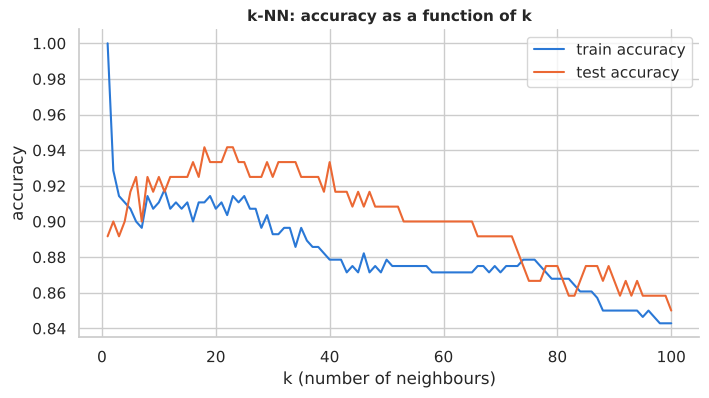

Best k on this test set: 18 | accuracy: 0.942


In [40]:
ks_all = range(1, 101)
acc_train, acc_test = [], []
for k in ks_all:
    knn = KNeighborsClassifier(n_neighbors=k).fit(audit_train[audit_features], audit_train["at_risk"])
    acc_train.append(knn.score(audit_train[audit_features], audit_train["at_risk"]))
    acc_test.append(knn.score(audit_test[audit_features], audit_test["at_risk"]))

plt.figure(figsize=(8, 4))
plt.plot(ks_all, acc_train, color=BLUE, label="train accuracy")
plt.plot(ks_all, acc_test, color=ORANGE, label="test accuracy")
plt.xlabel("k (number of neighbours)"); plt.ylabel("accuracy"); plt.legend(); plt.title("k-NN: accuracy as a function of k")
plt.show()
print("Best k on this test set:", ks_all[int(np.argmax(acc_test))], "| accuracy:", round(max(acc_test), 3))

**Question 39** &nbsp;·&nbsp; *Analysis*

Why is the training accuracy equal to 1 for $k=1$? Why is it *not* a good idea to pick $k$ by looking only at the best value of the test accuracy above? (We will see the right way in Part 8.)

> **Your answer:** 

**Question 40** &nbsp;·&nbsp; *Implementation*

Fit a k-NN classifier with **$k = 15$** on the training audit data and print its accuracy on the test data.

> **Your answer:** 

In [ ]:
knn15 = KNeighborsClassifier(n_neighbors=____)
knn15.fit(audit_train[audit_features], audit_train["____"])
print("Test accuracy:", knn15.score(audit_test[____], audit_test["at_risk"]))

### 7.2 A trap: k-NN depends on the *units* of the variables

"Closest" means a small **distance** computed on the features. If one feature is expressed in kilometres (hundreds) and another in percent (tens), the first one dominates the distance simply because of its unit. Consider three shipments:

In [42]:
three = pd.DataFrame({"distance_km": [500, 600, 500], "hub_load": [50, 50, 90]}, index=["Shipment 1", "Shipment 2", "Shipment 3"])
display(three)
d12 = np.sqrt(((three.loc["Shipment 1"] - three.loc["Shipment 2"]) ** 2).sum())
d13 = np.sqrt(((three.loc["Shipment 1"] - three.loc["Shipment 3"]) ** 2).sum())
print(f"Distance(1, 2) = {d12:.0f}   |   Distance(1, 3) = {d13:.0f}")

,distance_km,hub_load
Shipment 1,500,50
Shipment 2,600,50
Shipment 3,500,90


Distance(1, 2) = 100   |   Distance(1, 3) = 40


**Question 41** &nbsp;·&nbsp; *Interpretation*

For a logistics manager, which shipment is closer to Shipment 1: Shipment 2 (100 km more) or Shipment 3 (a hub at 90% instead of 50%)? Which one does the *raw distance* consider as the closest? What is the problem and how could we correct it?

> **Your answer:** 

The usual cure is **standardisation**: subtract the mean and divide by the standard deviation of each feature, so that all variables have a comparable scale. We test it on Dataset A to predict `late`. We first build the table of features for the classification task (this time `promised_days` **is** included: it is known before the shipment leaves and `late` is defined relative to it).

In [43]:
from sklearn.model_selection import cross_val_score

X_late = X_ship.assign(promised_days=shipments["promised_days"])       # features known before shipping
y_late = shipments["late"]                                              # target: 1 = late
Xl_train, Xl_test, yl_train, yl_test = train_test_split(X_late, y_late, test_size=0.25, stratify=y_late, random_state=RANDOM_STATE)

knn_raw    = KNeighborsClassifier(n_neighbors=15)
knn_scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15))

rows = {}
for name, model in [("k-NN, raw features", knn_raw), ("k-NN, standardised features", knn_scaled)]:
    model.fit(Xl_train, yl_train)
    rows[name] = {"accuracy": accuracy_score(yl_test, model.predict(Xl_test)),
                  "AUC": roc_auc_score(yl_test, model.predict_proba(Xl_test)[:, 1])}
display(pd.DataFrame(rows).T.round(3))
print(f"Share of late deliveries in the test set (a model predicting 'never late' would get {1 - yl_test.mean():.1%} accuracy)")

,accuracy,AUC
"k-NN, raw features",0.799,0.786
"k-NN, standardised features",0.807,0.889


Share of late deliveries in the test set (a model predicting 'never late' would get 71.7% accuracy)


**Question 42** &nbsp;·&nbsp; *Interpretation*

Compare the two k-NN models. What is the effect of standardising the features? Which feature(s) was (were) dominating the distance in the first model?

> **Your answer:** 

**Question 43** &nbsp;·&nbsp; *Analysis*

Give two **advantages** and two **drawbacks** of k-NN for a company that would like to use it in production on millions of shipments with dozens of variables (think about prediction speed, memory, irrelevant variables, interpretability).

> **Your answer:** 

## Part 8: Cross-validation and hyper-parameter tuning

### 8.1 A single split is a lottery

In Part 7 we picked $k$ by looking at the test set. That is **cheating**: the test set is supposed to be our *final exam*, used once, to estimate how the model will behave on future data. If we use it to choose the model, it is no longer independent, and our performance estimate becomes too optimistic.

Moreover, a single train/test split depends on **which observations happen to land in the test set**. Let us repeat the split 30 times with a different random seed, with the same model ($k=15$):

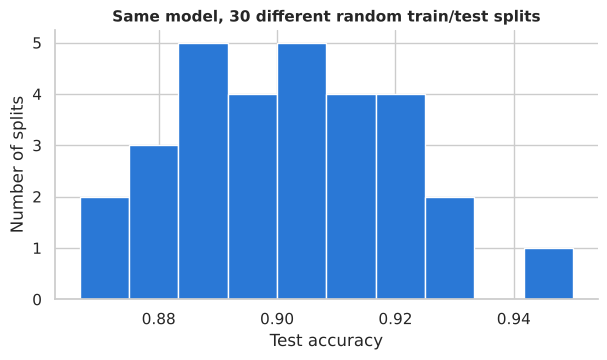

Accuracy ranges from 0.867 to 0.950 (standard deviation 0.019)


In [44]:
accs = []
for seed in range(30):
    tr, te = train_test_split(audit, test_size=0.3, stratify=audit["at_risk"], random_state=seed)
    m = KNeighborsClassifier(n_neighbors=15).fit(tr[audit_features], tr["at_risk"])
    accs.append(m.score(te[audit_features], te["at_risk"]))

plt.figure(figsize=(7, 3.5))
plt.hist(accs, bins=10, color=BLUE, edgecolor="white")
plt.xlabel("Test accuracy"); plt.ylabel("Number of splits"); plt.title("Same model, 30 different random train/test splits")
plt.show()
print(f"Accuracy ranges from {min(accs):.3f} to {max(accs):.3f} (standard deviation {np.std(accs):.3f})")

**Question 44** &nbsp;·&nbsp; *Interpretation*

What do you conclude about the reliability of the accuracy measured on **one** single train/test split? How would you report the performance of this model to your manager?

> **Your answer:** 

### 8.2 K-fold cross-validation

The idea: **use all the training data, in turn, as a validation set.**

1. Split the training data in $K$ blocks (*folds*) — here $K=5$.
2. Train the model on $K-1$ folds and measure the performance on the remaining fold (the *validation* fold).
3. Repeat $K$ times, each fold playing the role of validation once.
4. The **cross-validation score** is the average of the $K$ scores (and their standard deviation tells how stable it is).

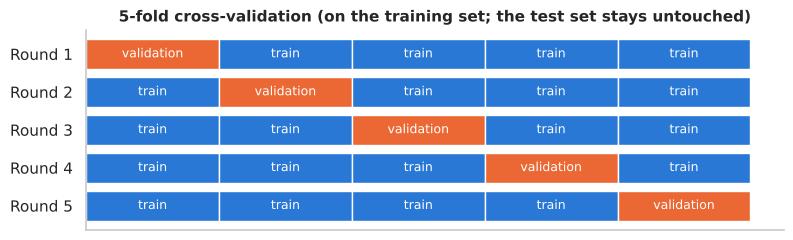

In [45]:
fig, ax = plt.subplots(figsize=(9, 2.6))
K = 5
for i in range(K):
    for j in range(K):
        ax.barh(i, 1, left=j, color=ORANGE if i == j else BLUE, edgecolor="white", height=.8)
        ax.text(j + .5, i, "validation" if i == j else "train", ha="center", va="center", color="white", fontsize=9)
ax.set_yticks(range(K)); ax.set_yticklabels([f"Round {i+1}" for i in range(K)]); ax.invert_yaxis()
ax.set_xticks([]); ax.set_title("5-fold cross-validation (on the training set; the test set stays untouched)")
ax.grid(False); plt.show()

In [46]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)    # "stratified": same class balance in each fold
scores = cross_val_score(KNeighborsClassifier(n_neighbors=15), audit_train[audit_features], audit_train["at_risk"], cv=cv5, scoring="accuracy")
print("Accuracy of each of the 5 rounds:", scores.round(3))
print(f"Cross-validation score: {scores.mean():.3f} (± {scores.std():.3f})")

Accuracy of each of the 5 rounds: [0.911 0.875 0.964 0.857 0.893]
Cross-validation score: 0.900 (± 0.037)


**Question 45** &nbsp;·&nbsp; *Implementation*

Repeat the cross-validation with **10 folds** instead of 5 for the same model. Does the average score change a lot? Does the standard deviation change?

> **Your answer:** 

In [ ]:
cv10 = StratifiedKFold(n_splits=____, shuffle=True, random_state=RANDOM_STATE)
scores10 = cross_val_score(KNeighborsClassifier(n_neighbors=15), audit_train[audit_features], audit_train["at_risk"], cv=____, scoring="accuracy")
print(f"10-fold CV score: {scores10.mean():.3f} (± {scores10.std():.3f})")

### 8.3 Choosing hyper-parameters with `GridSearchCV`

A **hyper-parameter** is a setting that we choose before training (here: $k$ and the weighting of neighbours; later: the depth of a tree, the number of trees…). `GridSearchCV` automates the following procedure:

> for each combination of hyper-parameters in a grid → compute the cross-validation score on the **training set** → keep the best combination → retrain on the whole training set.

The test set is then used **once**, to evaluate the chosen model.

Best hyper-parameters: {'n_neighbors': 19, 'weights': 'uniform'}
Best cross-validation accuracy: 0.907
Test accuracy of the selected model (used once): 0.933


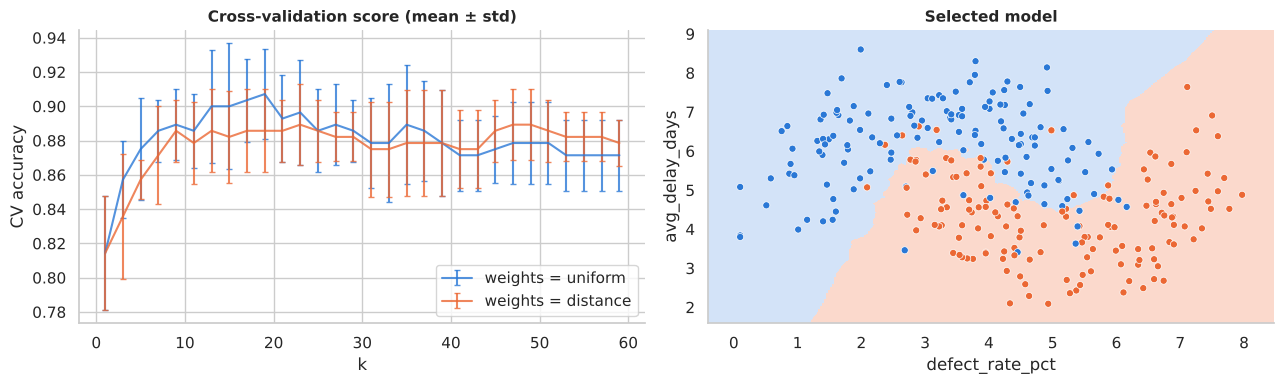

In [48]:
from sklearn.model_selection import GridSearchCV

param_grid = {"n_neighbors": list(range(1, 60, 2)), "weights": ["uniform", "distance"]}
grid = GridSearchCV(KNeighborsClassifier(), param_grid, cv=cv5, scoring="accuracy")
grid.fit(audit_train[audit_features], audit_train["at_risk"])

print("Best hyper-parameters:", grid.best_params_)
print(f"Best cross-validation accuracy: {grid.best_score_:.3f}")
print(f"Test accuracy of the selected model (used once): {grid.score(audit_test[audit_features], audit_test['at_risk']):.3f}")

res = pd.DataFrame(grid.cv_results_)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for w, color in [("uniform", BLUE), ("distance", ORANGE)]:
    sub = res[res["param_weights"] == w]
    axes[0].errorbar(sub["param_n_neighbors"], sub["mean_test_score"], yerr=sub["std_test_score"], color=color, label=f"weights = {w}", alpha=.8, capsize=2)
axes[0].set_xlabel("k"); axes[0].set_ylabel("CV accuracy"); axes[0].set_title("Cross-validation score (mean ± std)"); axes[0].legend()
plot_boundary(grid.best_estimator_, audit_train, audit_features, "at_risk", axes[1], "Selected model")
plt.tight_layout(); plt.show()

**Question 46** &nbsp;·&nbsp; *Interpretation*

Look at the left plot. Is there one single best value of $k$ or a whole zone of "equally good" values (compare the differences between values with the error bars)? What does it imply for the precision with which you need to tune the hyper-parameter?

> **Your answer:** 

**Question 47** &nbsp;·&nbsp; *Analysis*

(a) Why must the test set not be used inside `GridSearchCV`? (b) Imagine that you standardise **all** the data *before* splitting it into folds. Why would the cross-validation score be slightly too optimistic? (This is another form of *data leakage*; the tool `Pipeline` avoids it by fitting the scaler on the training folds only.)

> **Your answer:** 

**Question 48** &nbsp;·&nbsp; *Analysis*

For the **daily demand** data (Dataset C), observations are ordered in time and the goal is to forecast the future. Why could a *shuffled* K-fold cross-validation give an overly optimistic estimate? What kind of split would be more realistic?

> **Your answer:** 

## Part 9: Decision trees

### 9.1 The idea: a flowchart learnt from data

A decision tree is a **sequence of yes/no questions** about the features, like the checklist of an experienced planner:

```
Is hub_load ≤ 75% ?
 ├─ yes → Is distance ≤ 800 km ?  → ... 
 └─ no  → predict "late"
```

At the **end of each branch** (a *leaf*), the tree predicts the **majority class** of the training observations that reached it (classification) or their **average value** (regression).

The algorithm builds the tree **greedily**, from the top: at each node it tests *every feature and every possible threshold* and keeps the question that produces the **purest** groups. This notion of purity is measured by the **Gini impurity**.

### Gini impurity

For a node containing observations of $K$ classes, with proportions $p_1,\dots,p_K$:

$$G = 1-\sum_{k=1}^{K} p_k^2$$

* a **pure** node (only one class) has $G=0$;
* a node with 50% late / 50% on-time has $G = 1-0.5^2-0.5^2 = 0.5$ (maximum for two classes).

When a node of $n$ observations is split into a left child ($n_L$ observations) and a right child ($n_R$), the quality of the split is measured by the **gain** (decrease of impurity):

$$\text{Gain} = G_{\text{parent}} - \left(\frac{n_L}{n}G_{\text{left}}+\frac{n_R}{n}G_{\text{right}}\right)$$

The algorithm picks the split with the largest gain. *(An alternative measure, the **entropy** $-\sum_k p_k\log_2 p_k$, behaves almost the same way.)*

### A toy example you can follow by hand

Ten shipments, two features, and the outcome `late`.

,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10
distance_km,120.0,200.0,350.0,400.0,500.0,650.0,700.0,800.0,900.0,150.0
hub_load,45.0,85.0,50.0,90.0,60.0,88.0,40.0,80.0,55.0,70.0
late,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
lead_time,3.1,6.6,3.8,7.4,4.5,7.1,5.2,8.0,7.6,3.9


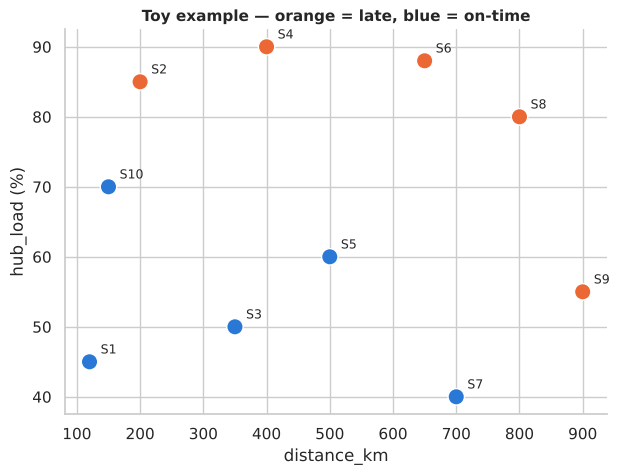

In [49]:
tiny = pd.DataFrame({
    "distance_km": [120, 200, 350, 400, 500, 650, 700, 800, 900, 150],
    "hub_load":    [ 45,  85,  50,  90,  60,  88,  40,  80,  55,  70],
    "late":        [  0,   1,   0,   1,   0,   1,   0,   1,   1,   0],
    "lead_time":   [3.1, 6.6, 3.8, 7.4, 4.5, 7.1, 5.2, 8.0, 7.6, 3.9]},
    index=[f"S{i}" for i in range(1, 11)])
display(tiny.T)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(tiny["distance_km"], tiny["hub_load"], c=np.where(tiny["late"] == 1, ORANGE, BLUE), s=140, edgecolor="white")
for name, row in tiny.iterrows():
    ax.annotate(name, (row["distance_km"], row["hub_load"]), textcoords="offset points", xytext=(8, 6), fontsize=9)
ax.set_xlabel("distance_km"); ax.set_ylabel("hub_load (%)"); ax.set_title("Toy example — orange = late, blue = on-time")
plt.show()

Now the code that computes the Gini impurity and the gain of any candidate rule *"feature ≤ threshold"*.

In [50]:
def gini(labels):
    # Gini impurity of a set of labels (0 = pure, 0.5 = 50/50)
    labels = np.asarray(labels)
    if len(labels) == 0:
        return 0.0
    p = np.bincount(labels, minlength=2) / len(labels)
    return 1 - np.sum(p ** 2)

def split_gain(df, feature, threshold, target="late", verbose=False):
    # Gain of the rule "feature <= threshold": Gini(parent) - weighted average of the Gini of the two children
    left  = df[df[feature] <= threshold][target]
    right = df[df[feature] >  threshold][target]
    weighted = len(left) / len(df) * gini(left) + len(right) / len(df) * gini(right)
    if verbose:
        print(f"Rule '{feature} <= {threshold}': left = {len(left)} obs ({left.sum()} late), Gini = {gini(left):.3f} | "
              f"right = {len(right)} obs ({right.sum()} late), Gini = {gini(right):.3f} | weighted Gini = {weighted:.3f}")
    return gini(df[target]) - weighted

print("Gini of a pure node [0,0,0,0]      :", gini([0, 0, 0, 0]))
print("Gini of a 50/50 node [0,1,0,1]     :", gini([0, 1, 0, 1]))
print("Gini of the whole toy dataset      :", gini(tiny["late"]))
print("Entropy of the whole toy dataset   :", 1.0, "(5 late / 5 on-time -> maximum disorder)")
print()
gain = split_gain(tiny, "hub_load", 75, verbose=True)
print(f"Gain of the rule 'hub_load <= 75'  : {gain:.3f}")

Gini of a pure node [0,0,0,0]      : 0.0
Gini of a 50/50 node [0,1,0,1]     : 0.5
Gini of the whole toy dataset      : 0.5
Entropy of the whole toy dataset   : 1.0 (5 late / 5 on-time -> maximum disorder)

Rule 'hub_load <= 75': left = 6 obs (1 late), Gini = 0.278 | right = 4 obs (4 late), Gini = 0.000 | weighted Gini = 0.167
Gain of the rule 'hub_load <= 75'  : 0.333


**Question 49** &nbsp;·&nbsp; *Analysis*

Compute **by hand** (with the formula, then check with `gini` in a code cell if you wish) the Gini impurity of: (a) a node with 3 late shipments and 1 on-time shipment; (b) a node with 8 on-time and 2 late shipments; (c) a node containing only late shipments. Which node is the "purest"?

> **Your answer:** 

**Testing all candidate rules.** For a numerical feature, the algorithm tries the **midpoint between two consecutive observed values** as a threshold. The table below lists every candidate for both features, with its gain.

,feature,threshold,left: n (late),right: n (late),Gini left,Gini right,weighted Gini,gain
0,hub_load,75.0,6 (1),4 (4),0.278,0.000,0.167,0.333
1,hub_load,52.5,3 (0),7 (5),0.000,0.408,0.286,0.214
2,hub_load,82.5,7 (2),3 (3),0.408,0.000,0.286,0.214
3,hub_load,65.0,5 (1),5 (4),0.320,0.320,0.320,0.180
4,distance_km,750.0,8 (3),2 (2),0.469,0.000,0.375,0.125
5,distance_km,175.0,2 (0),8 (5),0.000,0.469,0.375,0.125
6,hub_load,47.5,2 (0),8 (5),0.000,0.469,0.375,0.125
7,hub_load,86.5,8 (3),2 (2),0.469,0.000,0.375,0.125


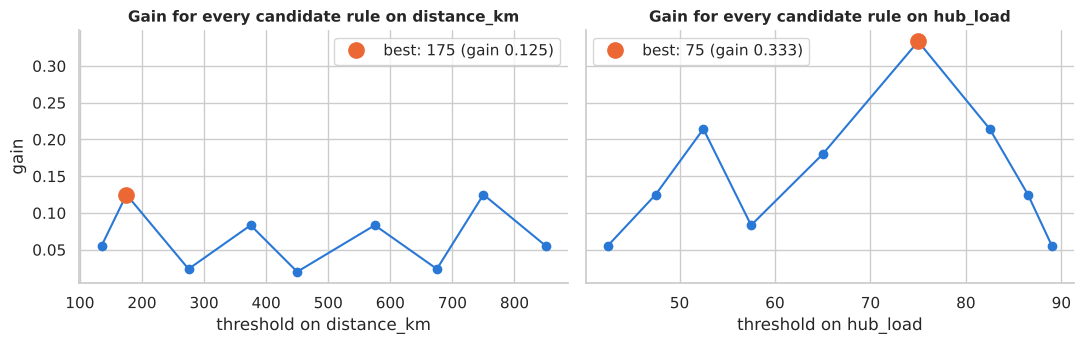

In [51]:
rows = []
for feature in ["distance_km", "hub_load"]:
    values = np.sort(tiny[feature].unique())
    for thr in (values[:-1] + values[1:]) / 2:
        left, right = tiny[tiny[feature] <= thr], tiny[tiny[feature] > thr]
        rows.append({"feature": feature, "threshold": thr,
                     "left: n (late)": f"{len(left)} ({left['late'].sum()})", "right: n (late)": f"{len(right)} ({right['late'].sum()})",
                     "Gini left": gini(left["late"]), "Gini right": gini(right["late"]),
                     "weighted Gini": (len(left) * gini(left["late"]) + len(right) * gini(right["late"])) / len(tiny),
                     "gain": split_gain(tiny, feature, thr)})
candidates = pd.DataFrame(rows).sort_values("gain", ascending=False)
display(candidates.head(8).round(3).reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, feature in zip(axes, ["distance_km", "hub_load"]):
    sub = candidates[candidates["feature"] == feature].sort_values("threshold")
    ax.plot(sub["threshold"], sub["gain"], "o-", color=BLUE)
    best = sub.loc[sub["gain"].idxmax()]
    ax.plot(best["threshold"], best["gain"], "o", color=ORANGE, ms=11, label=f"best: {best['threshold']:.0f} (gain {best['gain']:.3f})")
    ax.set_xlabel(f"threshold on {feature}"); ax.set_title(f"Gain for every candidate rule on {feature}"); ax.legend()
axes[0].set_ylabel("gain"); plt.tight_layout(); plt.show()

**Question 50** &nbsp;·&nbsp; *Interpretation*

Which rule does the algorithm choose for the **first split**? Why is it better than the best rule on `distance_km`? Describe in words the two groups it creates and the Gini impurity of each.

> **Your answer:** 

**Question 51** &nbsp;·&nbsp; *Implementation*

Use the function `split_gain` to compute the gain of the rule **`distance_km <= 600`**, with the details printed (`verbose=True`). Is it better or worse than the best rule found above?

> **Your answer:** 

In [ ]:
gain_600 = split_gain(tiny, "____", ____, verbose=True)
print("Gain:", round(gain_600, 3))

Let us now ask scikit-learn to grow a tree (depth 2) on these ten shipments and check that it finds **exactly** what we computed by hand. In each box, `gini` is the impurity of the node, `samples` its size, `value` the number of [on-time, late] shipments.

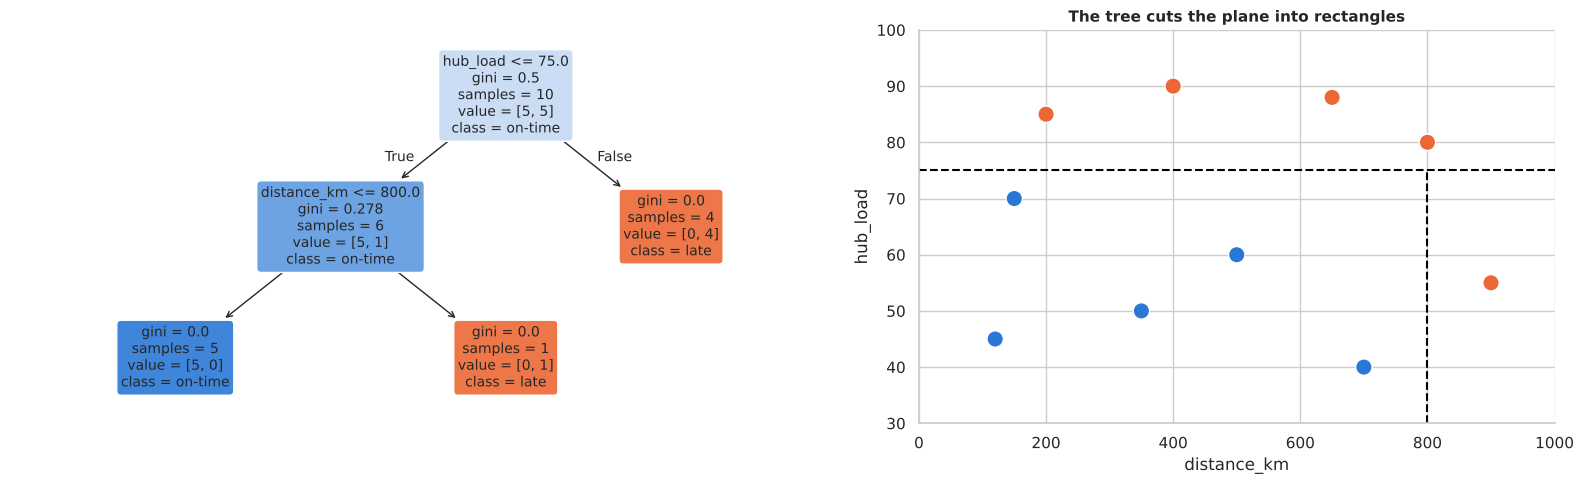

|--- hub_load <= 75.00
|   |--- distance_km <= 800.00
|   |   |--- class: 0
|   |--- distance_km >  800.00
|   |   |--- class: 1
|--- hub_load >  75.00
|   |--- class: 1



In [53]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text

tiny_features = ["distance_km", "hub_load"]
tree_tiny = DecisionTreeClassifier(max_depth=2, criterion="gini", random_state=0).fit(tiny[tiny_features], tiny["late"])

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1.3, 1]})
draw_tree(tree_tiny, tiny_features, ax=axes[0], fontsize=10)

# Same tree drawn on the plane: each split is a straight line parallel to an axis
t = tree_tiny.tree_
axes[1].scatter(tiny["distance_km"], tiny["hub_load"], c=np.where(tiny["late"] == 1, ORANGE, BLUE), s=140, edgecolor="white")
xmax, ymax = 1000, 100
def draw_split(node, x0, x1, y0, y1):
    if t.children_left[node] == -1: return
    thr, name = t.threshold[node], tiny_features[t.feature[node]]
    if name == "distance_km":
        axes[1].vlines(thr, y0, y1, color="black", ls="--"); 
        draw_split(t.children_left[node], x0, thr, y0, y1); draw_split(t.children_right[node], thr, x1, y0, y1)
    else:
        axes[1].hlines(thr, x0, x1, color="black", ls="--")
        draw_split(t.children_left[node], x0, x1, y0, thr); draw_split(t.children_right[node], x0, x1, thr, y1)
draw_split(0, 0, xmax, 30, ymax)
axes[1].set_xlim(0, xmax); axes[1].set_ylim(30, ymax)
axes[1].set_xlabel("distance_km"); axes[1].set_ylabel("hub_load"); axes[1].set_title("The tree cuts the plane into rectangles")
plt.tight_layout(); plt.show()

print(export_text(tree_tiny, feature_names=tiny_features))

**Question 52** &nbsp;·&nbsp; *Analysis*

Use the tree above (or the printed rules) to predict, **without running any code**, whether each of these new shipments will be late: (A) 450 km with a hub load of 82%; (B) 880 km with a hub load of 60%; (C) 300 km with a hub load of 50%. Explain the path followed by each shipment.

> **Your answer:** 

### 9.2 Regression trees: the same idea with the **variance**

When the target is a number (the lead time), purity is measured by the **variance** (or mean squared error) of the target in a node: a node is "pure" when all its observations have almost the same lead time. The gain of a split is the **decrease of variance**

$$\text{Gain} = \text{Var}_{\text{parent}} - \left(\frac{n_L}{n}\text{Var}_{\text{left}}+\frac{n_R}{n}\text{Var}_{\text{right}}\right)$$

and the **prediction of a leaf is the mean** of the target of its observations. Same toy dataset, now with `lead_time`:

In [54]:
def variance_gain(df, feature, threshold, target="lead_time"):
    left  = df[df[feature] <= threshold][target]
    right = df[df[feature] >  threshold][target]
    weighted = len(left) / len(df) * left.var(ddof=0) + len(right) / len(df) * right.var(ddof=0)
    return df[target].var(ddof=0) - weighted

print(f"Variance of the lead time in the whole dataset: {tiny['lead_time'].var(ddof=0):.3f}")
rows = []
for feature in tiny_features:
    values = np.sort(tiny[feature].unique())
    for thr in (values[:-1] + values[1:]) / 2:
        rows.append({"feature": feature, "threshold": thr, "variance gain": variance_gain(tiny, feature, thr)})
cand_reg = pd.DataFrame(rows).sort_values("variance gain", ascending=False)
display(cand_reg.head(5).round(3).reset_index(drop=True))

reg_tiny = DecisionTreeRegressor(max_depth=1, random_state=0).fit(tiny[tiny_features], tiny["lead_time"])
print(export_text(reg_tiny, feature_names=tiny_features))
left_mean  = tiny[tiny["hub_load"] <= 75]["lead_time"].mean()
right_mean = tiny[tiny["hub_load"] >  75]["lead_time"].mean()
print(f"Mean lead time when hub_load <= 75: {left_mean:.2f} days | when hub_load > 75: {right_mean:.2f} days")

Variance of the lead time in the whole dataset: 2.986


,feature,threshold,variance gain
0,hub_load,75.0,1.612
1,distance_km,375.0,1.251
2,distance_km,175.0,1.232
3,hub_load,52.5,1.219
4,distance_km,750.0,1.082


|--- hub_load <= 75.00
|   |--- value: [4.68]
|--- hub_load >  75.00
|   |--- value: [7.28]

Mean lead time when hub_load <= 75: 4.68 days | when hub_load > 75: 7.28 days


**Question 53** &nbsp;·&nbsp; *Interpretation*

Which rule does the regression tree select, and what does it predict for a shipment leaving a hub loaded at 85%, and for one leaving a hub loaded at 50%? Check that these predictions are the **averages** of the lead times in each group.

> **Your answer:** 

**Question 54** &nbsp;·&nbsp; *Implementation*

Ask the regression tree to predict the lead time of a new shipment of 500 km leaving a hub loaded at 82%.

> **Your answer:** 

In [ ]:
new = pd.DataFrame({"distance_km": [____], "hub_load": [____]})
print("Predicted lead time:", reg_tiny.____(new))

### 9.3 Controlling the complexity of a tree (Dataset D)

A tree that is allowed to grow without limit keeps splitting until every leaf is pure — it **memorises** the training data (overfitting). We limit its complexity with **hyper-parameters**:

| Hyper-parameter | Meaning |
|---|---|
| `max_depth` | maximum number of successive questions (levels) |
| `min_samples_split` | a node with fewer observations is not split any more |
| `min_samples_leaf` | every leaf must contain at least this number of observations |

Back to the supplier audit (Dataset D), where we can *see* the regions learnt by the tree.

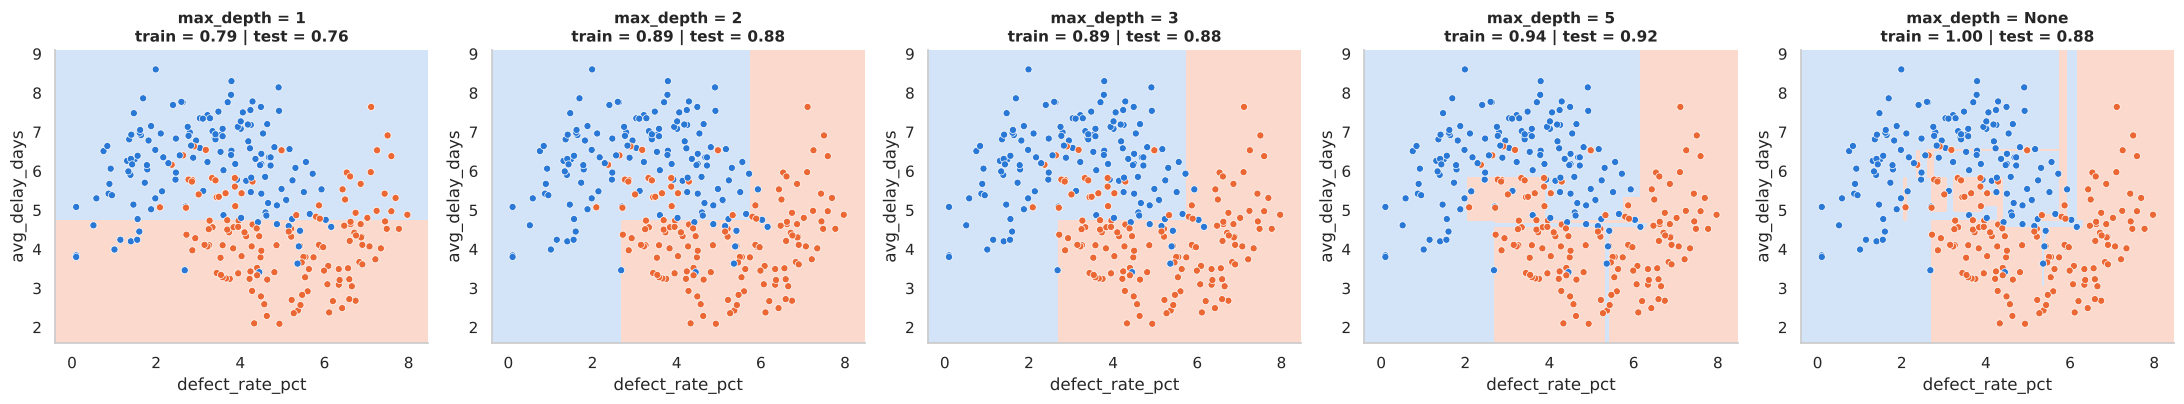

In [56]:
depths = [1, 2, 3, 5, None]
fig, axes = plt.subplots(1, 5, figsize=(22, 4.2))
for ax, d in zip(axes, depths):
    tree = DecisionTreeClassifier(max_depth=d, random_state=0).fit(audit_train[audit_features], audit_train["at_risk"])
    acc_tr = tree.score(audit_train[audit_features], audit_train["at_risk"])
    acc_te = tree.score(audit_test[audit_features], audit_test["at_risk"])
    plot_boundary(tree, audit_train, audit_features, "at_risk", ax, f"max_depth = {d}\ntrain = {acc_tr:.2f} | test = {acc_te:.2f}")
plt.tight_layout(); plt.show()

**Question 55** &nbsp;·&nbsp; *Interpretation*

(a) What is the shape of the regions produced by a tree (compare with k-NN)? Why? (b) How does the training accuracy evolve with `max_depth`, and the test accuracy? (c) What depth would you recommend?

> **Your answer:** 

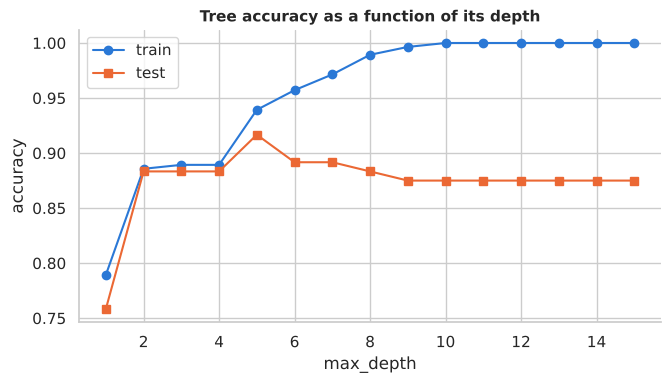

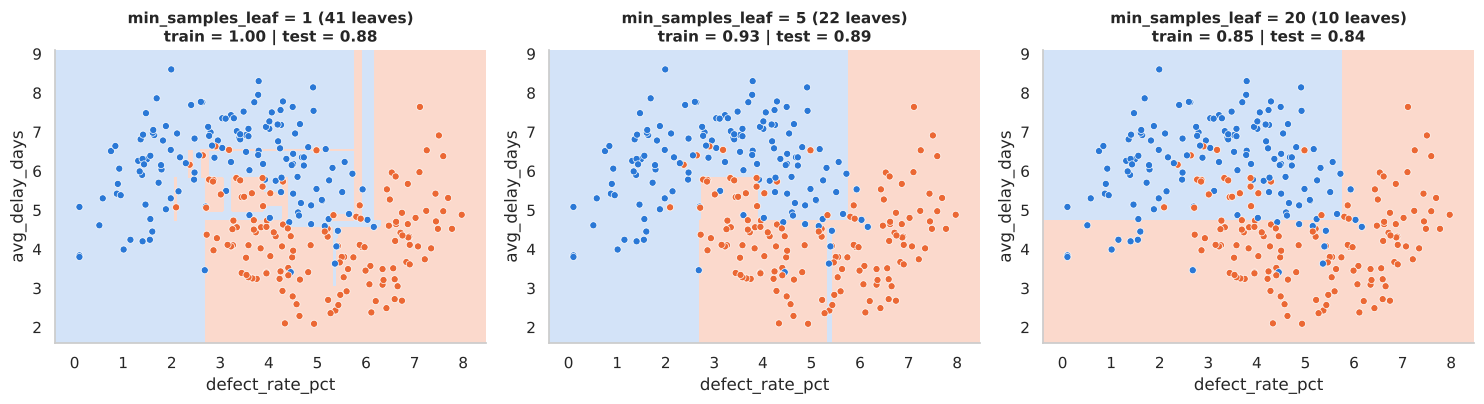

In [57]:
depth_range = range(1, 16)
tr, te = [], []
for d in depth_range:
    tree = DecisionTreeClassifier(max_depth=d, random_state=0).fit(audit_train[audit_features], audit_train["at_risk"])
    tr.append(tree.score(audit_train[audit_features], audit_train["at_risk"]))
    te.append(tree.score(audit_test[audit_features], audit_test["at_risk"]))
plt.figure(figsize=(7.5, 3.8))
plt.plot(depth_range, tr, "o-", color=BLUE, label="train"); plt.plot(depth_range, te, "s-", color=ORANGE, label="test")
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.title("Tree accuracy as a function of its depth"); plt.legend(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, leaf in zip(axes, [1, 5, 20]):
    tree = DecisionTreeClassifier(max_depth=None, min_samples_leaf=leaf, random_state=0).fit(audit_train[audit_features], audit_train["at_risk"])
    plot_boundary(tree, audit_train, audit_features, "at_risk", ax,
                  f"min_samples_leaf = {leaf} ({tree.get_n_leaves()} leaves)\ntrain = {tree.score(audit_train[audit_features], audit_train['at_risk']):.2f} | test = {tree.score(audit_test[audit_features], audit_test['at_risk']):.2f}")
plt.tight_layout(); plt.show()

**Question 56** &nbsp;·&nbsp; *Analysis*

Why does a tree with `max_depth=None` get 100% accuracy on the training data but a lower score on the test data? Explain in terms of *leaves* and *noise*. Then compare `min_samples_leaf=1`, `5` and `20`: which one corresponds to the "simplest" model? Which one has the best test accuracy, and what does it tell you about the choice of this hyper-parameter?

> **Your answer:** 

**Question 57** &nbsp;·&nbsp; *Implementation*

Fit a tree with `max_depth=4` **and** `min_samples_leaf=10`, print its training and test accuracy, and draw its decision regions.

> **Your answer:** 

In [ ]:
tree4 = DecisionTreeClassifier(max_depth=____, min_samples_leaf=____, random_state=0)
tree4.fit(audit_train[audit_features], audit_train["at_risk"])
print("Train accuracy:", round(tree4.score(audit_train[audit_features], audit_train["at_risk"]), 3))
print("Test accuracy :", round(tree4.score(audit_test[audit_features], audit_test["____"]), 3))
plot_boundary(tree4, audit_train, audit_features, "at_risk", title="My tree")
plt.show()

### 9.4 A classification tree for late deliveries (Dataset A)

We return to the shipments with the target `late` (using the table `X_late` built in Part 7). Because only ~28% of the deliveries are late, we select the hyper-parameters with the **AUC** rather than the accuracy.

First, an **unconstrained tree** (the "memoriser") and then a tree whose complexity is chosen by **cross-validation**.

Unconstrained tree: depth = 19, leaves = 235
  AUC train = 1.000 | AUC test = 0.790



Best hyper-parameters: {'max_depth': 8, 'min_samples_leaf': 20} (CV AUC = 0.932)
Tuned tree: depth = 8, leaves = 42
  AUC train = 0.962 | AUC test = 0.920

               precision    recall  f1-score   support

     on-time       0.89      0.92      0.90       538
        late       0.77      0.70      0.74       212

    accuracy                           0.86       750
   macro avg       0.83      0.81      0.82       750
weighted avg       0.85      0.86      0.86       750



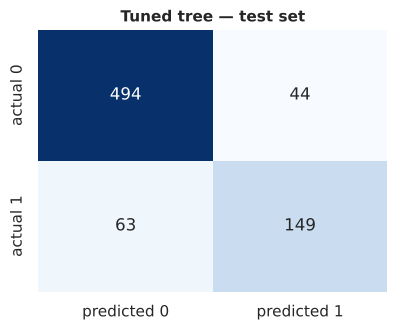

In [59]:
tree_full = DecisionTreeClassifier(random_state=0).fit(Xl_train, yl_train)
print(f"Unconstrained tree: depth = {tree_full.get_depth()}, leaves = {tree_full.get_n_leaves()}")
print(f"  AUC train = {roc_auc_score(yl_train, tree_full.predict_proba(Xl_train)[:, 1]):.3f} | AUC test = {roc_auc_score(yl_test, tree_full.predict_proba(Xl_test)[:, 1]):.3f}")

param_grid = {"max_depth": [2, 3, 4, 5, 6, 8, 10, None], "min_samples_leaf": [1, 5, 10, 20, 40]}
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gs_tree = GridSearchCV(DecisionTreeClassifier(random_state=0), param_grid, scoring="roc_auc", cv=cv5)
gs_tree.fit(Xl_train, yl_train)
tree_late = gs_tree.best_estimator_

print("\nBest hyper-parameters:", gs_tree.best_params_, f"(CV AUC = {gs_tree.best_score_:.3f})")
print(f"Tuned tree: depth = {tree_late.get_depth()}, leaves = {tree_late.get_n_leaves()}")
print(f"  AUC train = {roc_auc_score(yl_train, tree_late.predict_proba(Xl_train)[:, 1]):.3f} | AUC test = {roc_auc_score(yl_test, tree_late.predict_proba(Xl_test)[:, 1]):.3f}")

from sklearn.metrics import classification_report
pred = tree_late.predict(Xl_test)
print("\n", classification_report(yl_test, pred, target_names=["on-time", "late"]))
plt.figure(figsize=(4.5, 3.4)); show_confusion(yl_test, pred, title="Tuned tree — test set"); plt.show()

**Question 58** &nbsp;·&nbsp; *Interpretation*

Compare the unconstrained tree with the tuned tree (depth, number of leaves, AUC on train and test). Then, using the classification report, say how many of the late deliveries are detected (recall) and how many alarms are correct (precision) for the tuned tree.

> **Your answer:** 

**Reading the tree.** One of the main advantages of a tree is that it can be read as a set of rules. Below: the top three levels of the tuned tree, as a graph and as text.

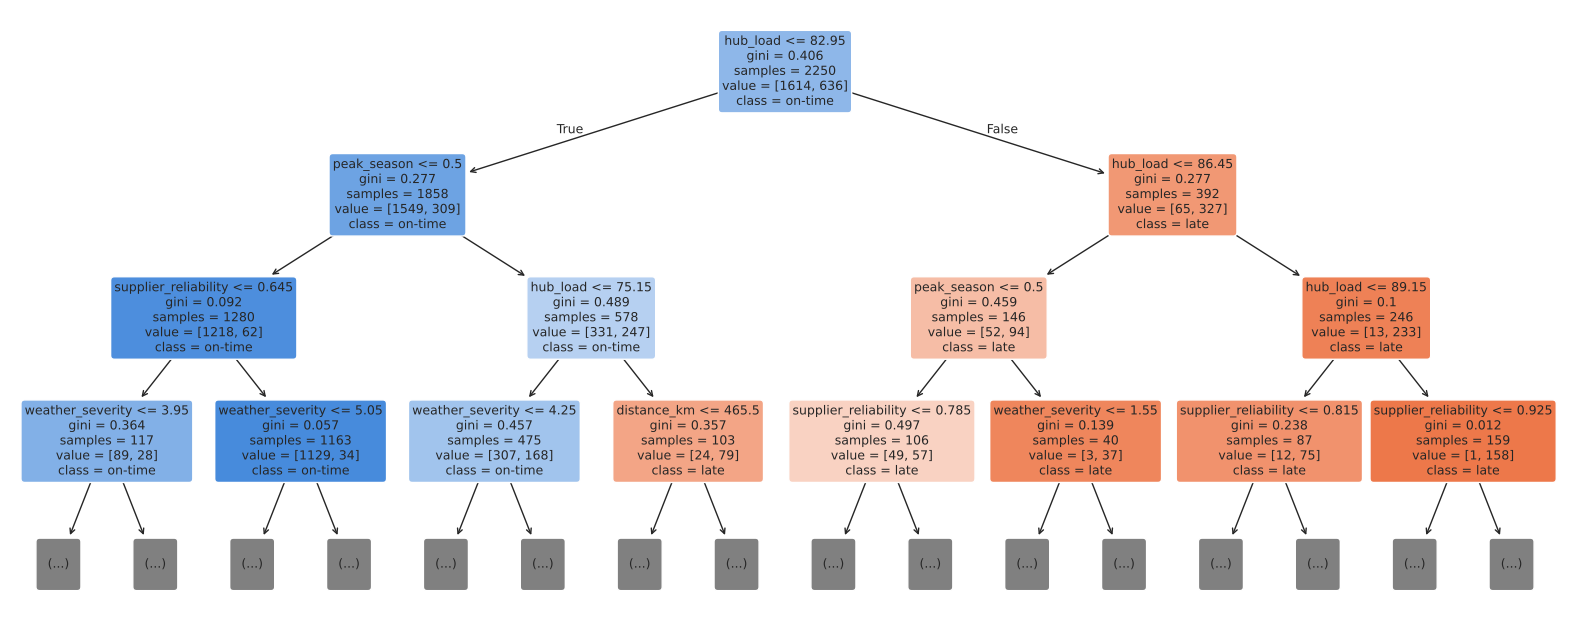

|--- hub_load <= 82.95
|   |--- peak_season <= 0.50
|   |   |--- supplier_reliability <= 0.64
|   |   |   |--- truncated branch of depth 4
|   |   |--- supplier_reliability >  0.64
|   |   |   |--- truncated branch of depth 6
|   |--- peak_season >  0.50
|   |   |--- hub_load <= 75.15
|   |   |   |--- truncated branch of depth 6
|   |   |--- hub_load >  75.15
|   |   |   |--- truncated branch of depth 3
|--- hub_load >  82.95
|   |--- hub_load <= 86.45
|   |   |--- peak_season <= 0.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- peak_season >  0.50
|   |   |   |--- truncated branch of depth 2
|   |--- hub_load >  86.45
|   |   |--- hub_load <= 89.15
|   |   |   |--- truncated branch of depth 3
|   |   |--- hub_load >  89.15
|   |   |   |--- truncated branch of depth 2



In [60]:
plt.figure(figsize=(20, 8))
draw_tree(tree_late, Xl_train.columns, ax=plt.gca(), max_depth=3, fontsize=9)
plt.show()
print(export_text(tree_late, feature_names=list(Xl_train.columns), max_depth=2))

**Question 59** &nbsp;·&nbsp; *Interpretation*

Read the first splits. Which question does the tree ask first? Write two "if … then …" rules in plain English that a logistics manager could use (e.g. *"if promised_days ≤ … and hub_load > … then the delivery is very likely late"*). Do these rules make operational sense?

> **Your answer:** 

### 9.5 How is the importance of a variable computed?

A tree provides a measure of **feature importance**. The principle is simple: *every time a variable is used to split a node, it reduces the impurity of the data; the importance of a variable is the total impurity reduction it brings in the whole tree* (weighted by the number of observations concerned, then normalised so that all importances sum to 1).

Back to our ten-shipment toy tree to see the calculation node by node:

In [61]:
t = tree_tiny.tree_
n_total = t.weighted_n_node_samples[0]
rows = []
for node in range(t.node_count):
    left, right = t.children_left[node], t.children_right[node]
    if left == -1:
        continue                                       # a leaf does not split: no contribution
    decrease = (t.weighted_n_node_samples[node] * t.impurity[node]
                - t.weighted_n_node_samples[left] * t.impurity[left]
                - t.weighted_n_node_samples[right] * t.impurity[right]) / n_total
    rows.append({"node": node, "variable used": tiny_features[t.feature[node]], "observations": int(t.weighted_n_node_samples[node]),
                 "impurity before": t.impurity[node], "weighted impurity after": (t.weighted_n_node_samples[left] * t.impurity[left] + t.weighted_n_node_samples[right] * t.impurity[right]) / t.weighted_n_node_samples[node],
                 "contribution (impurity decrease × share of data)": decrease})
contrib = pd.DataFrame(rows)
display(contrib.round(3))

total = contrib.groupby("variable used")["contribution (impurity decrease × share of data)"].sum()
print("Normalised importance (by hand)   :", (total / total.sum()).round(3).to_dict())
print("feature_importances_ of sklearn   :", dict(zip(tiny_features, tree_tiny.feature_importances_.round(3))))

,node,variable used,observations,impurity before,weighted impurity after,contribution (impurity decrease × share of data)
0,0,hub_load,10,0.500,0.167,0.333
1,1,distance_km,6,0.278,0.000,0.167


Normalised importance (by hand)   : {'distance_km': 0.333, 'hub_load': 0.667}
feature_importances_ of sklearn   : {'distance_km': np.float64(0.333), 'hub_load': np.float64(0.667)}


**Question 60** &nbsp;·&nbsp; *Analysis*

Following the table, explain why `hub_load` receives about two thirds of the importance and `distance_km` one third. What would the importance of a variable be if it was **never** used in the tree?

> **Your answer:** 

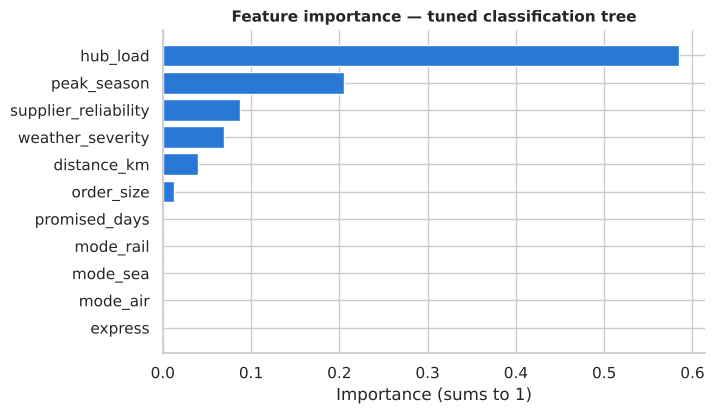

In [62]:
imp = pd.Series(tree_late.feature_importances_, index=Xl_train.columns).sort_values()
plt.figure(figsize=(7, 4.2))
plt.barh(imp.index, imp.values, color=BLUE)
plt.xlabel("Importance (sums to 1)"); plt.title("Feature importance — tuned classification tree")
plt.show()

**Warning — importance is not causality, and it has limits:**

* It tells how much the **model** relies on a variable, not what would happen in the real world if we changed it.
* If two variables carry the same information (e.g. distance and transport mode), the importance is **shared arbitrarily** between them.
* Importance computed on the training data can **favour variables with many distinct values** (we will see an experiment in Part 12).

**Question 61** &nbsp;·&nbsp; *Interpretation*

Which variable is the most important for the tree? Does it match what you expected after reading the rules and the data exploration? Do the variables of low importance have no influence on lateness in reality? Be careful in your wording.

> **Your answer:** 

### 9.6 A regression tree for the lead time (Dataset A)

Now with the numerical target `lead_time` and the features `X_ship` / split of Part 5. We compare the **linear regression** (baseline), a **shallow tree** and a **tuned tree**.

In [63]:
from sklearn.model_selection import KFold

shallow = DecisionTreeRegressor(max_depth=3, random_state=0).fit(Xs_train, ys_train)

gs_reg = GridSearchCV(DecisionTreeRegressor(random_state=0),
                      {"max_depth": [3, 4, 5, 6, 8, 10, None], "min_samples_leaf": [1, 5, 10, 20, 40]},
                      scoring="neg_root_mean_squared_error", cv=KFold(5, shuffle=True, random_state=RANDOM_STATE))
gs_reg.fit(Xs_train, ys_train)
tree_reg = gs_reg.best_estimator_
print("Best hyper-parameters:", gs_reg.best_params_)

full_reg = DecisionTreeRegressor(random_state=0).fit(Xs_train, ys_train)
comparison = pd.DataFrame({"Naive (mean)": regression_scores(baseline, Xs_test, ys_test),
                           "Linear regression": regression_scores(lin, Xs_test, ys_test),
                           "Tree, depth 3": regression_scores(shallow, Xs_test, ys_test),
                           "Tree, unconstrained": regression_scores(full_reg, Xs_test, ys_test),
                           "Tree, tuned": regression_scores(tree_reg, Xs_test, ys_test)}).T
display(comparison.round(3))

Best hyper-parameters: {'max_depth': None, 'min_samples_leaf': 10}


,MAE (days),RMSE (days),R²
Naive (mean),1.854,2.427,-0.000
Linear regression,0.896,1.126,0.785
"Tree, depth 3",1.151,1.460,0.638
"Tree, unconstrained",0.860,1.143,0.778
"Tree, tuned",0.773,1.044,0.815


**Question 62** &nbsp;·&nbsp; *Interpretation*

Rank the models by RMSE on the test set. Is the tuned tree better than the linear regression? Why is the unconstrained tree worse than the tuned one? Which model would you choose if the manager wants to *understand* the forecast, and which one if only the accuracy matters?

> **Your answer:** 

**What does each model "believe"?** We predict the lead time of a "typical" shipment (all features fixed at their median) while changing **only one variable** at a time: the hub load, then the distance — up to 5,000 km, which is *beyond* the range of the training data (maximum 2,500 km).

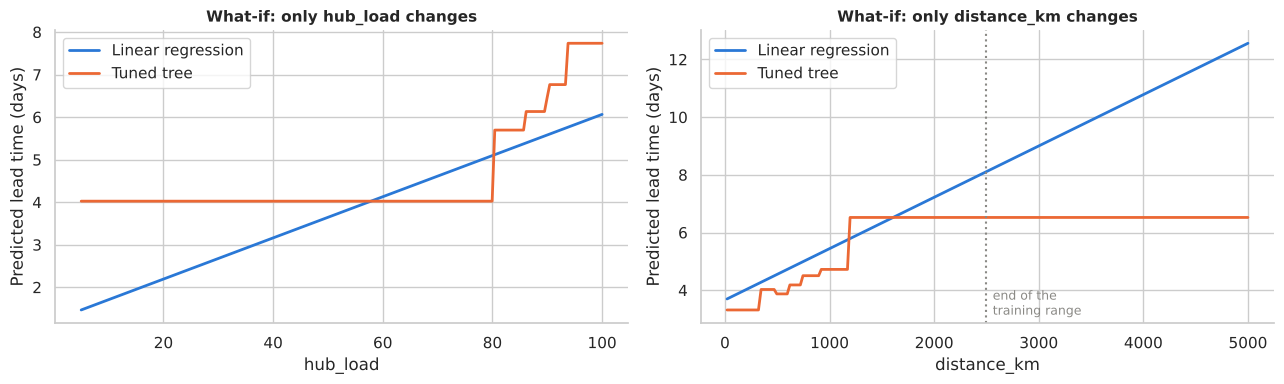

In [64]:
typical = Xs_train.median().to_frame().T                      # a "typical" shipment (median of each variable)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (var, values) in zip(axes, [("hub_load", np.linspace(5, 100, 200)), ("distance_km", np.linspace(20, 5000, 200))]):
    scen = pd.concat([typical] * len(values), ignore_index=True); scen[var] = values
    ax.plot(values, lin.predict(scen), color=BLUE, lw=2, label="Linear regression")
    ax.plot(values, tree_reg.predict(scen), color=ORANGE, lw=2, label="Tuned tree")
    ax.set_xlabel(var); ax.set_ylabel("Predicted lead time (days)"); ax.legend(); ax.set_title(f"What-if: only {var} changes")
axes[1].axvline(Xs_train["distance_km"].max(), color=GRAY, ls=":"); axes[1].text(Xs_train["distance_km"].max() + 60, axes[1].get_ylim()[0] + .3, "end of the\ntraining range", color=GRAY, fontsize=9)
plt.tight_layout(); plt.show()

**Question 63** &nbsp;·&nbsp; *Interpretation*

(a) Left plot: how does each model describe the effect of the hub load? Which description is closer to what you saw in Part 2 (and to reality)? (b) Right plot: what does the tree predict for a shipment of 4,000 km? What does the linear model predict? Which one would you trust more, and why is it dangerous to use any model **outside the range of the data it was trained on**?

> **Your answer:** 

## Part 10: Ensemble methods

### 10.1 The wisdom of crowds

A single decision tree is easy to read but **unstable**: change a few observations in the training data and you may get a very different tree (high variance). **Ensemble methods** combine **many models** to obtain one that is *more accurate and more robust* — like asking a panel of experts instead of a single one.

There are two main families, with different philosophies:

| | **Bagging** (e.g. Random Forest) | **Boosting** (e.g. AdaBoost, Gradient Boosting) |
|---|---|---|
| How are the models built? | **independently**, in parallel, on different random samples | **sequentially**: each model tries to fix the errors of the previous ones |
| Base models | deep, complex trees (low bias, high variance) | shallow trees (high bias, low variance) |
| Main effect | **reduces the variance** | **reduces the bias** |
| Final prediction | average / majority vote | weighted sum of the models |

### 10.2 The bootstrap

**Bagging** = **B**ootstrap **agg**regat**ing**. A *bootstrap sample* has the same size as the training set and is obtained by **drawing observations *with replacement***: some observations appear several times, others not at all. Let us illustrate with our ten toy shipments.

In [65]:
rng = np.random.default_rng(3)
boot = rng.choice(tiny.index, size=len(tiny), replace=True)           # one bootstrap sample of the 10 shipments
counts = pd.Series(boot).value_counts().reindex(tiny.index, fill_value=0)
print("Bootstrap sample:", list(boot))
print("Number of times each shipment is drawn:", counts.to_dict())
print("Shipments never drawn ('out-of-bag'):", list(counts[counts == 0].index))

# On a larger dataset: which share of the observations appears at least once in a bootstrap sample?
n = 100_000
share = len(np.unique(rng.integers(0, n, size=n))) / n
print(f"\nShare of distinct observations in a bootstrap sample of size {n:,}: {share:.1%}  (theory: 1 - 1/e = 63.2%)")

Bootstrap sample: ['S9', 'S1', 'S2', 'S3', 'S2', 'S9', 'S9', 'S6', 'S1', 'S1']
Number of times each shipment is drawn: {'S1': 3, 'S2': 2, 'S3': 1, 'S4': 0, 'S5': 0, 'S6': 1, 'S7': 0, 'S8': 0, 'S9': 3, 'S10': 0}
Shipments never drawn ('out-of-bag'): ['S4', 'S5', 'S7', 'S8', 'S10']

Share of distinct observations in a bootstrap sample of size 100,000: 63.1%  (theory: 1 - 1/e = 63.2%)


**Question 64** &nbsp;·&nbsp; *Analysis*

(a) In the bootstrap sample above, which shipments are repeated and which ones are missing? (b) Roughly what share of the observations is **left out** of each bootstrap sample? (c) These left-out observations are called *out-of-bag* (OOB). Why are they useful?

> **Your answer:** 

### 10.3 Bagging: reducing the variance (Dataset C)

The recipe, for $T$ models:

1. For $t = 1,\dots,T$: draw a bootstrap sample $S_t$ of the training set and train a (deep) tree $h_t$ on $S_t$.
2. Final model: the **average** $H_T(x)=\frac1T\sum_{t=1}^T h_t(x)$ (for classification: majority vote).

We go back to the daily demand forecasting problem. We now use a larger training set (70% of the 365 days).

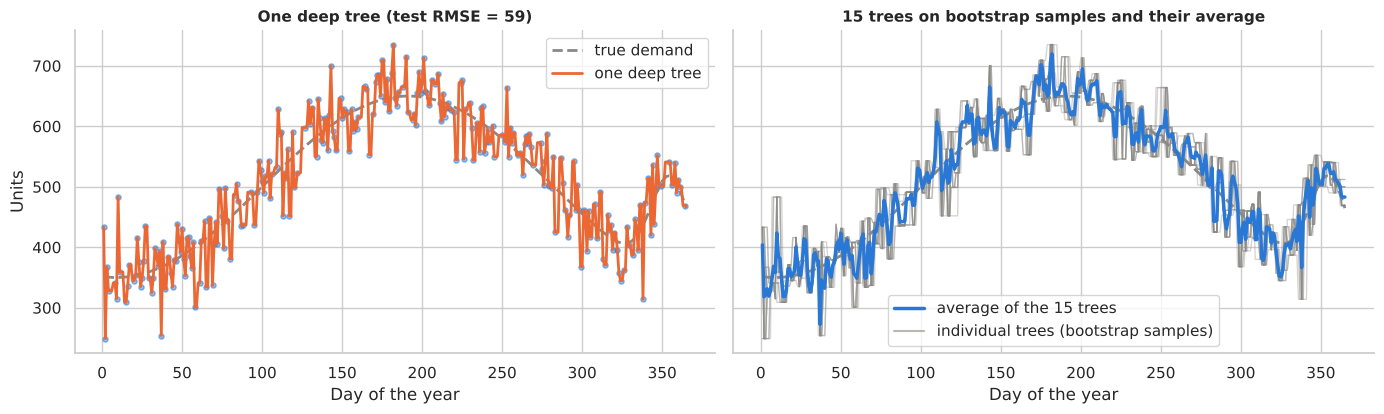

In [66]:
Xd2_train, Xd2_test, yd2_train, yd2_test = train_test_split(Xd, yd, test_size=0.3, random_state=1)
grid_days = pd.DataFrame({"day_of_year": days_grid})

# --- 1) one deep tree vs. 15 trees trained on bootstrap samples ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), sharey=True)
single = DecisionTreeRegressor(random_state=0).fit(Xd2_train, yd2_train)
axes[0].scatter(Xd2_train, yd2_train, s=14, color=BLUE, alpha=.5)
axes[0].plot(days_grid, true_demand(days_grid), "--", color=GRAY, lw=2, label="true demand")
axes[0].plot(days_grid, single.predict(grid_days), color=ORANGE, lw=2, label="one deep tree")
axes[0].set_title(f"One deep tree (test RMSE = {root_mean_squared_error(yd2_test, single.predict(Xd2_test)):.0f})"); axes[0].legend(); axes[0].set_ylabel("Units")

preds = []
for i in range(15):
    idx = np.random.default_rng(i).integers(0, len(Xd2_train), len(Xd2_train))             # bootstrap sample
    t = DecisionTreeRegressor(random_state=0).fit(Xd2_train.iloc[idx], yd2_train.iloc[idx])
    p = t.predict(grid_days); preds.append(p)
    axes[1].plot(days_grid, p, color=GRAY, alpha=.35, lw=1)
mean_pred = np.mean(preds, axis=0)
axes[1].plot(days_grid, true_demand(days_grid), "--", color=GRAY, lw=2)
axes[1].plot(days_grid, mean_pred, color=BLUE, lw=2.5, label="average of the 15 trees")
axes[1].plot([], [], color=GRAY, alpha=.6, label="individual trees (bootstrap samples)")
axes[1].set_title("15 trees on bootstrap samples and their average"); axes[1].legend()
for ax in axes: ax.set_xlabel("Day of the year")
plt.tight_layout(); plt.show()

**Question 65** &nbsp;·&nbsp; *Interpretation*

Look at the grey curves (individual trees). How different are they from each other, and why (what differs between their training data)? Compare the blue curve (the average) with the single orange tree and with the true demand: what is the main visible difference?

> **Your answer:** 

**Measuring the variance.** Because the data is simulated, we can do something impossible in real life: **generate 100 different years of sales** from the same demand process, fit a model on each history, and look at how much the predictions *vary* from one history to another. This variation is precisely the *variance* of the model. We also compute the squared *bias* (distance between the average prediction and the true demand).

,squared bias,variance,bias² + variance
One deep tree,14.0,1592.0,1606.0
Bagging (30 trees),7.0,760.0,767.0


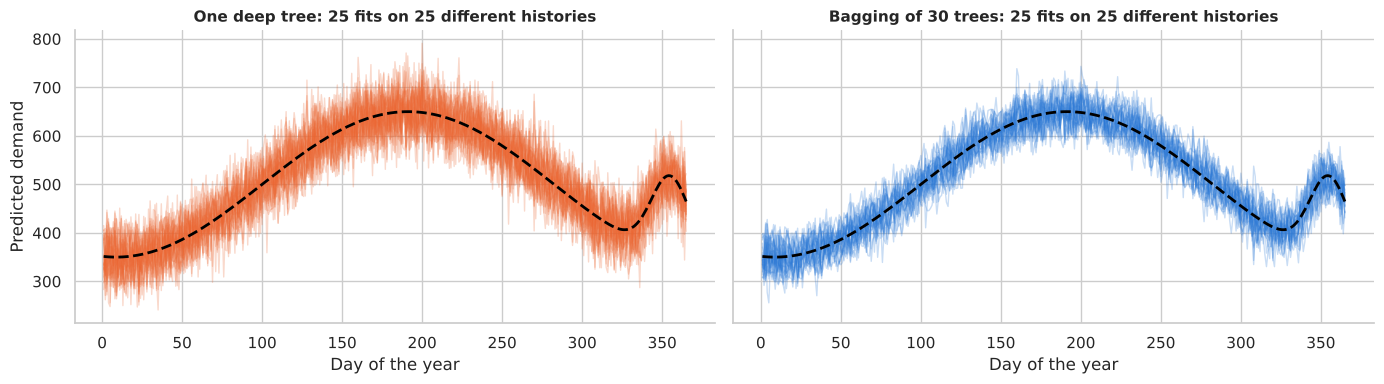

In [67]:
from sklearn.ensemble import BaggingRegressor

def prediction_curves(make_model, n_rep=100):
    curves = []
    for r in range(n_rep):
        hist, _ = make_demand(seed=1000 + r)                                  # a new simulated year
        m = make_model().fit(hist[["day_of_year"]], hist["demand"])
        curves.append(m.predict(grid_days))
    return np.array(curves)

curves_tree = prediction_curves(lambda: DecisionTreeRegressor(random_state=0))
curves_bag  = prediction_curves(lambda: BaggingRegressor(DecisionTreeRegressor(), n_estimators=30, random_state=0))

truth = true_demand(days_grid)
summary = pd.DataFrame({
    "One deep tree": {"squared bias": np.mean((curves_tree.mean(0) - truth) ** 2), "variance": curves_tree.var(0).mean()},
    "Bagging (30 trees)": {"squared bias": np.mean((curves_bag.mean(0) - truth) ** 2), "variance": curves_bag.var(0).mean()}}).T
summary["bias² + variance"] = summary.sum(axis=1)
display(summary.round(0))

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, curves, title in [(axes[0], curves_tree, "One deep tree"), (axes[1], curves_bag, "Bagging of 30 trees")]:
    for c in curves[:25]: ax.plot(days_grid, c, color=ORANGE if ax is axes[0] else BLUE, alpha=.25, lw=1)
    ax.plot(days_grid, truth, "--", color="black", lw=2); ax.set_title(f"{title}: 25 fits on 25 different histories"); ax.set_xlabel("Day of the year")
axes[0].set_ylabel("Predicted demand")
plt.tight_layout(); plt.show()

**Question 66** &nbsp;·&nbsp; *Interpretation*

Read the table: what is the effect of bagging on the **bias** and on the **variance**? What does the right plot tell you about the stability of the forecast from one year to the next? Why does this matter for a planner who must decide on safety stocks?

> **Your answer:** 

**Question 67** &nbsp;·&nbsp; *Analysis*

If we average $T$ **independent** predictions, each with variance $\sigma^2$, the variance of the average is $\sigma^2/T$. Our 30 bagged trees reduce the variance, but less than 30 times. Why? (Hint: think of the 30 bootstrap samples; are the trees independent?) What could we do to make the trees *more different* from each other?

> **Your answer:** 

**Question 68** &nbsp;·&nbsp; *Implementation*

Bagging with $T$ = 1, 5, 25 and 100 trees: complete the loop to print the **test RMSE** for each number of trees. What happens when $T$ increases?

> **Your answer:** 

In [ ]:
for T in [1, 5, 25, 100]:
    bag = BaggingRegressor(DecisionTreeRegressor(), n_estimators=____, random_state=0)
    bag.fit(Xd2_train, yd2_train)
    print(f"T = {T:>3} trees -> test RMSE = {root_mean_squared_error(yd2_test, bag.predict(____)):.1f}")

### 10.4 Random forests

A **random forest** is bagging of trees **plus one additional source of randomness**: at *each split*, the tree is only allowed to look at a **random subset of the features** (`max_features`). If one variable is very strong (e.g. `hub_load`), all bagged trees would start with it and look alike; forcing them to consider other variables makes the trees **more diverse**, hence the average is more stable.

Main hyper-parameters: `n_estimators` (number of trees — more is never worse, only slower), `max_features`, and the usual `max_depth` / `min_samples_leaf`.

We compare, on the late-delivery problem (Dataset A), a single tree, bagged trees and a random forest.

In [69]:
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier

models = {
    "Single tuned tree":   tree_late,
    "Bagging (200 trees)": BaggingClassifier(DecisionTreeClassifier(min_samples_leaf=5), n_estimators=200, random_state=0, n_jobs=-1),
    "Random forest (200 trees)": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, max_features="sqrt", random_state=0, n_jobs=-1),
}
rows = {}
for name, m in models.items():
    m.fit(Xl_train, yl_train)
    p = m.predict_proba(Xl_test)[:, 1]
    rows[name] = {"AUC (test)": roc_auc_score(yl_test, p), "accuracy (test)": accuracy_score(yl_test, (p >= .5).astype(int)),
                  "recall of 'late' (test)": recall_score(yl_test, (p >= .5).astype(int))}
display(pd.DataFrame(rows).T.round(3))

,AUC (test),accuracy (test),recall of 'late' (test)
Single tuned tree,0.920,0.860,0.712
Bagging (200 trees),0.940,0.879,0.755
Random forest (200 trees),0.946,0.875,0.712


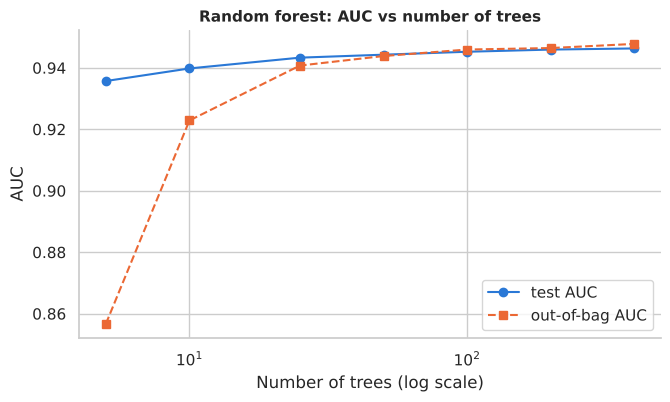

,max_features,out-of-bag AUC,test AUC
0,1,0.945,0.941
1,2,0.947,0.947
2,3,0.946,0.946
3,5,0.946,0.945
4,10,0.943,0.941


In [70]:
# Effect of the number of trees (the out-of-bag AUC is computed on the observations each tree has NOT seen)
n_list = [5, 10, 25, 50, 100, 200, 400]
auc_test, auc_oob = [], []
for n_trees in n_list:
    rf = RandomForestClassifier(n_estimators=n_trees, min_samples_leaf=5, oob_score=True, random_state=0, n_jobs=-1).fit(Xl_train, yl_train)
    auc_test.append(roc_auc_score(yl_test, rf.predict_proba(Xl_test)[:, 1]))
    oob = rf.oob_decision_function_[:, 1]
    ok = ~np.isnan(oob)
    auc_oob.append(roc_auc_score(yl_train[ok], oob[ok]))

plt.figure(figsize=(7.5, 4))
plt.plot(n_list, auc_test, "o-", color=BLUE, label="test AUC"); plt.plot(n_list, auc_oob, "s--", color=ORANGE, label="out-of-bag AUC")
plt.xscale("log"); plt.xlabel("Number of trees (log scale)"); plt.ylabel("AUC"); plt.legend(); plt.title("Random forest: AUC vs number of trees")
plt.show()

# Effect of max_features: how many variables each split is allowed to look at (out of 10)
mf_rows = []
for mf in [1, 2, 3, 5, 10]:
    rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, max_features=mf, oob_score=True, random_state=0, n_jobs=-1).fit(Xl_train, yl_train)
    mf_rows.append({"max_features": mf, "out-of-bag AUC": roc_auc_score(yl_train, rf.oob_decision_function_[:, 1]),
                    "test AUC": roc_auc_score(yl_test, rf.predict_proba(Xl_test)[:, 1])})
display(pd.DataFrame(mf_rows).round(3))

**Question 69** &nbsp;·&nbsp; *Interpretation*

(a) Compare the single tree, the bagging and the random forest. Is the improvement from the single tree to the ensembles large? (b) What happens to the AUC when the number of trees increases? Is there a risk of overfitting by adding trees? (c) With `max_features=10` all variables are examined at each split: which ensemble does this correspond to?

> **Your answer:** 

**Question 70** &nbsp;·&nbsp; *Analysis*

Why is a random forest **more robust** than a single tree? Why can we afford to use **deep, unpruned** trees inside a forest while this was a bad idea for a single tree? And what is the practical interest of the *out-of-bag* score for a company with limited data?

> **Your answer:** 

**Question 71** &nbsp;·&nbsp; *Implementation*

Train a random forest with **500 trees**, `min_samples_leaf=10` and `max_features=3`, then print its AUC and its recall (threshold 0.5) on the test set.

> **Your answer:** 

In [ ]:
my_rf = RandomForestClassifier(n_estimators=____, min_samples_leaf=____, max_features=____, random_state=0, n_jobs=-1)
my_rf.fit(Xl_train, yl_train)
proba = my_rf.predict_proba(____)[:, 1]
print("AUC   :", round(roc_auc_score(yl_test, proba), 3))
print("Recall:", round(recall_score(yl_test, (proba >= 0.5).astype(int)), 3))

### 10.5 Boosting: reducing the bias

In bagging, the models are independent. **Boosting** breaks this independence: models are trained **one after the other**, each one **concentrating on the observations that the previous models got wrong**. The base models are very simple (e.g. a *stump*: a tree with a single split) and individually weak; their combination is strong.

#### AdaBoost, step by step

We start with $m$ observations $(x_i, y_i)$, $y_i\in\{-1,+1\}$, all with the same weight $w_i^{(1)}=1/m$. At round $t$:

1. Train a weak model $h_t$ **taking the weights into account** (heavy observations count more).
2. Compute its weighted error $\varepsilon_t=\sum_i w^{(t)}_i\,\mathbb{1}[h_t(x_i)\neq y_i]$.
3. Give it a **confidence** $\alpha_t=\frac12\ln\frac{1-\varepsilon_t}{\varepsilon_t}$ (small error → large confidence).
4. **Update the weights**: $w^{(t+1)}_i \propto w^{(t)}_i\exp(-\alpha_t\,y_i\,h_t(x_i))$ — misclassified observations get **heavier**, correctly classified ones get lighter (then the weights are re-normalised to sum to 1).

The final model is a weighted vote: $H(x)=\text{sign}\Big(\sum_t \alpha_t h_t(x)\Big)$.

Let us run it **by hand** on our ten toy shipments with stumps, for 3 rounds.

In [72]:
X_t = tiny[tiny_features]
y01 = tiny["late"].values
y_pm = 2 * y01 - 1                         # labels in {-1, +1}
w = np.full(len(tiny), 1 / len(tiny))      # round 1: all weights equal

history = pd.DataFrame(index=tiny.index)
votes = np.zeros(len(tiny))
for t_round in range(1, 4):
    stump = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X_t, y01, sample_weight=w)
    pred_pm = 2 * stump.predict(X_t) - 1
    wrong = pred_pm != y_pm
    eps = max(w[wrong].sum(), 1e-10)                       # weighted error
    alpha = 0.5 * np.log((1 - eps) / eps)                  # confidence of this stump
    rule = f"{tiny_features[stump.tree_.feature[0]]} <= {stump.tree_.threshold[0]:.0f}"
    print(f"Round {t_round}: stump '{rule}' | weighted error = {eps:.3f} | alpha = {alpha:.3f} | misclassified: {list(tiny.index[wrong])}")

    history[f"weight, round {t_round}"] = w
    history[f"wrong? r{t_round}"] = np.where(wrong, "X", "")
    votes += alpha * pred_pm
    w = w * np.exp(-alpha * y_pm * pred_pm)                # update
    w = w / w.sum()                                        # normalise

history["weight, round 4"] = w
history["true class"] = np.where(y_pm == 1, "late", "on-time")
history["final vote (sum of alpha*h)"] = votes
history["final prediction"] = np.where(votes > 0, "late", "on-time")
display(history.round(3))
print("Accuracy of the boosted model on the 10 shipments:", (np.where(votes > 0, 1, 0) == y01).mean())

Round 1: stump 'hub_load <= 75' | weighted error = 0.100 | alpha = 1.099 | misclassified: ['S9']
Round 2: stump 'hub_load <= 52' | weighted error = 0.111 | alpha = 1.040 | misclassified: ['S5', 'S10']
Round 3: stump 'distance_km <= 750' | weighted error = 0.094 | alpha = 1.134 | misclassified: ['S2', 'S4', 'S6']


,"weight, round 1",wrong? r1,"weight, round 2",wrong? r2,"weight, round 3",wrong? r3,"weight, round 4",true class,final vote (sum of alpha*h),final prediction
S1,0.1,,0.056,,0.031,,0.017,on-time,-3.273,on-time
S2,0.1,,0.056,,0.031,X,0.167,late,1.004,late
S3,0.1,,0.056,,0.031,,0.017,on-time,-3.273,on-time
S4,0.1,,0.056,,0.031,X,0.167,late,1.004,late
S5,0.1,,0.056,X,0.250,,0.138,on-time,-1.193,on-time
S6,0.1,,0.056,,0.031,X,0.167,late,1.004,late
S7,0.1,,0.056,,0.031,,0.017,on-time,-3.273,on-time
S8,0.1,,0.056,,0.031,,0.017,late,3.273,late
S9,0.1,X,0.500,,0.281,,0.155,late,1.075,late
S10,0.1,,0.056,X,0.250,,0.138,on-time,-1.193,on-time


Accuracy of the boosted model on the 10 shipments: 1.0


**Question 72** &nbsp;·&nbsp; *Interpretation*

Follow the weights from round 1 to round 2. (a) Which shipment is misclassified by the first stump and what happens to its weight? (b) Check the value of $\alpha_1$ with the formula and the printed error. (c) What kind of stump does the algorithm choose in round 2, and why is it different from round 1? (d) Is the final combination better than the first stump alone?

> **Your answer:** 

Now the real AdaBoost of scikit-learn on the supplier audit (Dataset D), with stumps. We watch the decision regions after 1, 5, 20 and 100 rounds.

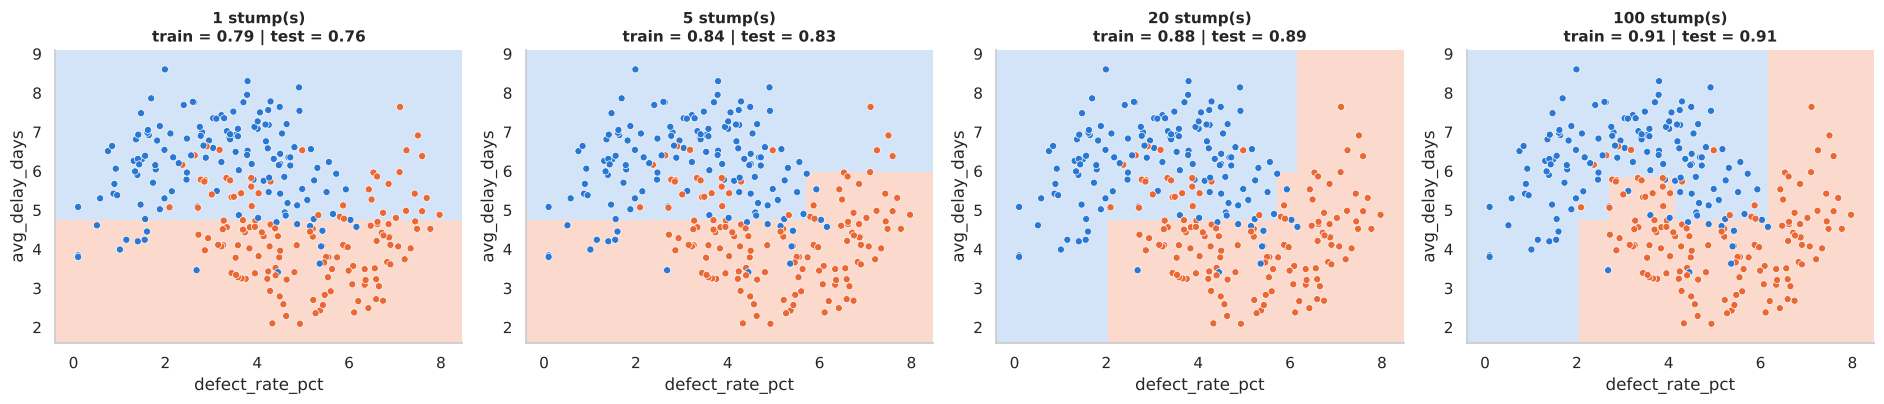

In [73]:
from sklearn.ensemble import AdaBoostClassifier

fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
for ax, n in zip(axes, [1, 5, 20, 100]):
    ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=n, learning_rate=0.5, random_state=0)
    ada.fit(audit_train[audit_features], audit_train["at_risk"])
    plot_boundary(ada, audit_train, audit_features, "at_risk", ax,
                  f"{n} stump(s)\ntrain = {ada.score(audit_train[audit_features], audit_train['at_risk']):.2f} | test = {ada.score(audit_test[audit_features], audit_test['at_risk']):.2f}")
plt.tight_layout(); plt.show()

**Question 73** &nbsp;·&nbsp; *Interpretation*

How do the decision regions evolve with the number of iterations? Why can a combination of very simple models (each one a single straight cut) draw a curved, complex frontier? Compare with what a single tree of depth 1 can do.

> **Your answer:** 

The **learning rate** $\eta$ multiplies the confidence of each model: $\alpha_t \leftarrow \eta\,\alpha_t$. A small $\eta$ makes learning slower and more cautious (more rounds are needed), a large $\eta$ is aggressive. The plot shows the test accuracy after each round.

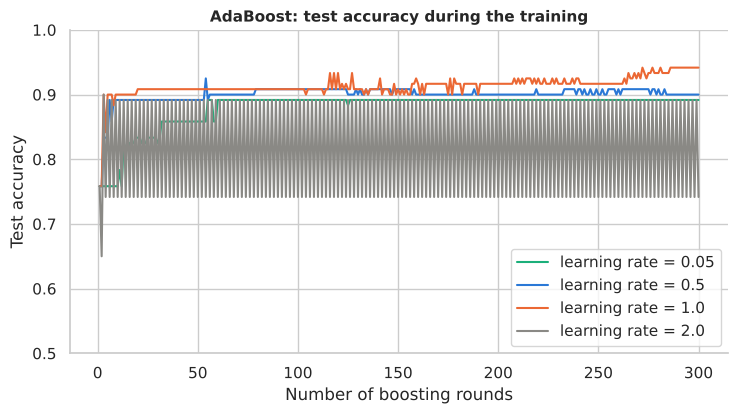

In [74]:
plt.figure(figsize=(8.5, 4.2))
for lr, color in [(0.05, AQUA), (0.5, BLUE), (1.0, ORANGE), (2.0, GRAY)]:
    ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=300, learning_rate=lr, random_state=0)
    ada.fit(audit_train[audit_features], audit_train["at_risk"])
    staged = list(ada.staged_score(audit_test[audit_features], audit_test["at_risk"]))
    plt.plot(range(1, 301), staged, color=color, label=f"learning rate = {lr}")
plt.xlabel("Number of boosting rounds"); plt.ylabel("Test accuracy"); plt.ylim(.5, 1); plt.legend(loc="lower right")
plt.title("AdaBoost: test accuracy during the training"); plt.show()

**Question 74** &nbsp;·&nbsp; *Interpretation*

Compare the four learning rates: speed of progress, final accuracy, stability of the curve. What happens when the learning rate is too high? Which trade-off exists between `learning_rate` and `n_estimators`?

> **Your answer:** 

#### Gradient boosting: learning from the residuals

Gradient boosting (the family behind XGBoost, LightGBM or CatBoost, widely used in industry for demand forecasting and credit scoring) applies the same philosophy in a different way. For a regression problem:

1. Start with a **constant prediction** (the mean of the target).
2. Compute the **residuals**: what remains to be explained, $r_i = y_i - \hat y_i$.
3. Train a small tree to **predict these residuals**, and add a **fraction $\eta$** (learning rate) of its predictions to the current model.
4. Repeat: each tree corrects the remaining errors of the sum of the previous ones.

We build it "by hand" on the daily demand data (Dataset C): shallow trees (depth 2), $\eta=0.3$.

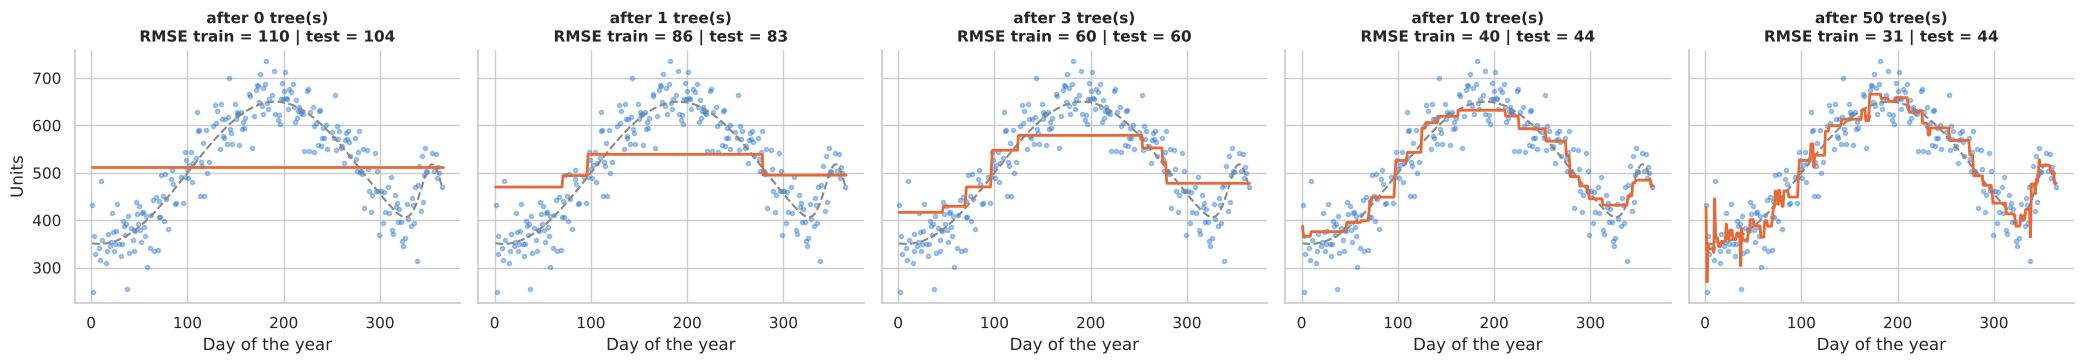

Check with scikit-learn's GradientBoostingRegressor: test RMSE = 44.2  (by hand: 44.2)


In [75]:
lr = 0.3
F_train = np.full(len(yd2_train), yd2_train.mean())            # current prediction (start: the mean)
F_test  = np.full(len(yd2_test),  yd2_train.mean())
F_grid  = np.full(len(days_grid), yd2_train.mean())
snapshots = {0: (F_grid.copy(), root_mean_squared_error(yd2_train, F_train), root_mean_squared_error(yd2_test, F_test))}

for m in range(1, 51):
    residuals = yd2_train - F_train                             # what the model has not explained yet
    tree_m = DecisionTreeRegressor(max_depth=2, random_state=0).fit(Xd2_train, residuals)
    F_train += lr * tree_m.predict(Xd2_train)
    F_test  += lr * tree_m.predict(Xd2_test)
    F_grid  += lr * tree_m.predict(grid_days)
    if m in (1, 3, 10, 50):
        snapshots[m] = (F_grid.copy(), root_mean_squared_error(yd2_train, F_train), root_mean_squared_error(yd2_test, F_test))

fig, axes = plt.subplots(1, 5, figsize=(21, 3.8), sharey=True)
for ax, (m, (curve, rtr, rte)) in zip(axes, snapshots.items()):
    ax.scatter(Xd2_train, yd2_train, s=9, color=BLUE, alpha=.4)
    ax.plot(days_grid, true_demand(days_grid), "--", color=GRAY, lw=1.5)
    ax.plot(days_grid, curve, color=ORANGE, lw=2)
    ax.set_title(f"after {m} tree(s)\nRMSE train = {rtr:.0f} | test = {rte:.0f}"); ax.set_xlabel("Day of the year")
axes[0].set_ylabel("Units")
plt.tight_layout(); plt.show()

from sklearn.ensemble import GradientBoostingRegressor
gb = GradientBoostingRegressor(n_estimators=50, learning_rate=0.3, max_depth=2, criterion="squared_error", random_state=0).fit(Xd2_train, yd2_train)
print(f"Check with scikit-learn's GradientBoostingRegressor: test RMSE = {root_mean_squared_error(yd2_test, gb.predict(Xd2_test)):.1f}  (by hand: {snapshots[50][2]:.1f})")

**Question 75** &nbsp;·&nbsp; *Interpretation*

Describe what happens between 0, 1, 3, 10 and 50 trees. What does the model look like at the very beginning, and what does each new tree add? Why does the training error decrease — and what happens to the test error?

> **Your answer:** 

**When to stop?** Boosting keeps fitting the training data: with too many rounds, it starts to fit the noise. Unlike random forests, **adding rounds can lead to overfitting**. We track the test error after each round for three learning rates.

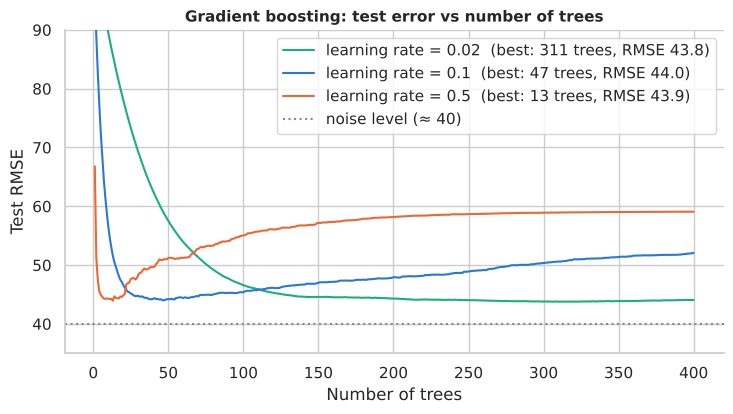

In [76]:
plt.figure(figsize=(8.5, 4.2))
for lr, color in [(0.02, AQUA), (0.1, BLUE), (0.5, ORANGE)]:
    gbm = GradientBoostingRegressor(n_estimators=400, learning_rate=lr, max_depth=3, random_state=0).fit(Xd2_train, yd2_train)
    test_curve = [root_mean_squared_error(yd2_test, p) for p in gbm.staged_predict(Xd2_test)]
    plt.plot(range(1, 401), test_curve, color=color, label=f"learning rate = {lr}  (best: {np.argmin(test_curve) + 1} trees, RMSE {min(test_curve):.1f})")
plt.axhline(40, color=GRAY, ls=":", label="noise level (≈ 40)")
plt.ylim(35, 90); plt.xlabel("Number of trees"); plt.ylabel("Test RMSE"); plt.legend(); plt.title("Gradient boosting: test error vs number of trees")
plt.show()

**Question 76** &nbsp;·&nbsp; *Analysis*

Where does the test error stop improving, and what happens afterwards for the largest learning rate? Compare with the random forest, where adding trees never hurt. In a real project, **how** would you choose the number of trees without looking at the test set?

> **Your answer:** 

**Question 77** &nbsp;·&nbsp; *Implementation*

Train a gradient boosting model for the **lead time of the shipments** (Dataset A: `Xs_train`, `ys_train`) with 200 trees, a learning rate of 0.05 and trees of depth 3. Print its test RMSE and compare with the linear regression (≈ 1.13 days) and with the tuned tree (≈ 1.04 days).

> **Your answer:** 

In [ ]:
gb_lead = GradientBoostingRegressor(n_estimators=____, learning_rate=____, max_depth=____, random_state=0)
gb_lead.fit(Xs_train, ys_train)
print("Test RMSE (days):", round(root_mean_squared_error(ys_test, gb_lead.predict(____)), 3))

### 10.6 The big comparison

Time to put all the models in competition, with the **same rules for everybody**: 5-fold cross-validation on the training set, then one single evaluation on the test set. The hyper-parameters below are reasonable values (not exhaustively tuned).

**(1) Supplier default** (Dataset B) — a rare event, metric: **AUC**.

,CV AUC (mean),CV AUC (std),test AUC,time (s)
model,,,,
AdaBoost,0.842,0.041,0.887,4.496
Bagging,0.839,0.050,0.903,3.578
Random forest,0.838,0.041,0.890,5.096
Gradient boosting,0.822,0.050,0.875,3.948
Logistic regression,0.821,0.045,0.825,0.060
"k-NN (k=25, scaled)",0.790,0.045,0.814,0.166
Decision tree,0.767,0.080,0.860,0.052


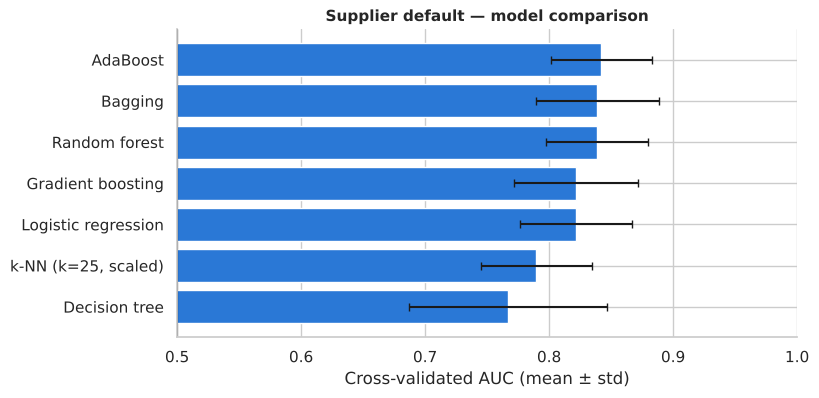

In [78]:
import time
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_validate

clf_models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "k-NN (k=25, scaled)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25)),
    "Decision tree":       DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=0),
    "Bagging":             BaggingClassifier(DecisionTreeClassifier(max_depth=6, min_samples_leaf=10), n_estimators=200, random_state=0, n_jobs=-1),
    "Random forest":       RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=0, n_jobs=-1),
    "AdaBoost":            AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2), n_estimators=200, learning_rate=0.1, random_state=0),
    "Gradient boosting":   GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=0),
}
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, model in clf_models.items():
    start = time.time()
    cv_res = cross_validate(model, Xb_train, yb_train, cv=cv5, scoring="roc_auc")
    model.fit(Xb_train, yb_train)
    rows.append({"model": name, "CV AUC (mean)": cv_res["test_score"].mean(), "CV AUC (std)": cv_res["test_score"].std(),
                 "test AUC": roc_auc_score(yb_test, model.predict_proba(Xb_test)[:, 1]), "time (s)": time.time() - start})
res_clf = pd.DataFrame(rows).set_index("model")
display(res_clf.round(3).sort_values("CV AUC (mean)", ascending=False))

res_plot = res_clf.sort_values("CV AUC (mean)")
plt.figure(figsize=(8, 4))
plt.barh(res_plot.index, res_plot["CV AUC (mean)"], xerr=res_plot["CV AUC (std)"], color=BLUE, capsize=3)
plt.xlim(0.5, 1); plt.axvline(0.5, color="black", lw=.8); plt.xlabel("Cross-validated AUC (mean ± std)")
plt.title("Supplier default — model comparison"); plt.show()

**Question 78** &nbsp;·&nbsp; *Interpretation*

Rank the models. Are all the differences larger than the standard deviation between the cross-validation folds (the error bars)? Which differences would you consider *meaningful* and which ones *within the noise*? Does the gain of the ensembles over a single tree match the claims made in this course (variance reduction / bias reduction)?

> **Your answer:** 

**(2) Lead time of shipments** (Dataset A) — a numerical target, metric: **RMSE** (days).

In [79]:
from sklearn.ensemble import RandomForestRegressor

reg_models = {
    "Naive (mean)":        DummyRegressor(strategy="mean"),
    "Linear regression":   LinearRegression(),
    "Decision tree":       DecisionTreeRegressor(min_samples_leaf=10, random_state=0),
    "Random forest":       RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0, n_jobs=-1),
    "Gradient boosting":   GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=0),
}
cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in reg_models.items():
    cv_res = cross_validate(model, Xs_train, ys_train, cv=cv_reg, scoring="neg_root_mean_squared_error")
    model.fit(Xs_train, ys_train)
    rows.append({"model": name, "CV RMSE (mean)": -cv_res["test_score"].mean(), "CV RMSE (std)": cv_res["test_score"].std(),
                 "test RMSE": root_mean_squared_error(ys_test, model.predict(Xs_test)), "test R²": r2_score(ys_test, model.predict(Xs_test))})
res_reg = pd.DataFrame(rows).set_index("model")
display(res_reg.round(3))

,CV RMSE (mean),CV RMSE (std),test RMSE,test R²
model,,,,
Naive (mean),2.391,0.086,2.427,-0.000
Linear regression,1.110,0.045,1.126,0.785
Decision tree,1.095,0.057,1.044,0.815
Random forest,0.862,0.040,0.824,0.885
Gradient boosting,0.712,0.037,0.724,0.911


**Question 79** &nbsp;·&nbsp; *Interpretation*

Rank the regression models by test RMSE and compare with the linear regression of Part 5. By how many days (on average) does the best model improve the forecast compared with the linear regression? Is this gain important for operations? Why, in this dataset, does the linear regression do relatively well?

> **Your answer:** 

**Question 80** &nbsp;·&nbsp; *Implementation*

Evaluate by 5-fold cross-validation (AUC) a gradient boosting classifier for the supplier default with **100 trees** of depth **2** and a learning rate of **0.1**. Compare its mean AUC with the table above.

> **Your answer:** 

In [ ]:
my_gb = GradientBoostingClassifier(n_estimators=____, max_depth=____, learning_rate=____, random_state=0)
scores = cross_val_score(my_gb, Xb_train, yb_train, cv=____, scoring="roc_auc")
print(f"CV AUC: {scores.mean():.3f} (± {scores.std():.3f})")

**Question 81** &nbsp;·&nbsp; *Discussion*

You are a risk manager who must choose a model to screen 4,000 suppliers each quarter. The model's output will be used in front of the purchasing committee and, potentially, an auditor. Compare **logistic regression**, a **single decision tree**, a **random forest** and **gradient boosting** according to: accuracy, interpretability, stability, training cost, and ease of tuning. Which one would you pick, and in which situation would you change your choice?

> **Your answer:** 

## Part 11: Neural networks: from one neuron to the multi-layer perceptron

Neural networks are behind the most visible successes of artificial intelligence: image recognition (reading a scanned delivery note, spotting a damaged parcel on a photo), machine translation, voice assistants, chatbots. For **tabular data** such as our shipments and suppliers, they are one option among others. In this part we want to understand:

1. what a single **artificial neuron** computes, and how it **learns**;
2. how neurons are combined in layers (the **multi-layer perceptron**, MLP), and which hyper-parameters control it;
3. how a neural network compares with the other algorithms of this course on our datasets.

### 11.1 The artificial neuron

A neuron receives the features $x_1, \dots, x_p$, computes a **weighted sum** and passes it through an **activation function** $g$:

$$z = b + w_1 x_1 + w_2 x_2 + \dots + w_p x_p \qquad\qquad \text{output} = g(z)$$

The weights $w_j$ and the bias $b$ are learnt from the data. The most common activation functions:

| Activation | Formula | Use |
|---|---|---|
| **step** | 1 if $z > 0$, else 0 | the historical *perceptron* (Rosenblatt, 1958) |
| **sigmoid** (logistic) | $1/(1+e^{-z})$ | output between 0 and 1: a probability |
| **tanh** | $\tanh(z)$ | output between −1 and 1 |
| **ReLU** | $\max(0, z)$ | the default choice in hidden layers today |

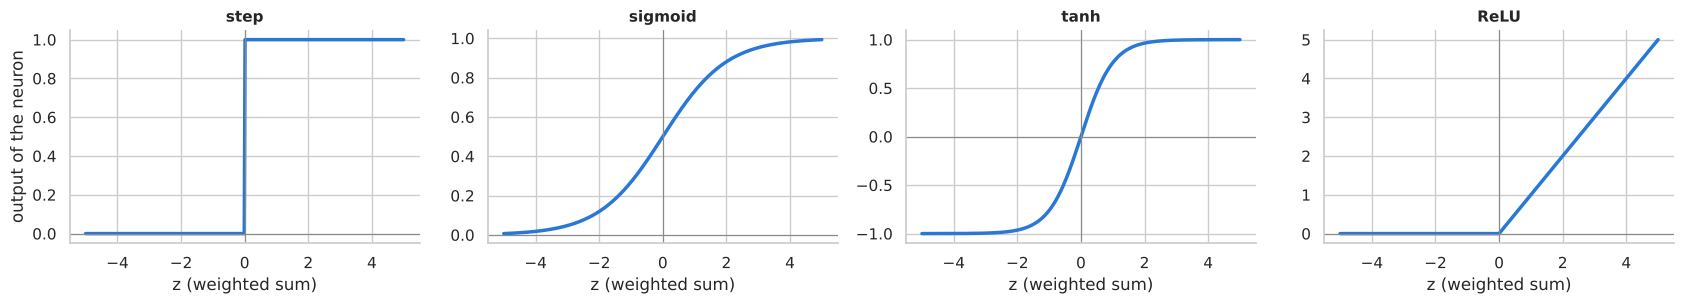

In [81]:
z = np.linspace(-5, 5, 400)
activations = {"step": (z > 0).astype(float), "sigmoid": 1 / (1 + np.exp(-z)), "tanh": np.tanh(z), "ReLU": np.maximum(0, z)}
fig, axes = plt.subplots(1, 4, figsize=(17, 3.2))
for ax, (name, values) in zip(axes, activations.items()):
    ax.plot(z, values, color=BLUE, lw=2.5); ax.axhline(0, color=GRAY, lw=.8); ax.axvline(0, color=GRAY, lw=.8)
    ax.set_title(name); ax.set_xlabel("z (weighted sum)")
axes[0].set_ylabel("output of the neuron")
plt.tight_layout(); plt.show()

**A neuron by hand.** A credit analyst builds a (very simplified) neuron to score suppliers, with weights chosen by experience (not learnt):

$$z = -4 + 3\cdot\text{debt\_ratio} - 1.5\cdot\text{current\_ratio} + 0.1\cdot\text{late\_orders\_pct} \qquad \text{risk score} = \text{sigmoid}(z)$$

In [82]:
def neuron(x, weights, bias, activation="sigmoid"):
    z = bias + np.dot(weights, x)                       # weighted sum
    return 1 / (1 + np.exp(-z)) if activation == "sigmoid" else float(z > 0)

weights_analyst = np.array([3.0, -1.5, 0.1])            # debt_ratio, current_ratio, late_orders_pct
bias_analyst = -4.0
supplier_x = np.array([0.9, 0.8, 15])                    # a leveraged supplier with little liquidity and 15% late orders
print("z =", round(bias_analyst + np.dot(weights_analyst, supplier_x), 2))
print("Risk score (sigmoid) =", round(neuron(supplier_x, weights_analyst, bias_analyst), 3))

z = -1.0
Risk score (sigmoid) = 0.269


**Question 82** &nbsp;·&nbsp; *Analysis*

(a) Compute **by hand** $z$ and the risk score of a supplier with `debt_ratio` = 0.5, `current_ratio` = 2.0 and `late_orders_pct` = 5 (you can check with the function `neuron`). (b) Which variable increases the risk, which one reduces it? (c) A single neuron with a sigmoid activation is *exactly* a model that you already know: which one? What is then the only difference between this neuron and that model?

> **Your answer:** 

#### How does a neuron learn? The perceptron rule

The perceptron (step activation) learns with a very simple rule. Start with all weights at 0, then go through the training examples one by one:

* if the prediction is correct → do nothing;
* if it is wrong → **nudge the weights towards the right answer**: $w_j \leftarrow w_j + \eta\,(y - \hat y)\,x_j$ and $b \leftarrow b + \eta\,(y - \hat y)$, where $\eta$ is the *learning rate*.

One pass over the whole data set is called an **epoch**; we repeat epochs until there is no error left. Let us apply it to the ten toy shipments of Part 9 (distance expressed in thousands of km and hub load in fraction of the capacity, so that both variables are between 0 and 1).

Epoch  1: 7 error(s) | w_distance = -0.005, w_hub_load = 0.033, bias = -0.10
Epoch  2: 8 error(s) | w_distance = 0.030, w_hub_load = 0.156, bias = -0.10
Epoch  3: 5 error(s) | w_distance = 0.040, w_hub_load = 0.154, bias = -0.20
Epoch  4: 6 error(s) | w_distance = 0.080, w_hub_load = 0.229, bias = -0.20
Epoch  5: 2 error(s) | w_distance = 0.155, w_hub_load = 0.214, bias = -0.20
Epoch  6: 5 error(s) | w_distance = 0.165, w_hub_load = 0.212, bias = -0.30
Epoch  7: 6 error(s) | w_distance = 0.215, w_hub_load = 0.262, bias = -0.30
Epoch  8: 2 error(s) | w_distance = 0.200, w_hub_load = 0.297, bias = -0.30
Epoch  9: 2 error(s) | w_distance = 0.185, w_hub_load = 0.332, bias = -0.30
Epoch 10: 0 error(s) | w_distance = 0.185, w_hub_load = 0.332, bias = -0.30


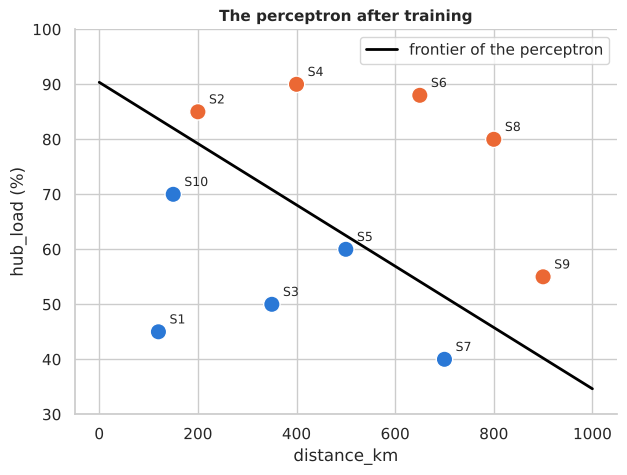

In [83]:
X_perc = np.c_[tiny["distance_km"] / 1000, tiny["hub_load"] / 100]      # rescaled features
y_perc = tiny["late"].values
w_perc, b_perc, eta = np.zeros(2), 0.0, 0.1

for epoch in range(1, 51):
    n_errors = 0
    for x_i, y_i in zip(X_perc, y_perc):
        y_hat = int(b_perc + w_perc @ x_i > 0)                 # prediction of the neuron (step activation)
        if y_hat != y_i:                                       # wrong -> nudge the weights
            w_perc += eta * (y_i - y_hat) * x_i
            b_perc += eta * (y_i - y_hat)
            n_errors += 1
    print(f"Epoch {epoch:>2}: {n_errors} error(s) | w_distance = {w_perc[0]:.3f}, w_hub_load = {w_perc[1]:.3f}, bias = {b_perc:.2f}")
    if n_errors == 0:
        break

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(tiny["distance_km"], tiny["hub_load"], c=np.where(tiny["late"] == 1, ORANGE, BLUE), s=140, edgecolor="white")
for name, row in tiny.iterrows():
    ax.annotate(name, (row["distance_km"], row["hub_load"]), textcoords="offset points", xytext=(8, 6), fontsize=9)
d_line = np.linspace(0, 1000, 50)
ax.plot(d_line, 100 * (-(b_perc + w_perc[0] * d_line / 1000) / w_perc[1]), color="black", lw=2, label="frontier of the perceptron")
ax.set_ylim(30, 100); ax.set_xlabel("distance_km"); ax.set_ylabel("hub_load (%)"); ax.legend(); ax.set_title("The perceptron after training")
plt.show()

**Question 83** &nbsp;·&nbsp; *Interpretation*

(a) How many epochs does the perceptron need to classify the ten shipments without error? (b) When a *late* shipment is predicted *on-time*, do the weights increase or decrease? Why does it make sense? (c) Write the final rule of the perceptron in words ("a shipment is predicted late if …"). Compare its frontier with the rectangles drawn by the tree of Part 9.1.

> **Your answer:** 

**The limit of a single neuron.** Whatever its weights, one neuron computes one weighted sum: its frontier is a **straight line**, exactly like the logistic regression. Let us check it on the supplier audit (Dataset D, the two moons).

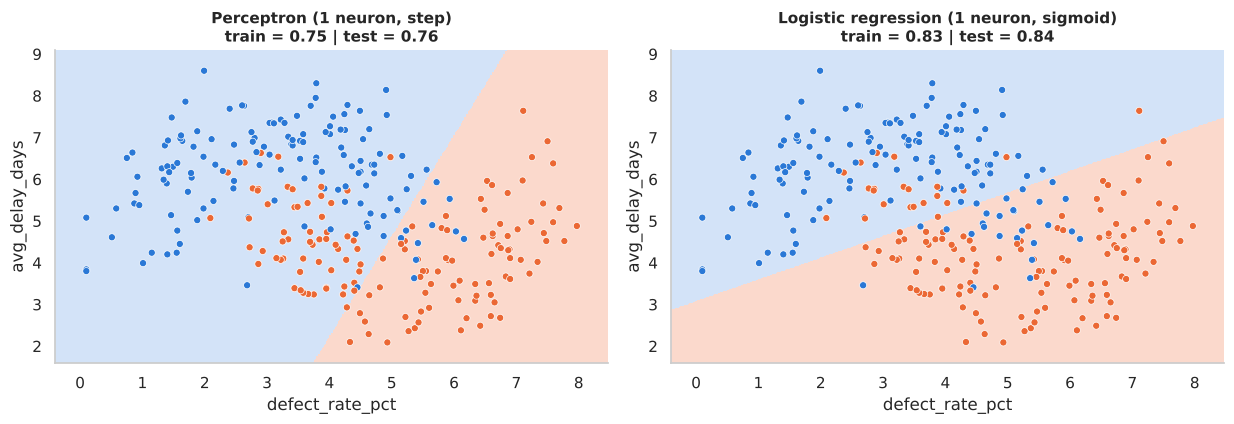

In [84]:
from sklearn.linear_model import Perceptron

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
for ax, (name, model) in zip(axes, [("Perceptron (1 neuron, step)", Perceptron(random_state=0)),
                                    ("Logistic regression (1 neuron, sigmoid)", LogisticRegression())]):
    one_neuron = make_pipeline(StandardScaler(), model).fit(audit_train[audit_features], audit_train["at_risk"])
    plot_boundary(one_neuron, audit_train, audit_features, "at_risk", ax,
                  f"{name}\ntrain = {one_neuron.score(audit_train[audit_features], audit_train['at_risk']):.2f} | "
                  f"test = {one_neuron.score(audit_test[audit_features], audit_test['at_risk']):.2f}")
plt.tight_layout(); plt.show()

### 11.2 The multi-layer perceptron (MLP)

To draw curved frontiers, we **combine** neurons in layers:

* the **input layer** contains the features (one node per variable, no computation);
* one or several **hidden layers**: each hidden neuron computes a weighted sum of the previous layer followed by an activation (ReLU by default). Each hidden neuron can be seen as a **new variable** built from the inputs, like the new variables of the kernels (Part 6.4), except that here they are **learnt** from the data;
* the **output layer**: one neuron with a sigmoid (classification: probability) or no activation (regression: a number).

With enough hidden neurons, an MLP can approximate almost any frontier or any smooth function (*universal approximation theorem*). The price: **many parameters**. Between two layers of sizes $n_1$ and $n_2$ there are $(n_1 + 1) \times n_2$ parameters (one weight per connection plus one bias per neuron).

*Run the cell: it draws two networks and counts their parameters.*

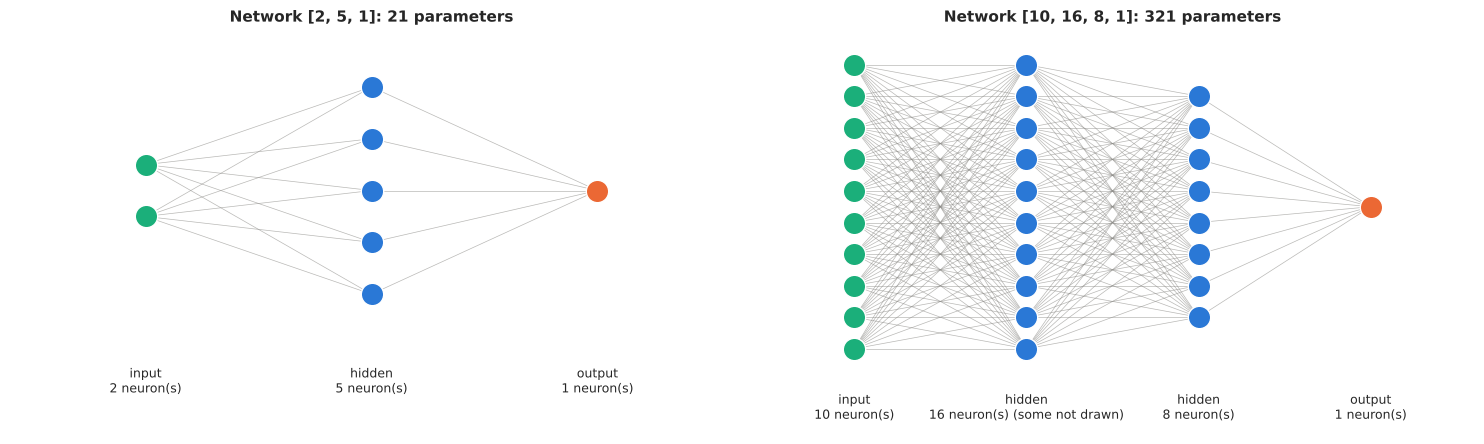

In [85]:
def draw_network(layer_sizes, ax, title=None, max_drawn=10):
    # Draws a fully connected network. Large layers are drawn with at most `max_drawn` neurons.
    drawn = [min(s, max_drawn) for s in layer_sizes]
    pos = [[(i, (n - 1) / 2 - k) for k in range(n)] for i, n in enumerate(drawn)]
    for left, right in zip(pos[:-1], pos[1:]):
        for (x1, y1) in left:
            for (x2, y2) in right:
                ax.plot([x1, x2], [y1, y2], color=GRAY, lw=.5, alpha=.6, zorder=1)
    names = ["input"] + ["hidden"] * (len(layer_sizes) - 2) + ["output"]
    for i, layer in enumerate(pos):
        color = AQUA if i == 0 else (ORANGE if i == len(pos) - 1 else BLUE)
        for (x, y) in layer:
            ax.scatter(x, y, s=260, color=color, edgecolor="white", zorder=2)
        label = f"{names[i]}\n{layer_sizes[i]} neuron(s)" + (" (some not drawn)" if layer_sizes[i] > max_drawn else "")
        ax.text(i, -max(drawn) / 2 - 0.9, label, ha="center", va="top", fontsize=9)
    ax.set_xlim(-.6, len(layer_sizes) - .4); ax.set_ylim(-max(drawn) / 2 - 2.2, max(drawn) / 2 + .6); ax.axis("off")
    if title: ax.set_title(title)

def n_parameters(layer_sizes):
    return sum((a + 1) * b for a, b in zip(layer_sizes[:-1], layer_sizes[1:]))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for ax, layers in zip(axes, [[2, 5, 1], [10, 16, 8, 1]]):
    draw_network(layers, ax, f"Network {layers}: {n_parameters(layers)} parameters")
plt.tight_layout(); plt.show()

**Question 84** &nbsp;·&nbsp; *Analysis*

(a) Check by hand the number of parameters of the network [2, 5, 1]. (b) How many parameters has a logistic regression with 10 input variables? Compare with the network [10, 16, 8, 1]. (c) We have about 2,250 shipments in the training set of Dataset A. What risk do we take with a network that has thousands of parameters, and which tools of this course can limit it?

> **Your answer:** 

#### How does an MLP learn?

1. Start with **small random weights**.
2. Compute the predictions and a **loss** that measures the errors (the *log-loss* for a classification, the squared error for a regression).
3. Compute, for **every** weight, in which direction it should move to reduce the loss (its *gradient*). The algorithm that computes all these directions efficiently, layer by layer from the output back to the inputs, is called **backpropagation**.
4. Move all the weights by a small step in this direction (the size of the step is the **learning rate**), and repeat over the data many times (**epochs**).

*Analogy: a hiker lost in the fog who wants to reach the bottom of the valley: at each step she feels the slope under her feet and takes a step downhill. Too small steps: she arrives very late; too large steps: she jumps from one side of the valley to the other.*

Main hyper-parameters of `MLPClassifier` / `MLPRegressor` in scikit-learn:

| Hyper-parameter | Meaning |
|---|---|
| `hidden_layer_sizes` | number of neurons of each hidden layer, e.g. `(10,)` = one layer of 10, `(50, 50)` = two layers of 50 |
| `activation` | activation of the hidden neurons (`"relu"` by default) |
| `alpha` | **regularisation**: penalises large weights → smoother model (larger `alpha` = simpler model) |
| `learning_rate_init` | size of the steps |
| `max_iter` | maximum number of epochs |
| `solver` | optimisation algorithm: `"adam"` (default, for large data) or `"lbfgs"` (efficient for small data sets) |
| `random_state` | seed of the random initial weights |

As for the SVM, **standardisation is necessary** (the weighted sums mix all the variables).

**Number of hidden neurons.** We fit MLPs with one hidden layer of 1, 3, 10 and 100 neurons on the supplier audit (Dataset D).

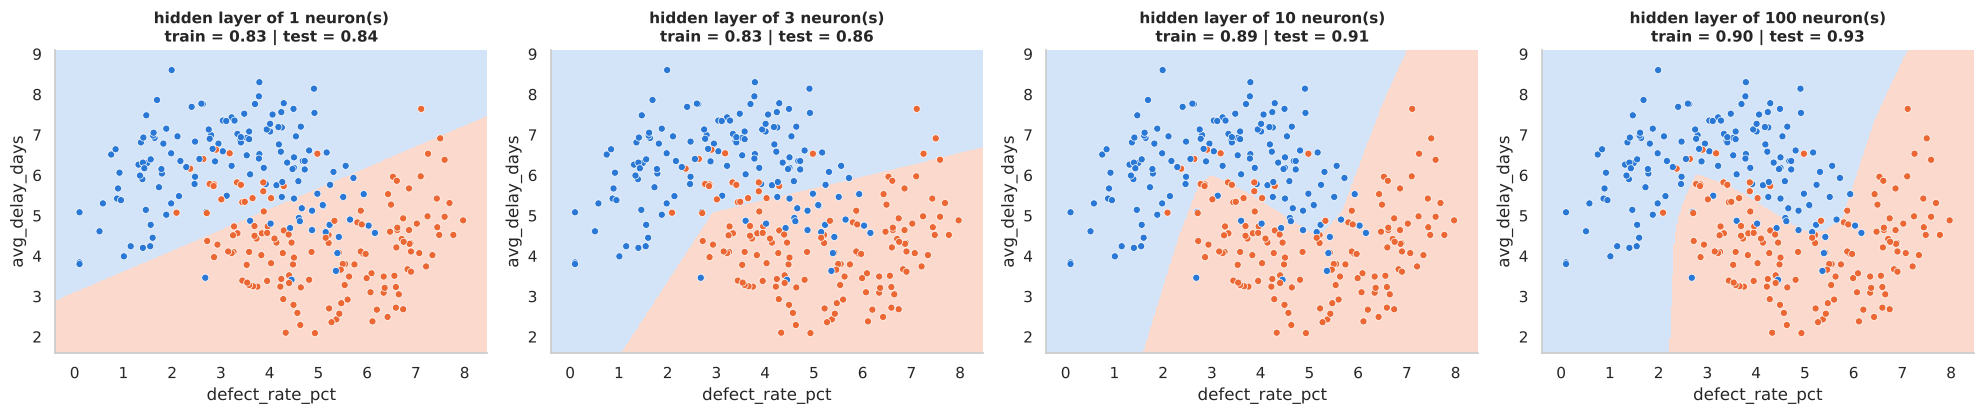

In [86]:
from sklearn.neural_network import MLPClassifier, MLPRegressor

fig, axes = plt.subplots(1, 4, figsize=(20, 4.3))
for ax, h in zip(axes, [(1,), (3,), (10,), (100,)]):
    mlp = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=h, alpha=1, solver="lbfgs", max_iter=5000, random_state=0))
    mlp.fit(audit_train[audit_features], audit_train["at_risk"])
    plot_boundary(mlp, audit_train, audit_features, "at_risk", ax,
                  f"hidden layer of {h[0]} neuron(s)\ntrain = {mlp.score(audit_train[audit_features], audit_train['at_risk']):.2f} | "
                  f"test = {mlp.score(audit_test[audit_features], audit_test['at_risk']):.2f}")
plt.tight_layout(); plt.show()

**Question 85** &nbsp;·&nbsp; *Interpretation*

How does the frontier change when the number of hidden neurons increases? Why is the network with **1** hidden neuron almost equivalent to a logistic regression? From how many neurons does the network capture the two moons?

> **Your answer:** 

**Regularisation (`alpha`).** We now take a large network (two hidden layers of 100 neurons, i.e. more than 10,000 parameters for 280 training suppliers) and vary the regularisation.

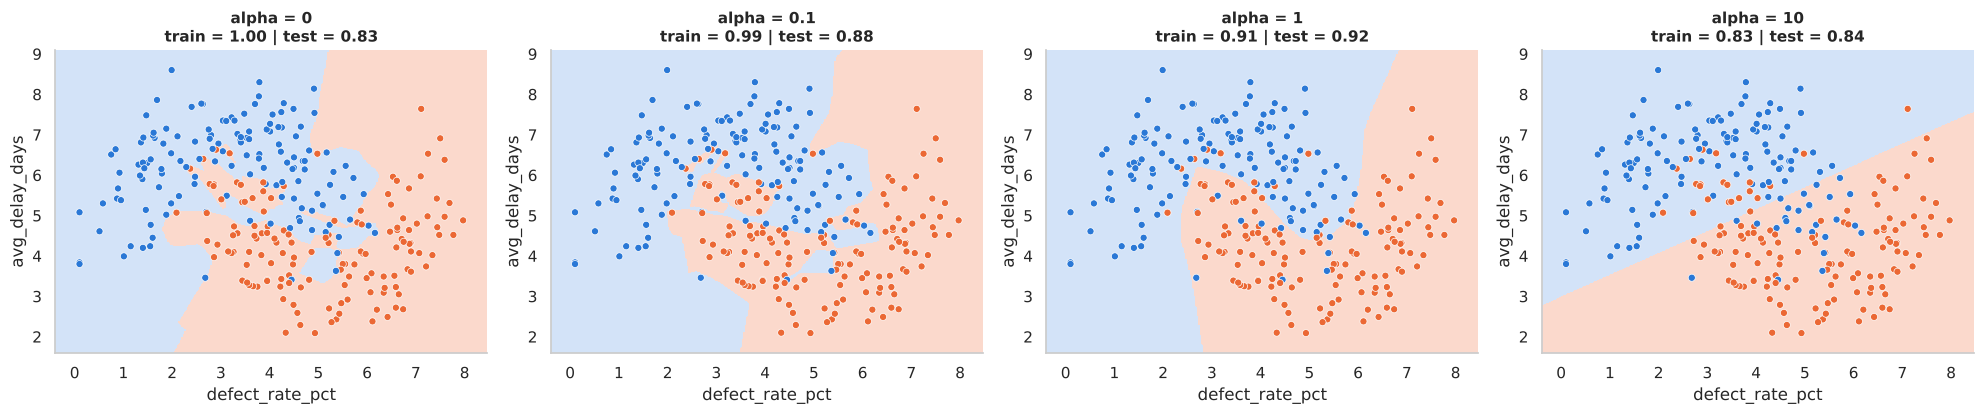

In [87]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.3))
for ax, a in zip(axes, [0, 0.1, 1, 10]):
    mlp = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(100, 100), alpha=a, solver="lbfgs", max_iter=5000, random_state=0))
    mlp.fit(audit_train[audit_features], audit_train["at_risk"])
    plot_boundary(mlp, audit_train, audit_features, "at_risk", ax,
                  f"alpha = {a}\ntrain = {mlp.score(audit_train[audit_features], audit_train['at_risk']):.2f} | "
                  f"test = {mlp.score(audit_test[audit_features], audit_test['at_risk']):.2f}")
plt.tight_layout(); plt.show()

**Question 86** &nbsp;·&nbsp; *Interpretation*

(a) Describe the four frontiers. Which value of `alpha` overfits, which one underfits? (b) A large `alpha` makes the model *simpler*. For the SVM, does a large `C` make the model simpler or more complex? (c) Why is it reasonable to start with a large network and control it with `alpha`, rather than trying to guess the "right" number of neurons?

> **Your answer:** 

**Random initial weights.** The training starts from random weights and only goes "downhill": depending on the starting point it can stop in different valleys (*local minima*). We fit the **same** network (one hidden layer of 4 neurons) with four different seeds.

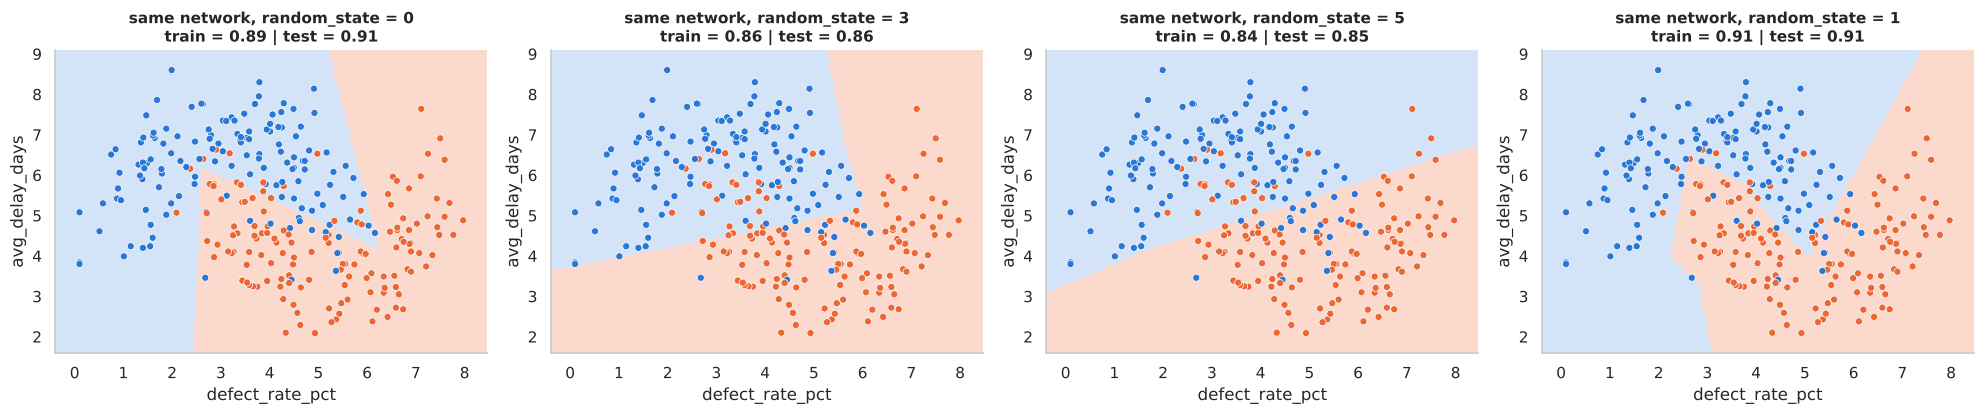

In [88]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.3))
for ax, seed in zip(axes, [0, 3, 5, 1]):
    mlp = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(4,), solver="lbfgs", max_iter=5000, random_state=seed))
    mlp.fit(audit_train[audit_features], audit_train["at_risk"])
    plot_boundary(mlp, audit_train, audit_features, "at_risk", ax,
                  f"same network, random_state = {seed}\ntrain = {mlp.score(audit_train[audit_features], audit_train['at_risk']):.2f} | "
                  f"test = {mlp.score(audit_test[audit_features], audit_test['at_risk']):.2f}")
plt.tight_layout(); plt.show()

**Question 87** &nbsp;·&nbsp; *Analysis*

The four models above have the same architecture and were trained on the same data. What differs, and why? What does it imply for (a) the **reproducibility** of a result reported to a manager or an auditor, and (b) the way we should compare a neural network with another model? Propose two ways to make the result more stable (hint: think about Part 10).

> **Your answer:** 

**The learning rate.** With the default solver `adam`, the network is trained epoch after epoch; `loss_curve_` stores the training loss after each epoch. We compare four learning rates (300 epochs at most).

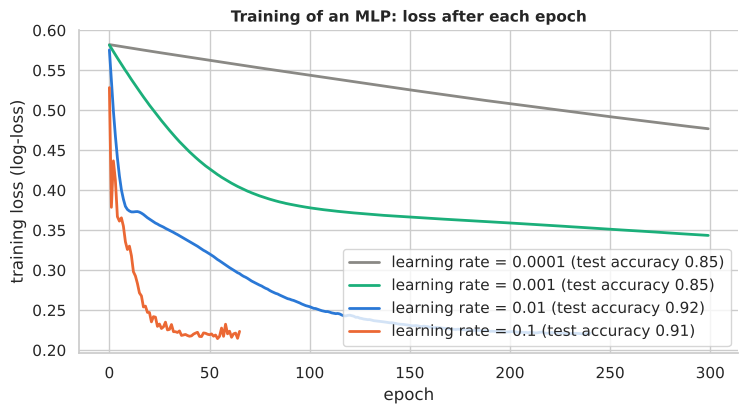

In [89]:
plt.figure(figsize=(8.5, 4.2))
for lr, color in [(0.0001, GRAY), (0.001, AQUA), (0.01, BLUE), (0.1, ORANGE)]:
    mlp = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(20,), learning_rate_init=lr, max_iter=300, random_state=0))
    mlp.fit(audit_train[audit_features], audit_train["at_risk"])
    plt.plot(mlp[-1].loss_curve_, color=color, lw=2,
             label=f"learning rate = {lr} (test accuracy {mlp.score(audit_test[audit_features], audit_test['at_risk']):.2f})")
plt.xlabel("epoch"); plt.ylabel("training loss (log-loss)"); plt.legend(); plt.title("Training of an MLP: loss after each epoch")
plt.show()

**Question 88** &nbsp;·&nbsp; *Interpretation*

Compare the four curves: speed of the decrease, final level of the loss, number of epochs used, test accuracy. What happens with a learning rate that is too small? Which hyper-parameter of gradient boosting (Part 10.5) plays a similar role, and what is the common trade-off?

> **Your answer:** 

**Question 89** &nbsp;·&nbsp; *Implementation*

Fit an MLP with **two hidden layers of 20 neurons**, `alpha = 0.5` and the solver `lbfgs` on the training audit data, print its train and test accuracy and draw its frontier.

> **Your answer:** 

In [ ]:
my_mlp = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(____, ____), alpha=____, solver="lbfgs",
                                                        max_iter=5000, random_state=0))
my_mlp.fit(audit_train[audit_features], audit_train["at_risk"])
print("Train accuracy:", round(my_mlp.score(audit_train[audit_features], audit_train["at_risk"]), 3))
print("Test accuracy :", round(my_mlp.score(audit_test[audit_features], audit_test["at_risk"]), 3))
plot_boundary(my_mlp, audit_train, audit_features, "at_risk", title="My neural network")
plt.show()

### 11.3 A regression network: the daily demand (Dataset C)

For a numerical target, `MLPRegressor` uses an output neuron **without activation**. We fit networks of increasing size on the daily demand of Part 3 (70% of the days for training, as in Part 10.3).

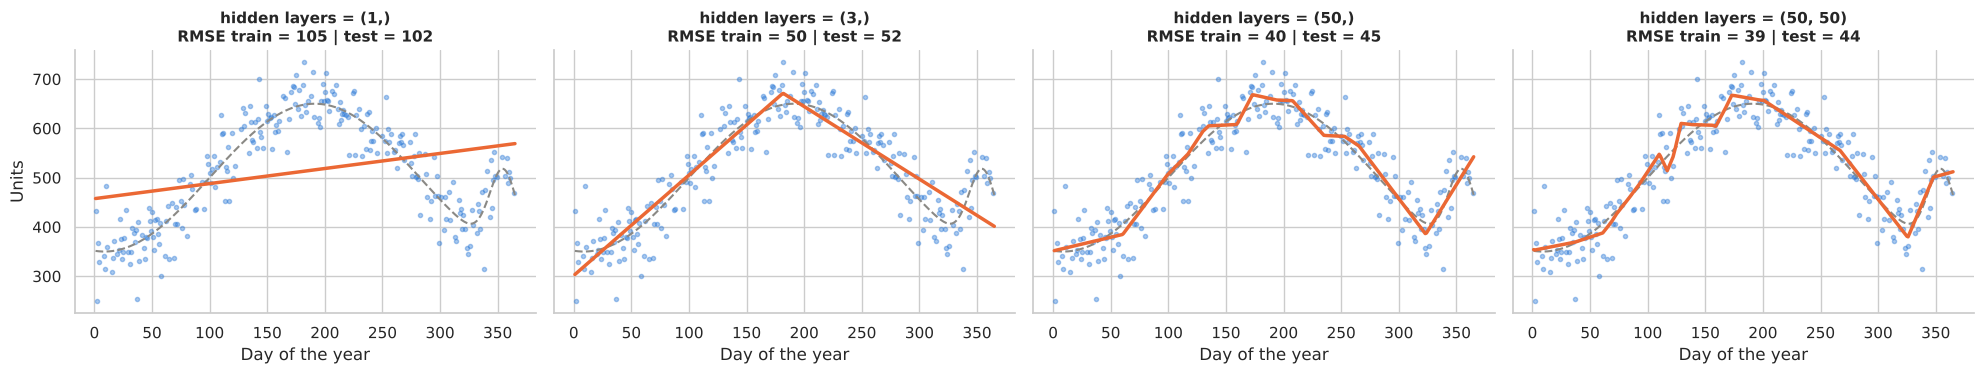

In [91]:
fig, axes = plt.subplots(1, 4, figsize=(20, 3.9), sharey=True)
for ax, h in zip(axes, [(1,), (3,), (50,), (50, 50)]):
    mlp_d = make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=h, solver="lbfgs", max_iter=5000, random_state=0))
    mlp_d.fit(Xd2_train, yd2_train)
    ax.scatter(Xd2_train, yd2_train, s=9, color=BLUE, alpha=.4)
    ax.plot(days_grid, true_demand(days_grid), "--", color=GRAY, lw=1.5)
    ax.plot(days_grid, mlp_d.predict(grid_days), color=ORANGE, lw=2.5)
    ax.set_title(f"hidden layers = {h}\nRMSE train = {root_mean_squared_error(yd2_train, mlp_d.predict(Xd2_train)):.0f} | "
                 f"test = {root_mean_squared_error(yd2_test, mlp_d.predict(Xd2_test)):.0f}")
    ax.set_xlabel("Day of the year")
axes[0].set_ylabel("Units")
plt.tight_layout(); plt.show()

**Question 90** &nbsp;·&nbsp; *Interpretation*

(a) Describe the four curves. Which networks underfit? (b) Compare the shape of the best network's curve with the curve of a regression tree or of gradient boosting (Part 10.5): which one looks more like the true demand? (c) The noise level is ≈ 40 units: is the best network close to the best possible error?

> **Your answer:** 

### 11.4 Where do SVMs and neural networks stand? The big comparison, continued

We add an RBF SVM and a neural network to the two competitions of Part 10.6, **with the same rules** (same 5-fold cross-validation on the training set, one evaluation on the test set). The hyper-parameters are reasonable values, not exhaustively tuned.

**(1) Supplier default** (Dataset B), metric: AUC.

,CV AUC (mean),CV AUC (std),test AUC,time (s)
model,,,,
AdaBoost,0.842,0.041,0.887,4.496
Bagging,0.839,0.050,0.903,3.578
Random forest,0.838,0.041,0.890,5.096
Neural network (MLP 50-50),0.829,0.043,0.854,6.588
Gradient boosting,0.822,0.050,0.875,3.948
Logistic regression,0.821,0.045,0.825,0.060
"SVM (RBF, C=0.1, balanced)",0.821,0.045,0.857,1.172
"k-NN (k=25, scaled)",0.790,0.045,0.814,0.166
Decision tree,0.767,0.080,0.860,0.052


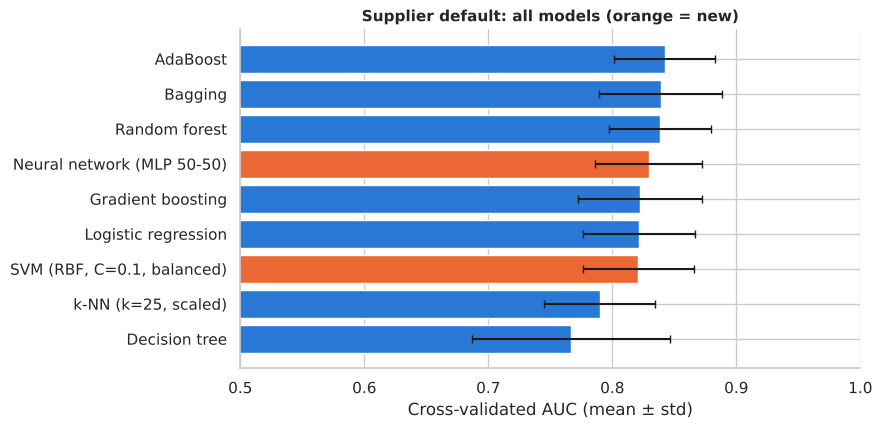

In [92]:
def ranking_score(model, X):
    # probability of class 1 when the model provides one, otherwise the SVM score (enough to compute an AUC)
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

new_clf_models = {
    "SVM (RBF, C=0.1, balanced)":    make_pipeline(StandardScaler(), SVC(kernel="rbf", C=0.1, class_weight="balanced")),
    "Neural network (MLP 50-50)":    make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(50, 50), alpha=1, max_iter=2000, random_state=0)),
}
new_rows = []
for name, model in new_clf_models.items():
    start = time.time()
    cv_res = cross_validate(model, Xb_train, yb_train, cv=cv5, scoring="roc_auc")
    model.fit(Xb_train, yb_train)
    new_rows.append({"model": name, "CV AUC (mean)": cv_res["test_score"].mean(), "CV AUC (std)": cv_res["test_score"].std(),
                     "test AUC": roc_auc_score(yb_test, ranking_score(model, Xb_test)), "time (s)": time.time() - start})
res_clf_all = pd.concat([res_clf, pd.DataFrame(new_rows).set_index("model")]).sort_values("CV AUC (mean)", ascending=False)
display(res_clf_all.round(3))

res_plot = res_clf_all.sort_values("CV AUC (mean)")
plt.figure(figsize=(8, 4.4))
plt.barh(res_plot.index, res_plot["CV AUC (mean)"], xerr=res_plot["CV AUC (std)"], capsize=3,
         color=[ORANGE if i in new_clf_models else BLUE for i in res_plot.index])
plt.xlim(0.5, 1); plt.xlabel("Cross-validated AUC (mean ± std)"); plt.title("Supplier default: all models (orange = new)")
plt.show()

**(2) Lead time of shipments** (Dataset A), metric: RMSE (days).

In [93]:
from sklearn.svm import SVR

new_reg_models = {
    "SVM (SVR, RBF, C=10)":          make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10)),
    "Neural network (MLP 50-50)":    make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(50, 50), max_iter=2000,
                                                                              early_stopping=True, random_state=0)),
}
new_rows = []
for name, model in new_reg_models.items():
    cv_res = cross_validate(model, Xs_train, ys_train, cv=cv_reg, scoring="neg_root_mean_squared_error")
    model.fit(Xs_train, ys_train)
    new_rows.append({"model": name, "CV RMSE (mean)": -cv_res["test_score"].mean(), "CV RMSE (std)": cv_res["test_score"].std(),
                     "test RMSE": root_mean_squared_error(ys_test, model.predict(Xs_test)), "test R²": r2_score(ys_test, model.predict(Xs_test))})
res_reg_all = pd.concat([res_reg, pd.DataFrame(new_rows).set_index("model")]).sort_values("CV RMSE (mean)")
display(res_reg_all.round(3))

,CV RMSE (mean),CV RMSE (std),test RMSE,test R²
model,,,,
Neural network (MLP 50-50),0.708,0.027,0.710,0.914
Gradient boosting,0.712,0.037,0.724,0.911
"SVM (SVR, RBF, C=10)",0.793,0.036,0.808,0.889
Random forest,0.862,0.040,0.824,0.885
Decision tree,1.095,0.057,1.044,0.815
Linear regression,1.110,0.045,1.126,0.785
Naive (mean),2.391,0.086,2.427,-0.000


**Question 91** &nbsp;·&nbsp; *Interpretation*

(a) Supplier default: where do the SVM and the neural network rank? Are they significantly better or worse than the logistic regression and the tree ensembles (compare with the standard deviations)? (b) Lead time: which model is now the best? Why can a neural network (or an SVR) do particularly well on this target? (Hint: recall how the lead time is generated: distance / speed, a congestion effect that grows *progressively* above 75%…) (c) Compare the computing times.

> **Your answer:** 

**Question 92** &nbsp;·&nbsp; *Implementation*

Train a neural network for the **late deliveries** (Dataset A: `Xl_train`, `yl_train`) with two hidden layers of **32 and 16** neurons and `alpha = 1`, then print its AUC on the test set. Compare with the random forest of Part 10.4 (test AUC in the first table of Part 10.4).

> **Your answer:** 

In [ ]:
mlp_late = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(____, ____), alpha=____, max_iter=2000, random_state=0))
mlp_late.fit(____, ____)
print("Test AUC:", round(roc_auc_score(yl_test, mlp_late.predict_proba(____)[:, 1]), 3))

**Question 93** &nbsp;·&nbsp; *Discussion*

Neural networks dominate image, text and speech recognition, but on tabular business data (tables of shipments, suppliers, orders) tree ensembles such as gradient boosting remain the reference in most companies. Propose some explanations. Then, for each of the three projects below, which family of models would you try first, and why?

* (a) the quarterly supplier screening presented to a purchasing committee and to an auditor;
* (b) the automatic reading of photos of received pallets to detect damaged goods;
* (c) a daily demand forecast for 50,000 products with years of history and dozens of variables.

> **Your answer:** 

## Part 12: Interpretability and explainability: opening the black box

A random forest or a gradient boosting model is made of hundreds of trees: **nobody can read it**. Yet a supply-chain or risk manager must often *justify* a decision (why was this supplier downgraded? why do we expect this delay?), *detect* absurd behaviours before they cost money, and *comply* with audit and governance requirements.

Two ideas should not be confused:

| | Definition | Example |
|---|---|---|
| **Interpretability** | the model is *understandable by design* | a small decision tree, a linear regression: you can read the rules/coefficients |
| **Explainability** | we use **extra tools** to explain the behaviour of a complex model *after* it has been trained | feature importance, partial dependence plots, what-if analysis |

We also distinguish **global** explanations (*how does the model work in general?*) from **local** explanations (*why this particular prediction?*).

### 12.1 Global explanation: which variables matter?

We use the random forest for late deliveries. Two ways to measure the importance of a variable:

* **Impurity-based importance** (Part 9.5, averaged over the trees): computed **on the training data** and *by-product of the training*.
* **Permutation importance**: take the **test set**, **shuffle the values of one variable** (which destroys its link with the target) and measure **how much the performance drops**. A big drop means that the model relied on that variable.

Let us first apply the permutation idea by hand to three variables.

In [95]:
from sklearn.inspection import permutation_importance

rf_late = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=0, n_jobs=-1).fit(Xl_train, yl_train)
base_auc = roc_auc_score(yl_test, rf_late.predict_proba(Xl_test)[:, 1])
print(f"AUC of the random forest on the test set: {base_auc:.3f}\n")

rng = np.random.default_rng(0)
for var in ["hub_load", "promised_days", "order_size"]:
    X_shuffled = Xl_test.copy()
    X_shuffled[var] = rng.permutation(X_shuffled[var].values)             # break the link between this variable and the outcome
    auc_shuffled = roc_auc_score(yl_test, rf_late.predict_proba(X_shuffled)[:, 1])
    print(f"Shuffling {var:<14} -> AUC = {auc_shuffled:.3f}  (drop of {base_auc - auc_shuffled:.3f})")

AUC of the random forest on the test set: 0.946

Shuffling hub_load       -> AUC = 0.667  (drop of 0.279)
Shuffling promised_days  -> AUC = 0.944  (drop of 0.002)


Shuffling order_size     -> AUC = 0.946  (drop of 0.000)


**Question 94** &nbsp;·&nbsp; *Interpretation*

Explain, with your own words, why shuffling the values of a variable and observing the drop in performance measures its importance. Which of the three variables matters the most for the forest? Is it consistent with the data description (Part 2)? Then look at `promised_days`: `late` is *defined* relative to it, and yet shuffling it hardly changes the AUC. How can you explain it? (Hint: how is the promised delivery time built? Which other variables carry the same information?)

> **Your answer:** 

**An experiment: can importance measures be fooled?** We add to the data two variables that are **pure noise** by construction: `noise_random` (a random number) and `order_number` (a random identifier with many distinct values — like an order number). They have **no** relationship with lateness. A good importance measure should give them an importance close to zero.

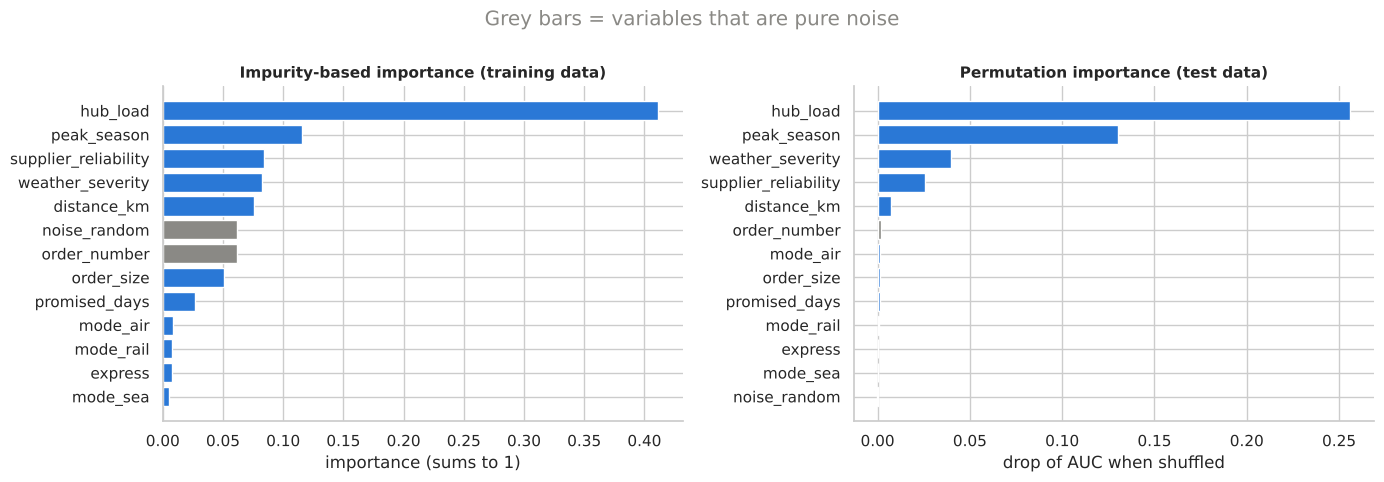

In [96]:
rng = np.random.default_rng(1)
Xn_train = Xl_train.assign(noise_random=rng.random(len(Xl_train)), order_number=rng.permutation(len(Xl_train)))
Xn_test  = Xl_test.assign(noise_random=rng.random(len(Xl_test)),  order_number=rng.integers(0, len(Xl_train), len(Xl_test)))

rf_noise = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1).fit(Xn_train, yl_train)    # fully grown trees (no min_samples_leaf)
imp_impurity = pd.Series(rf_noise.feature_importances_, index=Xn_train.columns)
perm = permutation_importance(rf_noise, Xn_test, yl_test, scoring="roc_auc", n_repeats=10, random_state=0, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=Xn_train.columns)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=False)
for ax, imp, title, xlabel in [(axes[0], imp_impurity, "Impurity-based importance (training data)", "importance (sums to 1)"),
                               (axes[1], imp_perm, "Permutation importance (test data)", "drop of AUC when shuffled")]:
    s = imp.sort_values()
    ax.barh(s.index, s.values, color=[GRAY if i.startswith(("noise", "order_number")) else BLUE for i in s.index])
    ax.set_title(title); ax.set_xlabel(xlabel)
plt.suptitle("Grey bars = variables that are pure noise", y=1.0, color=GRAY)
plt.tight_layout(); plt.show()

**Question 95** &nbsp;·&nbsp; *Interpretation*

Compare the two plots for the two grey variables. What do you observe? Why can the impurity-based importance give a non-zero importance to a variable that has no relationship with the target, while the permutation importance computed on the test set does not?

> **Your answer:** 

**Question 96** &nbsp;·&nbsp; *Analysis*

Two variables are strongly **correlated** (for instance `distance_km` and the transport mode `mode_sea`, since long distances are often shipped by sea). What do you think happens to the permutation importance of each of them when the model can use one to replace the other? What does it imply for the way you report "the" most important variable to a manager?

> **Your answer:** 

### 12.2 Global explanation: how does the model use a variable?

Importance tells *how much* a variable matters, not *how*. The **partial dependence** curve shows the **average prediction** when one variable is forced to take each value of a grid, all other variables keeping their observed values:

> for each value $v$ of the variable: set the variable to $v$ for **all** the shipments, predict, and average.

We compute it by hand for the lead-time models of the showdown (the random forest and the linear regression).

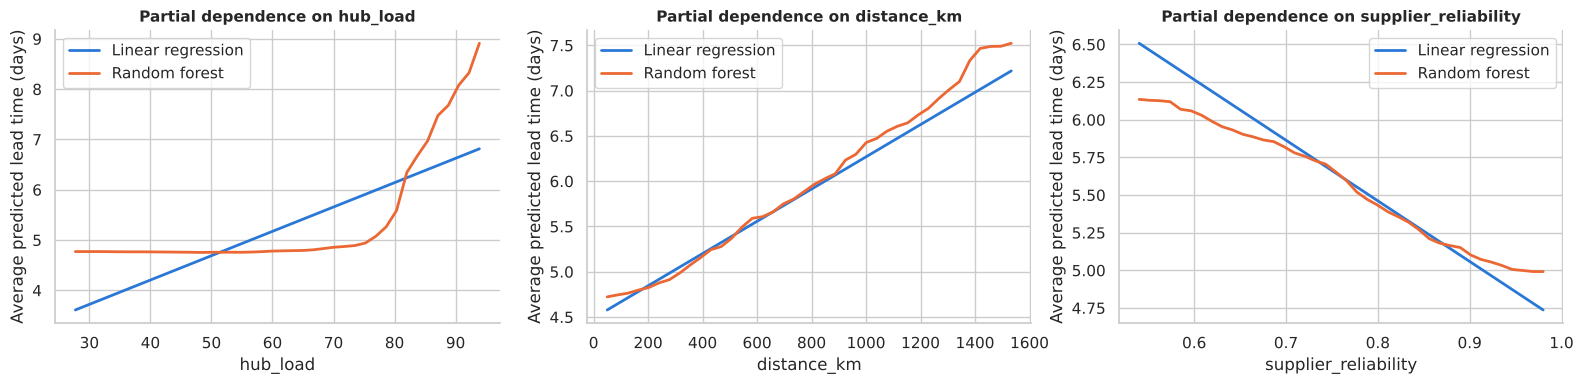

In [97]:
def partial_dependence(model, X, feature, grid):
    # average prediction when `feature` is set to each value of `grid` for all observations
    out = []
    for v in grid:
        Xv = X.copy(); Xv[feature] = v
        out.append(model.predict(Xv).mean())
    return np.array(out)

rf_reg, lin_reg = reg_models["Random forest"], reg_models["Linear regression"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, feature in zip(axes, ["hub_load", "distance_km", "supplier_reliability"]):
    grid = np.linspace(Xs_train[feature].quantile(.02), Xs_train[feature].quantile(.98), 40)
    ax.plot(grid, partial_dependence(lin_reg, Xs_train, feature, grid), color=BLUE, lw=2, label="Linear regression")
    ax.plot(grid, partial_dependence(rf_reg, Xs_train, feature, grid), color=ORANGE, lw=2, label="Random forest")
    ax.set_xlabel(feature); ax.set_ylabel("Average predicted lead time (days)"); ax.legend(); ax.set_title(f"Partial dependence on {feature}")
plt.tight_layout(); plt.show()

**Question 97** &nbsp;·&nbsp; *Interpretation*

(a) What does the random forest "discover" about the hub load that the linear regression cannot express? At about which level of load does the lead time start to increase quickly? (b) How do both models describe the effect of the distance and of the supplier reliability? (c) How could a logistics manager use this result in practice (think of capacity planning)?

> **Your answer:** 

**Question 98** &nbsp;·&nbsp; *Discussion*

The partial dependence curve says: "according to the model, shipments leaving more loaded hubs take longer". Does it prove that **reducing** the load of a hub **would cause** shorter lead times? What other mechanism could produce the same association in the data (for example, which type of orders are sent in periods of high load)? Why is the explanation of a *model* not the same as the explanation of the *real world*?

> **Your answer:** 

### 12.3 Local explanation: why *this* shipment?

For a given shipment, we want to know **why** the model predicts a high probability of delay, and **what could be changed**. Two approaches:

1. **A transparent model** gives the exact rules followed by the shipment (the path in a tree).
2. **A what-if analysis** (also called *ICE curve*, individual conditional expectation) on a complex model: we change one variable of **this** shipment only, and see how the prediction moves.

Shipment #20 of the test set — random forest probability of being late: 0.60 (reality: late)


,value
distance_km,669.00
order_size,34.00
hub_load,39.40
supplier_reliability,0.78
peak_season,1.00
weather_severity,4.20
express,0.00
mode_air,0.00
mode_rail,0.00
mode_sea,0.00



Path followed in the tuned decision tree:
   hub_load = 39.40  <= 82.95
   peak_season = 1.00  >  0.50
   hub_load = 39.40  <= 75.15
   weather_severity = 4.20  <= 4.25
   supplier_reliability = 0.78  <= 0.80
   distance_km = 669.00  >  199.50
   supplier_reliability = 0.78  >  0.67
   order_size = 34.00  <= 40.50
   => tree prediction: late


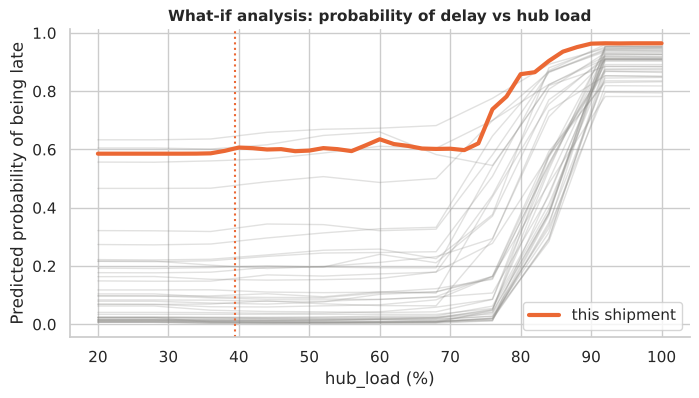

In [98]:
proba_rf = rf_late.predict_proba(Xl_test)[:, 1]
i = int(np.where((proba_rf > 0.5) & (proba_rf < 0.8) & (yl_test.values == 1) & (tree_late.predict(Xl_test) == 1))[0][0])       # a late shipment that the forest finds risky and the tree also flags
shipment = Xl_test.iloc[[i]]
print(f"Shipment #{i} of the test set — random forest probability of being late: {proba_rf[i]:.2f} (reality: late)")
display(shipment.T.rename(columns={shipment.index[0]: "value"}))

# 1) The path followed in the (readable) tuned tree
node_path = tree_late.decision_path(shipment).indices
print("\nPath followed in the tuned decision tree:")
for node in node_path:
    if tree_late.tree_.children_left[node] != -1:
        feat = Xl_test.columns[tree_late.tree_.feature[node]]
        thr, val = tree_late.tree_.threshold[node], shipment[feat].values[0]
        print(f"   {feat} = {val:.2f}  {'<=' if val <= thr else '> '} {thr:.2f}")
print("   => tree prediction:", "late" if tree_late.predict(shipment)[0] == 1 else "on-time")

# 2) What-if analysis on the random forest: only the hub load of this shipment changes
grid = np.linspace(20, 100, 41)
what_if = []
for v in grid:
    s = shipment.copy(); s["hub_load"] = v
    what_if.append(rf_late.predict_proba(s)[0, 1])

plt.figure(figsize=(8, 4))
for j in np.random.default_rng(0).choice(len(Xl_test), 40, replace=False):          # 40 other shipments, in grey
    ice = [rf_late.predict_proba(Xl_test.iloc[[j]].assign(hub_load=v))[0, 1] for v in grid[::4]]
    plt.plot(grid[::4], ice, color=GRAY, alpha=.25, lw=1)
plt.plot(grid, what_if, color=ORANGE, lw=3, label="this shipment")
plt.axvline(shipment["hub_load"].values[0], color=ORANGE, ls=":")
plt.xlabel("hub_load (%)"); plt.ylabel("Predicted probability of being late"); plt.legend()
plt.title("What-if analysis: probability of delay vs hub load"); plt.show()

**Question 99** &nbsp;·&nbsp; *Interpretation*

(a) What are the main reasons for which the tree predicts a delay for this shipment? (b) Using the orange curve, what happens to the predicted probability of delay if this shipment left from a hub loaded at 90% instead of its actual load (dotted line)? From which level of load does the hub load really start to matter? Is the shape the same for every shipment (compare with the grey curves)? (c) Which explanation (tree path or what-if) would you show to an operations manager, and why?

> **Your answer:** 

### 12.4 Explainability in practice: governance and risk

Explainable models are not a luxury in risk management:

* **Justification** — a decision with financial consequences (downgrading or dropping a supplier, refusing credit terms) may have to be explained to the supplier, the purchasing committee or an auditor.
* **Detection of errors** — if the explanation shows that the model relies on a variable that should not matter, or on a leak (like `lead_time` to predict `late`), the model must not be deployed.
* **Fairness and compliance** — variables such as the *country* of a supplier may be legitimate risk factors, but may also lead to systematic exclusion; the use of such variables must be discussed with legal and compliance teams.
* **Monitoring** — the world changes (new suppliers, new routes, crises). A model whose behaviour is understood is easier to monitor and to re-train.

**Question 100** &nbsp;·&nbsp; *Discussion*

The purchasing committee asks: *"Why was this supplier flagged as high-risk by your random forest?"* Describe the **three pieces of evidence** (taken from the tools of this Part) that you would prepare to answer, and one **limit** of each of them that you would be honest about.

> **Your answer:** 

**Question 101** &nbsp;·&nbsp; *Implementation*

Fit a **random forest** on the supplier default data (training set), then compute the **permutation importance** (metric: AUC) of the eight variables on the **test set**. Print the importances in decreasing order. Which three variables are the most important? Is the ranking consistent with the coefficients of the logistic regression (Part 5.2)?

> **Your answer:** 

In [ ]:
rf_default = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=0, n_jobs=-1).fit(____, ____)
perm_default = permutation_importance(rf_default, ____, ____, scoring="roc_auc", n_repeats=10, random_state=0, n_jobs=-1)
importances = pd.Series(perm_default.importances_mean, index=Xb_test.columns).sort_values(ascending=False)
print(importances.round(4))

## Part 13: Wrap-up

### 13.1 Cheat sheet of the algorithms seen in this course

| Algorithm | Idea | Strengths | Weaknesses | Main hyper-parameters |
|---|---|---|---|---|
| **Linear regression** | weighted sum of the features | simple, fast, **interpretable** (days per unit) | only linear, additive effects; sensitive to outliers | — (feature selection) |
| **Logistic regression** | weighted sum → probability | interpretable (odds ratios), good baseline, probabilities | linear frontier; no automatic interactions | regularisation |
| **SVM** | widest margin between the classes; kernels for curved frontiers | flexible frontiers (RBF), good control of overfitting, few support vectors | needs scaling and `class_weight` for rare events, slow on large data, scores not probabilities, RBF hard to explain | kernel, `C`, `gamma` |
| **k-NN** | vote of the $k$ most similar cases | no training, intuitive | slow predictions, needs scaling, suffers with many variables | $k$, distance, weights |
| **Decision tree** | sequence of if/else rules | **readable**, handles thresholds and interactions, no scaling | unstable (high variance), overfits if too deep | `max_depth`, `min_samples_leaf` |
| **Bagging / Random forest** | average of many deep trees on bootstrap samples | **more accurate and stable** than a tree, robust, OOB score | harder to explain, slower | `n_estimators`, `max_features`, `min_samples_leaf` |
| **AdaBoost** | weak models, re-weighting of the errors | strong with simple models | sensitive to noisy labels | `n_estimators`, `learning_rate`, base depth |
| **Gradient boosting** (XGBoost, LightGBM…) | each tree corrects the residuals | often the most accurate on tabular data | can **overfit**; many parameters; not readable | `n_estimators`, `learning_rate`, `max_depth`, `subsample` |
| **Neural network** (MLP) | layers of neurons (weighted sums + activations) learnt by gradient descent | very flexible, the reference for images/text/sound, smooth functions | needs scaling, data and tuning; random initialisation; not readable | `hidden_layer_sizes`, `alpha`, `learning_rate_init`, `max_iter` |

### 13.2 A checklist for every machine-learning project

1. **Frame** the question: target, horizon, decision that will be taken with the prediction, cost of each kind of error.
2. **Check the data**: leakage (variables that are not known at decision time), rare classes, outliers, time order.
3. **Split** first: test set locked away; time-aware split for forecasting.
4. Start with a **naive baseline and a simple model** (mean, logistic/linear regression, small tree).
5. Try **more flexible models** and tune the hyper-parameters by **cross-validation** on the training set.
6. Choose the **metric and the threshold according to the business cost**, not by default.
7. Evaluate **once** on the test set; report the uncertainty (± standard deviation).
8. **Explain** the model (importance, partial dependence, local what-if) and challenge it with domain experts.
9. **Monitor** after deployment: data and behaviours drift.

### 13.3 Mini-case — quarterly supplier screening (Dataset B)

Every quarter the risk department screens **its suppliers** and must decide which ones to flag for an audit or a back-up contract. Costs: a missed default costs **€30,000**, a false alarm **€3,000**.

You have seen that the threshold must be chosen **according to these costs** — but **not on the test set** (that would be cheating). The function below implements the complete procedure that you will apply to different models:

1. compute **out-of-fold probabilities** on the training set (`cross_val_predict`: each supplier is scored by a model that has *not* seen it);
2. choose the **threshold that minimises the business cost** on these out-of-fold scores;
3. train on the whole training set and evaluate **once** on the test set.

*Run the cell: it evaluates the logistic regression.*

In [100]:
from sklearn.model_selection import cross_val_predict

case_results = {}

def cost_pipeline(name, model):
    # 1) out-of-fold probabilities on the training set
    proba_oof = cross_val_predict(model, Xb_train, yb_train, cv=cv5, method="predict_proba")[:, 1]
    # 2) threshold that minimises the business cost on these out-of-fold scores
    thresholds = np.linspace(0.01, 0.6, 60)
    t_best = thresholds[int(np.argmin([business_cost(yb_train, proba_oof, t) for t in thresholds]))]
    # 3) fit on the whole training set and evaluate ONCE on the test set
    model.fit(Xb_train, yb_train)
    proba = model.predict_proba(Xb_test)[:, 1]
    flagged = (proba >= t_best).astype(int)
    case_results[name] = {"threshold": t_best, "flagged (out of 1000)": int(flagged.sum()),
                          "recall": recall_score(yb_test, flagged), "precision": precision_score(yb_test, flagged),
                          "test AUC": roc_auc_score(yb_test, proba), "cost on test (M€)": business_cost(yb_test, proba, t_best) / 1e6}
    return model

cost_pipeline("Logistic regression", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)))
display(pd.DataFrame(case_results).T.round(3))

,threshold,flagged (out of 1000),recall,precision,test AUC,cost on test (M€)
Logistic regression,0.1,227.0,0.662,0.225,0.825,1.308


**Question 102** &nbsp;·&nbsp; *Implementation*

Apply the same procedure to a **gradient boosting** model (200 trees, learning rate 0.05, depth 3) and to a **random forest** (300 trees, `min_samples_leaf=5`). Complete the code, then compare the three rows of the table, including the two reference strategies *flag nobody* and *flag everybody*.

> **Your answer:** 

In [ ]:
gb_case = GradientBoostingClassifier(n_estimators=____, learning_rate=____, max_depth=3, subsample=0.8, random_state=0)
rf_case = RandomForestClassifier(n_estimators=____, min_samples_leaf=____, random_state=0, n_jobs=-1)

gb_case = cost_pipeline("Gradient boosting", ____)
rf_case = cost_pipeline("Random forest", ____)

# the two reference strategies (cost on the test set, in M€)
reference = pd.DataFrame({"cost on test (M€)": {"Flag nobody": yb_test.sum() * COST_FN / 1e6,
                                                 "Flag everybody": (len(yb_test) - yb_test.sum()) * COST_FP / 1e6}})
display(pd.concat([pd.DataFrame(case_results).T, reference]).round(3))

**Question 103** &nbsp;·&nbsp; *Interpretation*

Compare the models in the table above: which one minimises the cost on the test set? How much does it save compared with "flag nobody" and "flag everybody"? Is the model with the best AUC also the one with the lowest cost? Would you trust a difference of a few thousand euros between two models on a test set of 1,000 suppliers?

> **Your answer:** 

**Question 104** &nbsp;·&nbsp; *Discussion*

**Write a recommendation** (5 to 8 lines) to the purchasing committee: which model do you recommend for the quarterly screening, which threshold, what performance (recall, precision, cost) do you expect, which variables drive the risk according to the explanation tools of Part 12, and what are the **limits** of your analysis (synthetic data, stable world, costs assumed, a rare event, fairness)?

> **Your answer:** 

### 13.4 Final quiz

Say whether each statement is **true or false**, and justify in one sentence.

**Question 105** &nbsp;·&nbsp; *Analysis*

1. A model with 99% accuracy on the training set and 70% on the test set is probably overfitting.
2. On a dataset with 1% of defaulting suppliers, a model that reaches 99% accuracy is necessarily a good model.
3. Increasing $k$ in k-NN makes the decision frontier more complex and more flexible.
4. A decision tree needs the features to be standardised, but k-NN does not.
5. Each tree of a random forest is trained on a bootstrap sample and, at each split, considers only a random subset of the variables.
6. In AdaBoost, observations that were misclassified get a *smaller* weight at the next round.
7. Adding more and more trees to a random forest generally leads to overfitting.
8. If cross-validation is too slow, it is acceptable to select the hyper-parameters on the test set.
9. A regression tree can predict values beyond the range of the target seen in training if the features go beyond the training range.
10. The impurity-based importance computed on training data can give a non-zero importance to a variable that is pure noise.
11. The frontier of a linear SVM depends only on its support vectors.
12. In an RBF SVM, a very large `gamma` gives a very smooth frontier.
13. A neural network made of a single neuron with a sigmoid activation is equivalent to a logistic regression.
14. Training the same neural network twice with two different random seeds always gives the same model.
15. SVMs and neural networks, like decision trees, do not need standardised features.

> **Your answer:** 

## Part 14: Final project: a complete study on two new problems

You now know the main families of supervised learning algorithms. In this last part, **you** carry out a complete study, as a junior data analyst would do in a supply-chain or risk department, on two new datasets:

| | Dataset E: stock-out risk | Dataset F: freight cost |
|---|---|---|
| Type of problem | **classification** (will this product be out of stock next week?) | **regression** (how much will this road shipment cost?) |
| Observations | 3,000 product-weeks | 2,500 road shipments |
| Business use | trigger an expedited replenishment before the stock-out | quote a price to a customer, check carrier invoices |
| Level of guidance | **guided**: every step is prepared, you complete and interpret | **semi-guided**: same steps, you fill in more of the code |

As for the other datasets of the course, the data is **synthetic**: the teacher knows the hidden rules that generated it. At the end (Step 8) you will check whether your models and explanation tools have found them.

### The method (the checklist of Part 13.2, step by step)

| Step | What you do | Tools of the course |
|---|---|---|
| 1. Explore | distributions, rates by group, first intuitions | Part 2 |
| 2. Prepare | encode the categories, split train/test (test set locked away) | Parts 3, 5 |
| 3. Benchmark | compare **all** the algorithms with the **same** cross-validation | Parts 8, 10.6, 11.4 |
| 4. Improve the variables | create a business-driven variable (*feature engineering*) | Part 6.4 |
| 5. Tune | tune the 1–2 most promising models with `GridSearchCV` | Part 8.3 |
| 6. Decide and test | choose the decision threshold from the business costs, evaluate **once** on the test set | Parts 4, 5.2, 13.3 |
| 7. Explain | permutation importance, partial dependence | Part 12 |
| 8. Conclude | compare with the hidden rules, write a recommendation with its limits | |

**Deliverable** (suggested, in pairs): this part of the notebook completed, plus a **one-page memo** for each dataset addressed to a non-technical manager (question, chosen model, expected performance in business terms, main drivers, limits). Part 14.3 proposes an optional **deep dive on decision trees and tree ensembles**, the models that you are the most likely to meet in practice.

**Rules of the game**: the test set is used **once**, at Step 6; every comparison is made with the same cross-validation; every number is reported with its uncertainty (± standard deviation); every choice is justified in business terms.

*Run the next cell: it generates the two datasets. Do not read the code before Step 8: it contains the hidden rules!*

In [102]:
# ---- Generators of Datasets E and F (run this cell; do NOT read it before Step 8: it contains the hidden rules) ----
def make_stockouts(n=3000, seed=21):
    rng = np.random.default_rng(seed)
    category = rng.choice(["food", "electronics", "apparel", "pharma"], n, p=[.35, .25, .25, .15])
    cover = np.clip(rng.gamma(2.2, 7, n), 0.5, 80).round(1)
    lead = np.clip(rng.gamma(3, 4, n) + pd.Series(category).map({"food": 0, "electronics": 8, "apparel": 6, "pharma": 3}).values, 1, 60).round(0)
    variability = np.clip(rng.gamma(3, 0.15, n), 0.05, 2).round(2)
    promo = (rng.random(n) < 0.18).astype(int)
    fc_err = np.clip(rng.normal(0, 15, n), -50, 50).round(1)
    otif = np.clip(100 - rng.gamma(1.6, 5, n), 50, 100).round(1)
    price = np.clip(rng.lognormal(3, 1, n), 1, 2000).round(2)
    n_sup = rng.choice([1, 2, 3], n, p=[.5, .35, .15])
    z = (-3.9 + 3.5 * (cover < lead)                          # the stock will not last until the next delivery
         + 2.5 * promo * (variability > 0.6)                  # interaction: promotion on an erratic product
         + 0.06 * np.maximum(fc_err, 0)                       # under-forecasting (positive error) hurts, over-forecasting does not
         + 0.05 * (100 - otif)                                # unreliable supplier
         + 1.0 * variability
         - 0.5 * (n_sup - 1)                                  # alternative suppliers protect
         + pd.Series(category).map({"food": 0.3, "electronics": 0.4, "apparel": -0.4, "pharma": -0.8}).values)
    y = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)    # unit_price_eur has NO effect
    return pd.DataFrame(dict(category=category, stock_cover_days=cover, supplier_lead_time_days=lead, demand_variability=variability,
                             promo_next_week=promo, forecast_error_pct=fc_err, supplier_otif_pct=otif, unit_price_eur=price,
                             n_suppliers=n_sup, stockout_next_week=y))

def make_freight(n=2500, seed=33):
    rng = np.random.default_rng(seed)
    distance = np.clip(rng.gamma(2.2, 230, n), 30, 1800).round(0)
    weight = np.clip(rng.gamma(2.0, 4.5, n), 0.3, 24).round(1)
    pallets = np.clip(np.round(weight * rng.uniform(1.0, 1.8, n)), 1, 33).astype(int)
    fuel = rng.uniform(1.45, 2.05, n).round(3)
    urgency = rng.choice(["standard", "express", "same_day"], n, p=[.7, .22, .08])
    reefer = (rng.random(n) < 0.2).astype(int)
    peak = (rng.random(n) < 0.3).astype(int)
    border = (rng.random(n) < 0.25 + 0.25 * (distance > 600)).astype(int)
    rating = rng.integers(1, 6, n)                                                  # carrier_rating has NO effect
    load_factor = np.minimum(weight / 24, 1) ** 0.55                                # a half-empty truck is not half price
    cost = ((120 + 1.55 * distance ** 0.9 * load_factor * (1 + 0.8 * (fuel - 1.7)))  # fixed cost + degressive cost per km
            * pd.Series(urgency).map({"standard": 1.0, "express": 1.35, "same_day": 1.9}).values
            * (1 + 0.25 * reefer) * (1 + 0.12 * peak * (distance > 500)) + 140 * border)
    cost = cost * rng.lognormal(0, 0.08, n)                                         # ± 8 % noise
    return pd.DataFrame(dict(distance_km=distance, weight_t=weight, pallets=pallets, fuel_price_eur_l=fuel, urgency=urgency,
                             refrigerated=reefer, peak_season=peak, cross_border=border, carrier_rating=rating,
                             freight_cost_eur=cost.round(0)))

stock = make_stockouts()        # Dataset E
freight = make_freight()        # Dataset F
print("Dataset E:", stock.shape, "| Dataset F:", freight.shape)

Dataset E: (3000, 10) | Dataset F: (2500, 10)


### 14.1 Dataset E: predicting stock-outs (classification, guided)

A retailer reviews every week the products of its central warehouse. For each product-week we know, **at the time of the review**:

| Column | Description |
|---|---|
| `category` | `food`, `electronics`, `apparel` or `pharma` |
| `stock_cover_days` | stock on hand divided by the average daily demand (number of days the stock will last) |
| `supplier_lead_time_days` | time between an order and its delivery by the supplier |
| `demand_variability` | coefficient of variation of the weekly demand (0.2 = stable, 1 = erratic) |
| `promo_next_week` | 1 if a promotion is planned next week |
| `forecast_error_pct` | error of last month's forecast (positive = we under-forecast the demand) |
| `supplier_otif_pct` | share of the supplier's orders delivered *on time in full* last quarter |
| `unit_price_eur` | unit price of the product |
| `n_suppliers` | number of approved suppliers for this product |
| `stockout_next_week` | **target**: 1 if the product was out of stock at least one day the following week |

**Business costs.** A missed stock-out (false negative) costs on average **€2,000** (lost margin, penalties from the stores, unhappy customers). A false alarm (false positive) triggers an expedited replenishment that was not needed and costs about **€300**.

#### Step 1: Explore

,category,stock_cover_days,supplier_lead_time_days,demand_variability,promo_next_week,forecast_error_pct,supplier_otif_pct,unit_price_eur,n_suppliers,stockout_next_week
0,apparel,14.8,19.0,0.35,0,-15.4,96.1,22.85,1,0
1,apparel,11.0,14.0,0.34,0,-5.8,96.4,56.37,1,0
2,apparel,19.2,12.0,0.44,0,3.4,99.0,8.73,1,1
3,food,25.9,5.0,0.12,0,-0.3,92.1,16.47,1,0
4,apparel,30.2,8.0,0.24,0,17.6,98.4,22.09,1,0


Share of product-weeks with a stock-out: 37.7%


,mean,std,min,max
stock_cover_days,15.14,10.21,0.50,76.90
supplier_lead_time_days,15.92,7.42,1.00,48.00
demand_variability,0.44,0.25,0.05,1.66
promo_next_week,0.18,0.38,0.00,1.00
forecast_error_pct,0.23,14.73,-50.00,48.70
supplier_otif_pct,92.13,6.28,51.10,100.00
unit_price_eur,33.07,40.96,1.00,528.51
n_suppliers,1.64,0.72,1.00,3.00
stockout_next_week,0.38,0.48,0.00,1.00


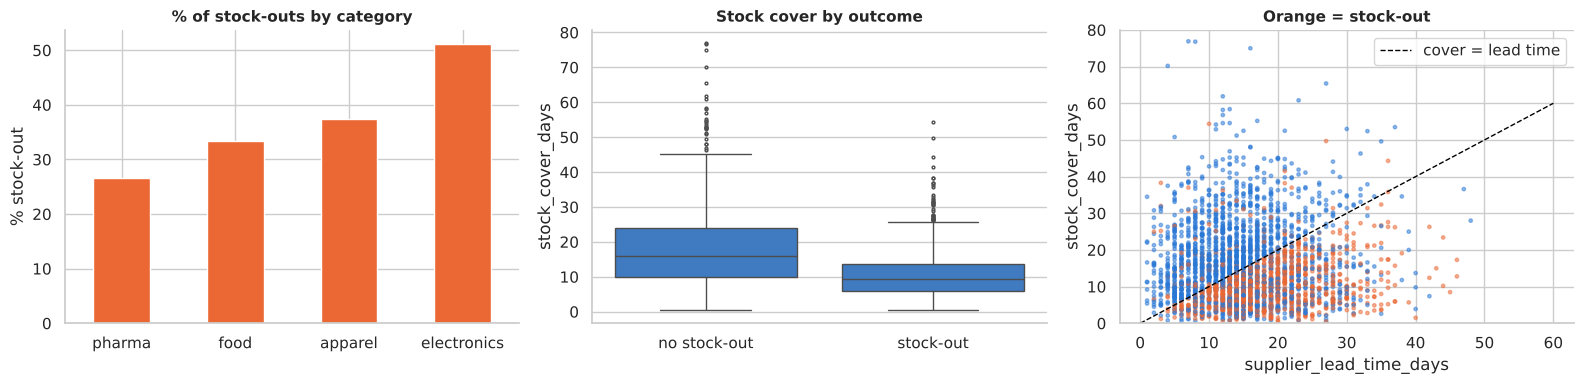

In [103]:
display(stock.head())
print(f"Share of product-weeks with a stock-out: {stock['stockout_next_week'].mean():.1%}")
display(stock.describe().T[["mean", "std", "min", "max"]].round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
(stock.groupby("category")["stockout_next_week"].mean() * 100).sort_values().plot.bar(ax=axes[0], color=ORANGE, rot=0)
axes[0].set_title("% of stock-outs by category"); axes[0].set_ylabel("% stock-out"); axes[0].set_xlabel("")
sns.boxplot(data=stock, x="stockout_next_week", y="stock_cover_days", ax=axes[1], color=BLUE, fliersize=2)
axes[1].set_title("Stock cover by outcome"); axes[1].set_xticks([0, 1], ["no stock-out", "stock-out"]); axes[1].set_xlabel("")
axes[2].scatter(stock["supplier_lead_time_days"], stock["stock_cover_days"], s=6, alpha=.5,
                c=np.where(stock["stockout_next_week"] == 1, ORANGE, BLUE))
axes[2].plot([0, 60], [0, 60], "--", color="black", lw=1, label="cover = lead time")
axes[2].set_xlabel("supplier_lead_time_days"); axes[2].set_ylabel("stock_cover_days"); axes[2].set_ylim(0, 80); axes[2].legend()
axes[2].set_title("Orange = stock-out")
plt.tight_layout(); plt.show()

**Question 106** &nbsp;·&nbsp; *Interpretation*

(a) Is the stock-out a rare event? Is the accuracy a good metric here? (b) Which categories are the most exposed? (c) What do the two plots on the right suggest about the role of the stock cover and of the supplier lead time? Formulate a business hypothesis involving **both** variables.

> **Your answer:** 

**Question 107** &nbsp;·&nbsp; *Implementation*

Compute the stock-out rate (i) with and without a promotion next week, (ii) according to the number of suppliers. Comment in one sentence.

> **Your answer:** 

In [ ]:
display(stock.groupby("____")["stockout_next_week"].mean())
display(stock.groupby("____")["____"].mean())

#### Step 2: Prepare

The category is converted into 0/1 columns (one-hot encoding, `food` is the reference). We keep **25%** of the product-weeks for the final test, with the same share of stock-outs in both sets (`stratify`). *Run the cell.*

In [105]:
Xe = pd.get_dummies(stock.drop(columns="stockout_next_week"), columns=["category"], dtype=int).drop(columns="category_food")
ye = stock["stockout_next_week"]
Xe_train, Xe_test, ye_train, ye_test = train_test_split(Xe, ye, test_size=0.25, stratify=ye, random_state=RANDOM_STATE)
cv_e = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Training set:", Xe_train.shape, "| Test set:", Xe_test.shape)
print(f"Stock-out rate - train: {ye_train.mean():.1%} | test: {ye_test.mean():.1%}")
print("Features:", list(Xe.columns))

Training set: (2250, 11) | Test set: (750, 11)
Stock-out rate - train: 37.7% | test: 37.6%
Features: ['stock_cover_days', 'supplier_lead_time_days', 'demand_variability', 'promo_next_week', 'forecast_error_pct', 'supplier_otif_pct', 'unit_price_eur', 'n_suppliers', 'category_apparel', 'category_electronics', 'category_pharma']


**Question 108** &nbsp;·&nbsp; *Analysis*

(a) The data team proposes to add the variable `units_lost_next_week` (number of sales lost because of empty shelves next week). Should we accept it? (b) The product-weeks cover two years. Why could a random split be slightly optimistic, and which split would be more realistic for a model used every Monday?

> **Your answer:** 

#### Step 3: Benchmark all the algorithms

The function `benchmark` evaluates a dictionary of models with the **same** cross-validation and returns a sorted table with a plot. The dictionary below contains one representative of every family of the course, with reasonable hyper-parameters (you may change them later). *Run the two cells (≈ 1 minute).*

In [106]:
from sklearn.model_selection import cross_validate
from sklearn.neighbors import KNeighborsRegressor

def benchmark(models, X, y, cv, scoring, metric_name, title=""):
    # Cross-validates every model with the same folds; returns a table sorted from best to worst.
    lower_is_better = scoring.startswith("neg_")
    rows = []
    for name, model in models.items():
        start = time.time()
        scores = cross_validate(model, X, y, cv=cv, scoring=scoring)["test_score"]
        scores = -scores if lower_is_better else scores
        rows.append({"model": name, f"CV {metric_name} (mean)": scores.mean(), f"CV {metric_name} (std)": scores.std(),
                     "time (s)": time.time() - start})
    table = pd.DataFrame(rows).set_index("model").sort_values(f"CV {metric_name} (mean)", ascending=lower_is_better)
    s = table.iloc[::-1]
    plt.figure(figsize=(8, 0.45 * len(s) + 1.2))
    plt.barh(s.index, s[f"CV {metric_name} (mean)"], xerr=s[f"CV {metric_name} (std)"], color=BLUE, capsize=3)
    plt.xlabel(f"Cross-validated {metric_name} (mean ± std)"); plt.title(title)
    if not lower_is_better: plt.xlim(0.5, 1)
    plt.show()
    return table

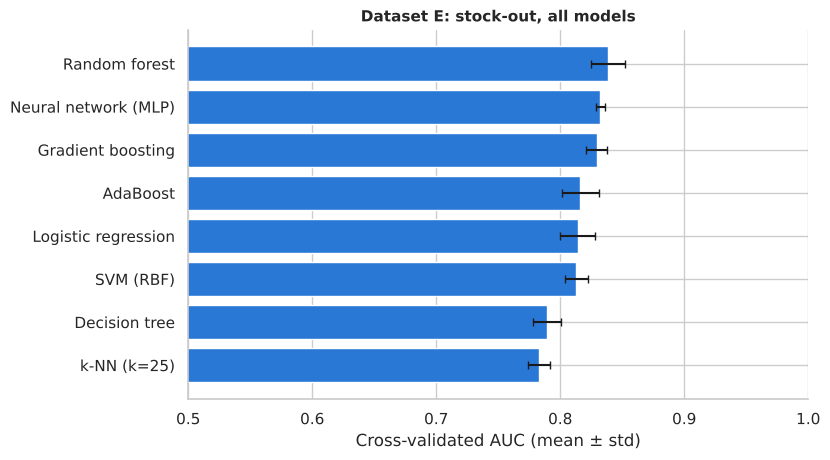

,CV AUC (mean),CV AUC (std),time (s)
model,,,
Random forest,0.838,0.013,3.594
Neural network (MLP),0.832,0.004,8.741
Gradient boosting,0.829,0.008,2.745
AdaBoost,0.816,0.015,2.680
Logistic regression,0.814,0.014,0.051
SVM (RBF),0.813,0.009,0.399
Decision tree,0.789,0.011,0.046
k-NN (k=25),0.783,0.009,0.101


In [107]:
models_e = {
    "Logistic regression":     make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "k-NN (k=25)":             make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25)),
    "SVM (RBF)":               make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1)),
    "Decision tree":           DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=0),
    "Random forest":           RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=0, n_jobs=-1),
    "AdaBoost":                AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2), n_estimators=200, learning_rate=0.1, random_state=0),
    "Gradient boosting":       GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=0),
    "Neural network (MLP)":    make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(50, 50), alpha=1, max_iter=2000, random_state=0)),
}
res_e = benchmark(models_e, Xe_train, ye_train, cv_e, "roc_auc", "AUC", "Dataset E: stock-out, all models")
display(res_e.round(3))

**Question 109** &nbsp;·&nbsp; *Interpretation*

(a) Rank the families of models. Which differences are larger than the standard deviations (i.e. meaningful)? (b) Is the single decision tree competitive? Why? (c) Which two models would you keep for the next steps, taking into account accuracy, computing time and interpretability?

> **Your answer:** 

#### Step 4: Improve the variables (feature engineering)

The plot of Step 1 suggested that what matters is not the stock cover alone nor the lead time alone, but their **comparison**: if the stock lasts *less* than the time needed to receive the next delivery, a stock-out is likely. A tree can only cut **one variable at a time** (lines parallel to the axes), so a diagonal frontier "cover < lead time" requires many cuts.

**Question 110** &nbsp;·&nbsp; *Implementation*

Create the new variable `cover_minus_lead` = `stock_cover_days` − `supplier_lead_time_days` (positive: the stock lasts longer than the replenishment time), then re-run the benchmark for four models. Which model gains the most?

> **Your answer:** 

In [ ]:
Xe2_train = Xe_train.assign(cover_minus_lead=Xe_train["____"] - Xe_train["____"])
four_models = {name: models_e[name] for name in ["Logistic regression", "Decision tree", "Random forest", "Gradient boosting"]}
res_e2 = benchmark(four_models, ____, ye_train, cv_e, "roc_auc", "AUC", "Dataset E with the new variable")
display(pd.concat({"without new variable": res_e.loc[list(four_models), "CV AUC (mean)"],
                   "with cover_minus_lead": res_e2["CV AUC (mean)"]}, axis=1).round(3))

*Run the next cell: from now on we keep the new variable, in the training **and** in the test set (the same transformation must always be applied to both).*

In [109]:
def add_cover_minus_lead(X):
    return X.assign(cover_minus_lead=X["stock_cover_days"] - X["supplier_lead_time_days"])

Xe2_train, Xe2_test = add_cover_minus_lead(Xe_train), add_cover_minus_lead(Xe_test)
print("Features used from now on:", list(Xe2_train.columns))

Features used from now on: ['stock_cover_days', 'supplier_lead_time_days', 'demand_variability', 'promo_next_week', 'forecast_error_pct', 'supplier_otif_pct', 'unit_price_eur', 'n_suppliers', 'category_apparel', 'category_electronics', 'category_pharma', 'cover_minus_lead']


#### Step 5: Tune the most promising models

We tune the **gradient boosting** and the **random forest** with `GridSearchCV` (cross-validation on the training set only). The grids are small on purpose (≈ 1–2 minutes); you may enlarge them.

In [110]:
grids_e = {
    "Gradient boosting": (GradientBoostingClassifier(random_state=0),
                          {"n_estimators": [100, 300], "learning_rate": [0.02, 0.05, 0.1], "max_depth": [2, 3]}),
    "Random forest":     (RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1),
                          {"min_samples_leaf": [1, 5, 10, 20], "max_features": ["sqrt", 0.5]}),
}
tuned_e = {}
for name, (model, grid_params) in grids_e.items():
    gs = GridSearchCV(model, grid_params, cv=cv_e, scoring="roc_auc", n_jobs=-1).fit(Xe2_train, ye_train)
    tuned_e[name] = gs
    print(f"{name:<18} best parameters: {gs.best_params_} | CV AUC = {gs.best_score_:.3f} "
          f"(± {gs.cv_results_['std_test_score'][gs.best_index_]:.3f})")

Gradient boosting  best parameters: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100} | CV AUC = 0.859 (± 0.013)


Random forest      best parameters: {'max_features': 'sqrt', 'min_samples_leaf': 20} | CV AUC = 0.858 (± 0.016)


**Question 111** &nbsp;·&nbsp; *Interpretation*

Compare the tuned models with their versions of Step 4 (same variables, default hyper-parameters). Is the gain obtained by tuning larger or smaller than the gain obtained by the new variable at Step 4? What does it teach you about where to spend your time in a project?

> **Your answer:** 

#### Step 6: Decide and test (once)

The decision threshold is chosen on **out-of-fold** probabilities of the training set (never on the test set), by minimising the business cost (€2,000 per missed stock-out, €300 per false alarm). Then the model is evaluated **once** on the test set. *Run the cell: the function is the same as in the mini-case of Part 13.3, with the new costs.*

In [111]:
COST_MISSED_STOCKOUT, COST_FALSE_ALARM = 2_000, 300

def stockout_cost(y_true, proba, threshold):
    flagged = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, flagged).ravel()
    return fn * COST_MISSED_STOCKOUT + fp * COST_FALSE_ALARM

def decide_and_test(model, X_train, y_train, X_test, y_test, cv):
    proba_oof = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]       # 1) out-of-fold scores
    thresholds = np.linspace(0.02, 0.8, 79)
    t_best = thresholds[int(np.argmin([stockout_cost(y_train, proba_oof, t) for t in thresholds]))]   # 2) best threshold
    model.fit(X_train, y_train)                                                                        # 3) fit on all training data
    proba = model.predict_proba(X_test)[:, 1]
    flagged = (proba >= t_best).astype(int)
    return {"threshold": t_best, "test AUC": roc_auc_score(y_test, proba), "alerts": int(flagged.sum()),
            "recall": recall_score(y_test, flagged), "precision": precision_score(y_test, flagged),
            "cost on test (k€)": stockout_cost(y_test, proba, t_best) / 1e3}

final_e = {name: decide_and_test(gs.best_estimator_, Xe2_train, ye_train, Xe2_test, ye_test, cv_e) for name, gs in tuned_e.items()}
final_e["Logistic regression (reference)"] = decide_and_test(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
                                                             Xe2_train, ye_train, Xe2_test, ye_test, cv_e)
final_e["Never alert"] = {"cost on test (k€)": ye_test.sum() * COST_MISSED_STOCKOUT / 1e3, "alerts": 0}
final_e["Always alert"] = {"cost on test (k€)": (len(ye_test) - ye_test.sum()) * COST_FALSE_ALARM / 1e3, "alerts": len(ye_test)}
display(pd.DataFrame(final_e).T.round(3))

,threshold,test AUC,alerts,recall,precision,cost on test (k€)
Gradient boosting,0.13,0.860,485.0,0.965,0.561,83.9
Random forest,0.18,0.847,474.0,0.950,0.565,89.8
Logistic regression (reference),0.19,0.813,533.0,0.943,0.499,112.1
Never alert,NaN,NaN,0.0,NaN,NaN,564.0
Always alert,NaN,NaN,750.0,NaN,NaN,140.4


**Question 112** &nbsp;·&nbsp; *Interpretation*

(a) Why is the chosen threshold much lower than 0.5? (b) Which model minimises the cost on the test set and how much does it save compared with the two naive strategies? (c) Explain the performance of the selected model to the warehouse manager in two sentences, using the number of alerts, the recall and the precision (per 750 product-weeks).

> **Your answer:** 

#### Step 7: Explain

We explain the selected gradient boosting with the two global tools of Part 12: the **permutation importance** on the test set and the **partial dependence** of the most important variables (computed here with scikit-learn's `PartialDependenceDisplay`, which does exactly what our hand-made function of Part 12.2 did).

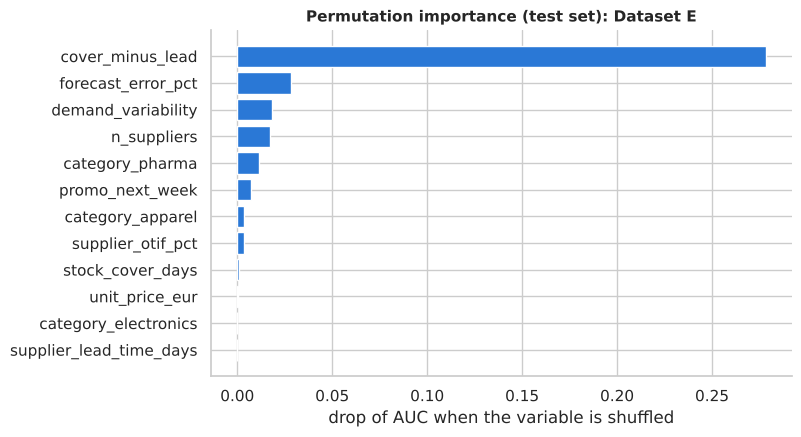

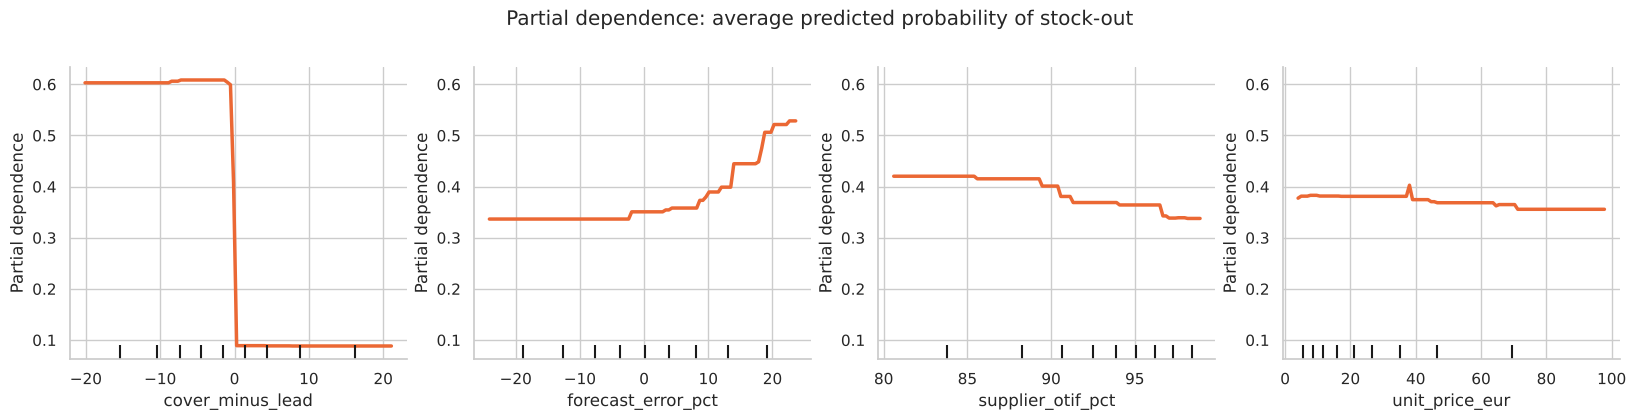

In [112]:
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

best_e = tuned_e["Gradient boosting"].best_estimator_          # already refitted on the whole training set at Step 6
perm_e = permutation_importance(best_e, Xe2_test, ye_test, scoring="roc_auc", n_repeats=10, random_state=0, n_jobs=-1)
imp_e = pd.Series(perm_e.importances_mean, index=Xe2_test.columns).sort_values()
plt.figure(figsize=(7.5, 4.5)); plt.barh(imp_e.index, imp_e.values, color=BLUE)
plt.xlabel("drop of AUC when the variable is shuffled"); plt.title("Permutation importance (test set): Dataset E"); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(20, 3.8))
PartialDependenceDisplay.from_estimator(best_e, Xe2_train, ["cover_minus_lead", "forecast_error_pct", "supplier_otif_pct", "unit_price_eur"],
                                        ax=ax, response_method="predict_proba", method="brute", line_kw={"color": ORANGE, "lw": 2.5})
plt.suptitle("Partial dependence: average predicted probability of stock-out", y=1.03); plt.show()

**Question 113** &nbsp;·&nbsp; *Interpretation*

(a) Which variables drive the stock-out risk according to the model? Which ones are useless? (b) Describe the shape of the four partial dependence curves in business terms (e.g. "when the stock cover becomes shorter than the lead time …"). Is the effect of the forecast error symmetric?

> **Your answer:** 

#### Step 8: Conclude

Now (and only now!) read the code of `make_stockouts` in the generator cell at the beginning of Part 14: it contains the true rules used to simulate the stock-outs.

**Question 114** &nbsp;·&nbsp; *Discussion*

(a) Which hidden rules did your analysis find (Steps 1, 4 and 7)? Which ones were missed or only partially found, and why? (b) Write the **memo** (6 to 8 lines) to the supply-chain director: which model, which alert threshold, what the director should expect every week (alerts, stock-outs caught, cost), the main drivers and three limits.

> **Your answer:** 

### 14.2 Dataset F: estimating freight costs (regression, semi-guided)

A logistics service provider wants to **quote** road transport prices instantly and to **check** carrier invoices. For 2,500 past shipments we know:

| Column | Description |
|---|---|
| `distance_km` | road distance |
| `weight_t` | weight of the shipment (tonnes; a full truck carries 24 t) |
| `pallets` | number of pallets |
| `fuel_price_eur_l` | diesel price on the day of the shipment (€/litre) |
| `urgency` | `standard`, `express` or `same_day` |
| `refrigerated` | 1 if temperature-controlled |
| `peak_season` | 1 if shipped in the peak season |
| `cross_border` | 1 if the shipment crosses a border |
| `carrier_rating` | rating of the carrier (1 to 5 stars) |
| `freight_cost_eur` | **target**: invoiced cost (€) |

Follow the same steps as for Dataset E. This time you complete more of the code yourself: the blanks `____` replace names of variables or of models, or values of hyper-parameters.

#### Steps 1 and 2: Explore and prepare *(run the cells)*

,distance_km,weight_t,pallets,fuel_price_eur_l,urgency,refrigerated,peak_season,cross_border,carrier_rating,freight_cost_eur
0,567.0,8.7,13,1.809,standard,0,1,1,3,661.0
1,642.0,21.1,32,1.832,express,1,0,0,3,1199.0
2,101.0,10.6,13,1.454,standard,0,0,0,2,183.0
3,399.0,4.2,7,1.763,standard,1,0,0,3,323.0
4,1304.0,9.0,12,1.649,standard,1,0,0,5,901.0


,mean,std,min,max
distance_km,504.34,332.90,30.00,1800.00
weight_t,8.75,5.77,0.30,24.00
pallets,12.23,8.18,1.00,33.00
fuel_price_eur_l,1.75,0.17,1.45,2.05
refrigerated,0.19,0.40,0.00,1.00
peak_season,0.31,0.46,0.00,1.00
cross_border,0.33,0.47,0.00,1.00
carrier_rating,3.01,1.42,1.00,5.00
freight_cost_eur,479.37,274.07,118.00,2160.00


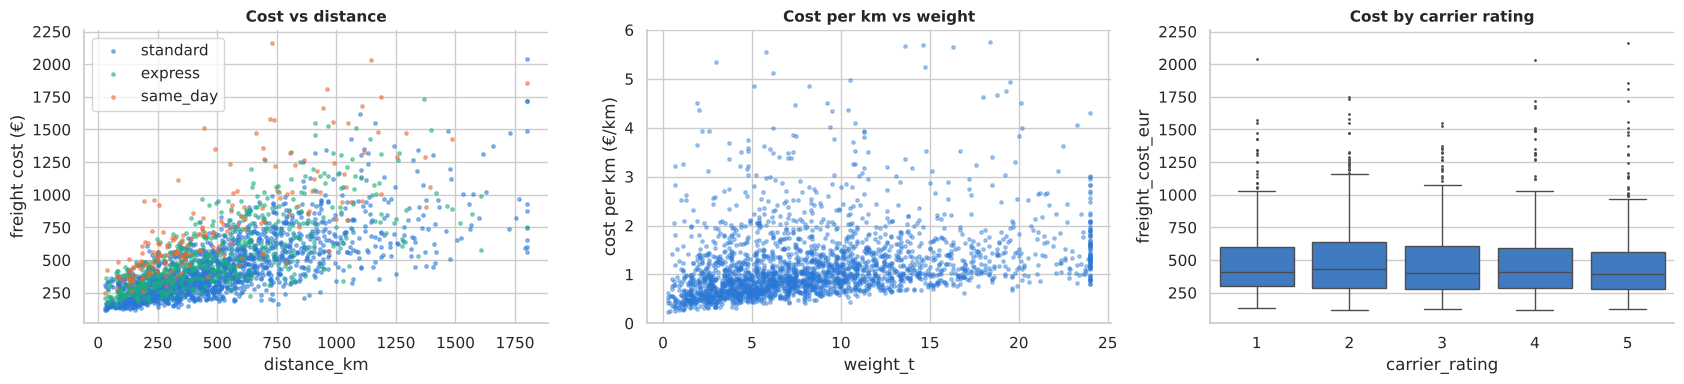

Training set: (1875, 10) | Test set: (625, 10)


In [113]:
display(freight.head())
display(freight.describe().T[["mean", "std", "min", "max"]].round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for u, color in [("standard", BLUE), ("express", AQUA), ("same_day", ORANGE)]:
    sub = freight[freight["urgency"] == u]
    axes[0].scatter(sub["distance_km"], sub["freight_cost_eur"], s=6, alpha=.5, color=color, label=u)
axes[0].set_xlabel("distance_km"); axes[0].set_ylabel("freight cost (€)"); axes[0].legend(); axes[0].set_title("Cost vs distance")
axes[1].scatter(freight["weight_t"], freight["freight_cost_eur"] / freight["distance_km"], s=6, alpha=.4, color=BLUE)
axes[1].set_xlabel("weight_t"); axes[1].set_ylabel("cost per km (€/km)"); axes[1].set_ylim(0, 6); axes[1].set_title("Cost per km vs weight")
sns.boxplot(data=freight, x="carrier_rating", y="freight_cost_eur", ax=axes[2], color=BLUE, fliersize=1)
axes[2].set_title("Cost by carrier rating")
plt.tight_layout(); plt.show()

Xf = pd.get_dummies(freight.drop(columns="freight_cost_eur"), columns=["urgency"], dtype=int).drop(columns="urgency_standard").astype(float)
yf = freight["freight_cost_eur"]
Xf_train, Xf_test, yf_train, yf_test = train_test_split(Xf, yf, test_size=0.25, random_state=RANDOM_STATE)
cv_f = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Training set:", Xf_train.shape, "| Test set:", Xf_test.shape)

**Question 115** &nbsp;·&nbsp; *Interpretation*

(a) Is the cost proportional to the distance? (b) What does the second plot say about the cost of a nearly empty truck compared with a full one? (c) Does the carrier rating seem to matter? (d) Which of these effects can a linear regression represent correctly, and which ones not?

> **Your answer:** 

#### Step 3: Benchmark

**Question 116** &nbsp;·&nbsp; *Implementation*

Complete the dictionary of models (use the same hyper-parameters as for the lead time in Parts 10.6 and 11.4: random forest with 300 trees and `min_samples_leaf=3`; gradient boosting with 300 trees, learning rate 0.05, depth 3; an MLP with two hidden layers of 50 neurons), then run the benchmark with the metric `neg_root_mean_squared_error`. Rank the models and compare with the naive model.

> **Your answer:** 

In [ ]:
models_f = {
    "Naive (mean)":          DummyRegressor(strategy="mean"),
    "Linear regression":     LinearRegression(),
    "k-NN (k=10)":           make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10)),
    "Decision tree":         DecisionTreeRegressor(min_samples_leaf=10, random_state=0),
    "Random forest":         RandomForestRegressor(n_estimators=____, min_samples_leaf=____, random_state=0, n_jobs=-1),
    "Gradient boosting":     GradientBoostingRegressor(n_estimators=____, learning_rate=____, max_depth=____, random_state=0),
    "SVM (SVR, RBF)":        make_pipeline(StandardScaler(), SVR(kernel="rbf", C=1000, epsilon=10)),
    "Neural network (MLP)":  make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(____, ____), max_iter=3000, random_state=0)),
}
res_f = benchmark(models_f, Xf_train, yf_train, cv_f, "____", "RMSE (€)", "Dataset F: freight cost, all models")
display(res_f.round(1))

#### Steps 5 and 6: Tune one model and test it (once)

**Question 117** &nbsp;·&nbsp; *Implementation*

Tune the **gradient boosting** with `GridSearchCV` on the grid `n_estimators` ∈ {300, 600}, `learning_rate` ∈ {0.05, 0.1}, `max_depth` ∈ {3, 4} (metric: `neg_root_mean_squared_error`). Then evaluate the tuned model **once** on the test set: RMSE, MAE (in €) and the mean absolute error **in % of the cost**.

> **Your answer:** 

In [ ]:
gs_f = GridSearchCV(GradientBoostingRegressor(random_state=0),
                    {"n_estimators": [____, ____], "learning_rate": [____, ____], "max_depth": [____, ____]},
                    cv=cv_f, scoring="____", n_jobs=-1).fit(Xf_train, yf_train)
print("Best parameters:", gs_f.best_params_, f"| CV RMSE = {-gs_f.best_score_:.1f} €")

best_f = gs_f.best_estimator_
pred_f = best_f.predict(____)
print(f"Test RMSE = {root_mean_squared_error(yf_test, pred_f):.1f} € | test MAE = {mean_absolute_error(yf_test, pred_f):.1f} € | "
      f"mean absolute error = {np.mean(np.abs(yf_test - pred_f) / yf_test):.1%} of the cost")

#### Step 7: Explain *(run the cell once `best_f` exists)*

In [ ]:
perm_f = permutation_importance(best_f, Xf_test, yf_test, scoring="neg_root_mean_squared_error", n_repeats=10, random_state=0, n_jobs=-1)
imp_f = pd.Series(perm_f.importances_mean, index=Xf_test.columns).sort_values()
plt.figure(figsize=(7.5, 4.2)); plt.barh(imp_f.index, imp_f.values, color=BLUE)
plt.xlabel("increase of the RMSE (€) when the variable is shuffled"); plt.title("Permutation importance (test set): Dataset F"); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(20, 3.8))
PartialDependenceDisplay.from_estimator(best_f, Xf_train, ["distance_km", "weight_t", "fuel_price_eur_l", "carrier_rating"],
                                        ax=ax, line_kw={"color": ORANGE, "lw": 2.5})
plt.suptitle("Partial dependence: average predicted cost (€)", y=1.03); plt.show()

**Question 118** &nbsp;·&nbsp; *Discussion*

(a) Read the importance and the partial dependence curves: how does the model describe the effect of the distance, of the weight and of the fuel price? Is the carrier rating used? (b) Now read the code of `make_freight`: which rules were found? (c) The sales team wants to use the model to quote prices *instantly*. Write a short recommendation (5 lines): accuracy to expect in €/%, for which shipments the quote may be unreliable (think of the range of the training data), and how the model should be monitored.

> **Your answer:** 

### 14.3 Deep dive (optional): decision trees and tree ensembles

Decision trees, random forests and gradient boosting are the models that you are most likely to meet in supply-chain and risk departments: trees because managers can **read** them, ensembles because they are among the **most accurate** methods on tabular data. This section studies them in more depth on Datasets E and F. Every cell can be run as it is; the questions ask you to interpret and, sometimes, to change one parameter.

#### (a) How stable is a single tree?

We grow a tree of depth 3 on four **bootstrap samples** of the training set of Dataset E (same data, slightly reshuffled), then count, over 50 bootstrap samples, which question the tree asks **first**.

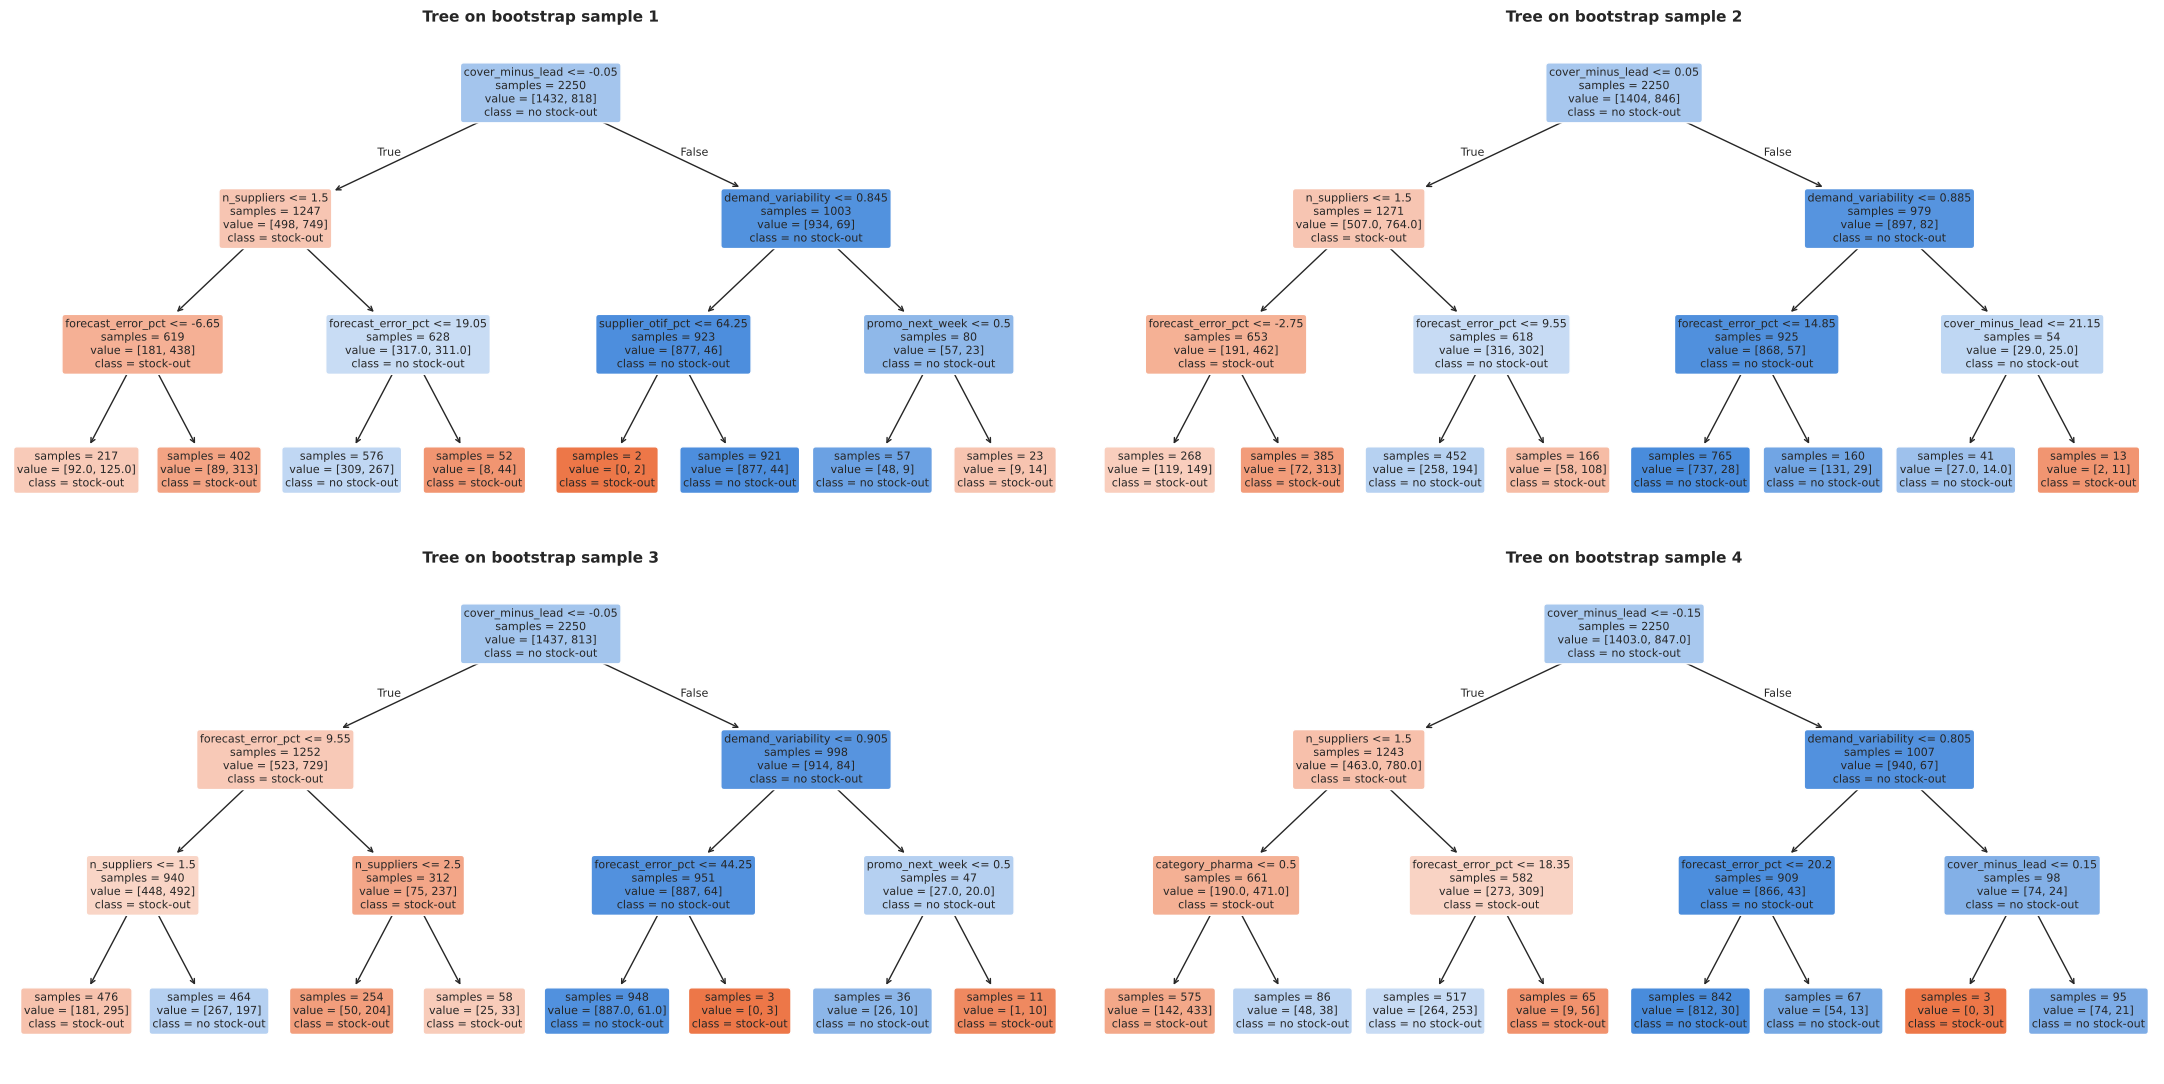

,count,mean,min,max
root variable,,,,
cover_minus_lead,50.0,-0.08,-0.25,0.05


second-level variables
demand_variability / forecast_error_pct    20
demand_variability / n_suppliers           16
forecast_error_pct / n_suppliers            7
forecast_error_pct                          3
category_pharma / forecast_error_pct        3
forecast_error_pct / supplier_otif_pct      1
Name: count, dtype: int64

In [117]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 2, figsize=(22, 11))
for ax, b in zip(axes.ravel(), range(4)):
    idx = rng.integers(0, len(Xe2_train), len(Xe2_train))
    t_boot = DecisionTreeClassifier(max_depth=3, random_state=0).fit(Xe2_train.iloc[idx], ye_train.iloc[idx])
    draw_tree(t_boot, Xe2_train.columns, class_names=("no stock-out", "stock-out"), ax=ax, fontsize=8, impurity=False)
    ax.set_title(f"Tree on bootstrap sample {b + 1}")
plt.tight_layout(); plt.show()

first_splits = []
for b in range(50):
    idx = rng.integers(0, len(Xe2_train), len(Xe2_train))
    t_boot = DecisionTreeClassifier(max_depth=3, random_state=0).fit(Xe2_train.iloc[idx], ye_train.iloc[idx])
    first_splits.append({"root variable": Xe2_train.columns[t_boot.tree_.feature[0]], "threshold": t_boot.tree_.threshold[0],
                         "second-level variables": " / ".join(sorted({Xe2_train.columns[t_boot.tree_.feature[c]]
                                                                      for c in (t_boot.tree_.children_left[0], t_boot.tree_.children_right[0])}))})
first_splits = pd.DataFrame(first_splits)
display(first_splits.groupby("root variable")["threshold"].describe()[["count", "mean", "min", "max"]].round(2))
display(first_splits["second-level variables"].value_counts().head(6))

**Question 119** &nbsp;·&nbsp; *Interpretation*

(a) Is the first question asked by the tree stable from one bootstrap sample to another (variable and threshold)? (b) Are the second-level questions as stable? (c) What does it imply if a manager uses the rules of *one* tree as "the truth" about stock-outs? How do random forests turn this weakness into a strength?

> **Your answer:** 

#### (b) Pruning a tree: cost-complexity pruning

Instead of limiting the depth *before* growing the tree, we can grow a large tree and **prune** it afterwards. *Cost-complexity pruning* removes the branches that bring the smallest improvement per leaf. Its hyper-parameter `ccp_alpha` is the "price" of one additional leaf: `ccp_alpha = 0` keeps the full tree, larger values give smaller trees. We choose it by cross-validation.

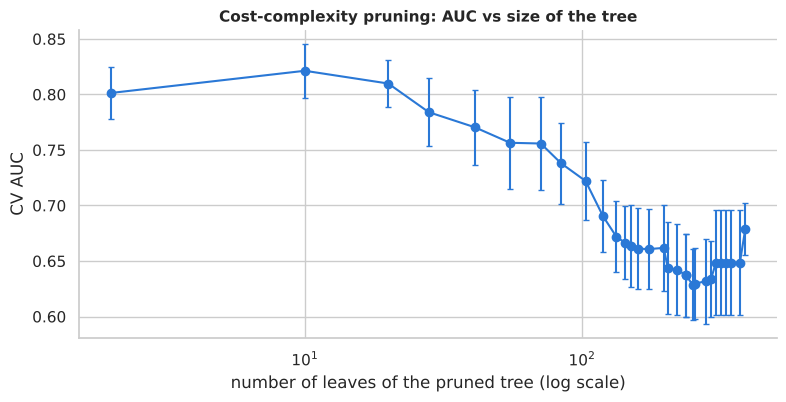

,ccp_alpha,leaves,CV AUC,CV AUC std
28,0.003,10,0.821,0.024
27,0.002,20,0.810,0.021
29,0.009,2,0.801,0.024
26,0.001,28,0.784,0.031
25,0.001,41,0.770,0.034


Best ccp_alpha = 0.00271


In [118]:
path = DecisionTreeClassifier(random_state=0).cost_complexity_pruning_path(Xe2_train, ye_train)
alphas = np.unique(np.quantile(path.ccp_alphas[:-1], np.linspace(0, 1, 30)))     # 30 candidate values along the path
prune_rows = []
for a in alphas:
    t_pruned = DecisionTreeClassifier(ccp_alpha=a, random_state=0)
    auc_cv = cross_val_score(t_pruned, Xe2_train, ye_train, cv=cv_e, scoring="roc_auc")
    prune_rows.append({"ccp_alpha": a, "leaves": t_pruned.fit(Xe2_train, ye_train).get_n_leaves(),
                       "CV AUC": auc_cv.mean(), "CV AUC std": auc_cv.std()})
prune = pd.DataFrame(prune_rows)
best_alpha = prune.loc[prune["CV AUC"].idxmax(), "ccp_alpha"]

fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.errorbar(prune["leaves"], prune["CV AUC"], yerr=prune["CV AUC std"], fmt="o-", color=BLUE, capsize=2)
ax1.set_xscale("log"); ax1.set_xlabel("number of leaves of the pruned tree (log scale)"); ax1.set_ylabel("CV AUC")
ax1.set_title("Cost-complexity pruning: AUC vs size of the tree")
plt.show()
display(prune.sort_values("CV AUC", ascending=False).head(5).round(4))
print(f"Best ccp_alpha = {best_alpha:.5f}")

**Question 120** &nbsp;·&nbsp; *Implementation*

Fit the pruned tree with the best `ccp_alpha` found above, print its number of leaves and its **test** AUC, and draw its first three levels. Compare with the tree of the benchmark (depth 5, test AUC to compute in the same way) and with the gradient boosting of Step 6.

> **Your answer:** 

In [ ]:
tree_pruned = DecisionTreeClassifier(ccp_alpha=____, random_state=0).fit(Xe2_train, ye_train)
tree_d5 = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=0).fit(Xe2_train, ye_train)
for name, t_model in [("pruned tree", tree_pruned), ("tree depth 5", tree_d5)]:
    print(f"{name}: {t_model.get_n_leaves()} leaves | test AUC = {roc_auc_score(ye_test, t_model.predict_proba(____)[:, 1]):.3f}")
plt.figure(figsize=(20, 7))
draw_tree(tree_pruned, Xe2_train.columns, class_names=("no stock-out", "stock-out"), ax=plt.gca(), max_depth=____, fontsize=9)
plt.show()

#### (c) Gradient boosting: what does the depth of the trees mean?

In gradient boosting the depth of the small trees has a precise meaning: with trees of **depth 1** (stumps), each tree uses **one** variable, so the model is a **sum of effects of single variables** (an *additive* model, like a linear regression but with curves): it cannot represent **interactions**. With depth 2, each tree can combine two variables, and so on. We compare depths 1 to 5 on Dataset E, **with and without** the variable `cover_minus_lead`.

In [120]:
depth_rows = []
for depth in [1, 2, 3, 5]:
    gb_d = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=depth, random_state=0)
    depth_rows.append({"max_depth": depth,
                       "CV AUC, original variables": cross_val_score(gb_d, Xe_train, ye_train, cv=cv_e, scoring="roc_auc").mean(),
                       "CV AUC, with cover_minus_lead": cross_val_score(gb_d, Xe2_train, ye_train, cv=cv_e, scoring="roc_auc").mean()})
display(pd.DataFrame(depth_rows).set_index("max_depth").round(3))

,"CV AUC, original variables","CV AUC, with cover_minus_lead"
max_depth,,
1,0.804,0.858
2,0.826,0.860
3,0.829,0.852
5,0.824,0.838


**Question 121** &nbsp;·&nbsp; *Analysis*

(a) With the original variables, why does the AUC improve clearly from depth 1 to depth 2? Which hidden rule needs an interaction of two variables? (b) With `cover_minus_lead`, why does depth 1 become almost as good as deeper trees? (c) Which other interaction is present in the data (look at the generator), and why is it less visible here?

> **Your answer:** 

#### (d) Gradient boosting: choosing the number of trees automatically (*early stopping*)

In Part 10.5 we saw that boosting can overfit when we add too many trees. *Early stopping* keeps a part of the training data aside (`validation_fraction`) and stops adding trees when the validation score has not improved for `n_iter_no_change` rounds. The test set is never used.

Early stopping: 170 trees kept out of 2000 | test AUC = 0.858
2000 trees without stopping              | test AUC = 0.831


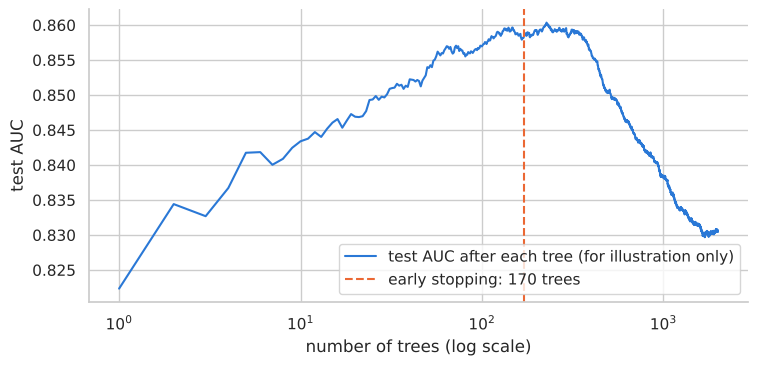

In [121]:
gb_es = GradientBoostingClassifier(n_estimators=2000, learning_rate=0.05, max_depth=3, validation_fraction=0.2,
                                   n_iter_no_change=30, random_state=0).fit(Xe2_train, ye_train)
gb_2000 = GradientBoostingClassifier(n_estimators=2000, learning_rate=0.05, max_depth=3, random_state=0).fit(Xe2_train, ye_train)
print(f"Early stopping: {gb_es.n_estimators_} trees kept out of 2000 | test AUC = {roc_auc_score(ye_test, gb_es.predict_proba(Xe2_test)[:, 1]):.3f}")
print(f"2000 trees without stopping              | test AUC = {roc_auc_score(ye_test, gb_2000.predict_proba(Xe2_test)[:, 1]):.3f}")

test_auc_curve = [roc_auc_score(ye_test, p[:, 1]) for p in gb_2000.staged_predict_proba(Xe2_test)]
plt.figure(figsize=(8.5, 3.8))
plt.plot(range(1, 2001), test_auc_curve, color=BLUE, label="test AUC after each tree (for illustration only)")
plt.axvline(gb_es.n_estimators_, color=ORANGE, ls="--", label=f"early stopping: {gb_es.n_estimators_} trees")
plt.xscale("log"); plt.xlabel("number of trees (log scale)"); plt.ylabel("test AUC"); plt.legend(); plt.show()

**Question 122** &nbsp;·&nbsp; *Interpretation*

How many trees does early stopping keep? What happens to the test AUC when we go on to 2,000 trees? Why is early stopping a legitimate way to choose the number of trees, whereas reading the best point of the blue curve is not?

> **Your answer:** 

#### (e) How much data do the models need? Learning curves

A *learning curve* shows the cross-validated performance as a function of the **size of the training set**. It answers a frequent business question: *"is it worth collecting more history?"*

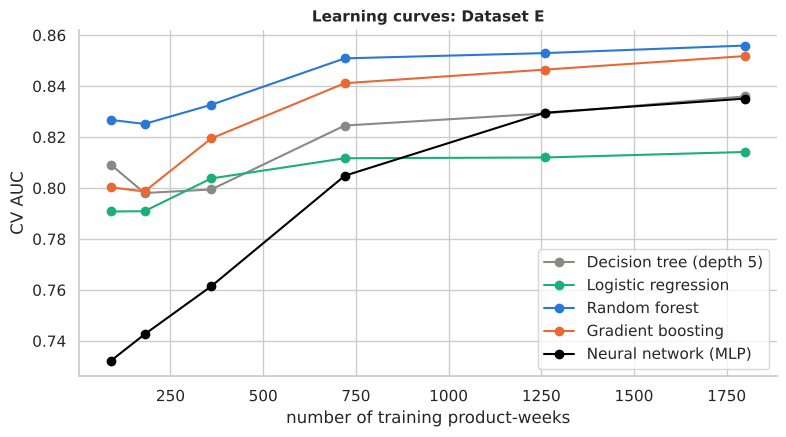

In [122]:
from sklearn.model_selection import learning_curve

lc_models = {"Decision tree (depth 5)": (DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=0), GRAY),
             "Logistic regression":     (make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), AQUA),
             "Random forest":           (RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=0, n_jobs=-1), BLUE),
             "Gradient boosting":       (GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=0), ORANGE),
             "Neural network (MLP)":    (make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(50, 50), alpha=1, max_iter=2000, random_state=0)), "black")}
plt.figure(figsize=(9, 4.5))
for name, (model, color) in lc_models.items():
    sizes, _, val_scores = learning_curve(model, Xe2_train, ye_train, cv=cv_e, scoring="roc_auc",
                                          train_sizes=[0.05, 0.1, 0.2, 0.4, 0.7, 1.0], n_jobs=-1)
    plt.plot(sizes, val_scores.mean(axis=1), "o-", color=color, label=name)
plt.xlabel("number of training product-weeks"); plt.ylabel("CV AUC"); plt.legend(); plt.title("Learning curves: Dataset E")
plt.show()

**Question 123** &nbsp;·&nbsp; *Interpretation*

(a) Which model is the best with very little data (≈ 100 product-weeks)? Which ones need more data to become good? Why? (b) Do the curves still go up at the right end? Would you advise the company to spend money to collect twice as much history for this problem?

> **Your answer:** 

#### (f) Tree ensembles outside the training range (Dataset F)

In Part 9.6 we saw that a regression tree cannot predict beyond the values it has seen. Is it also true for forests and boosting? We predict the cost of a "typical" shipment (all variables at their median) when **only the distance** changes, up to 3,000 km, whereas the training data stops at 1,800 km.

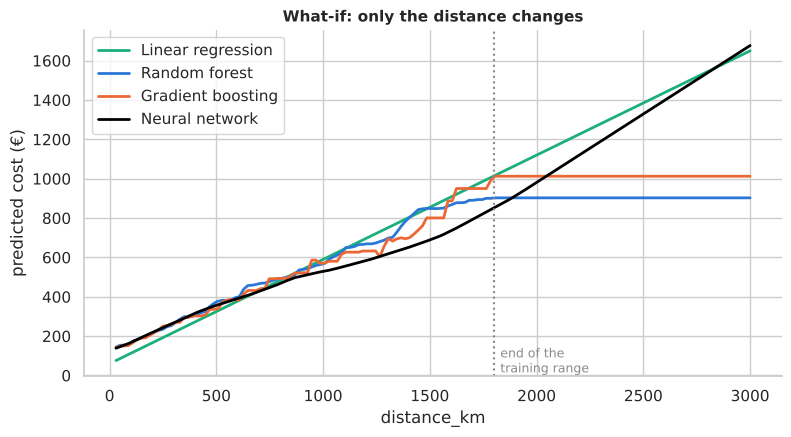

In [123]:
typical_f = Xf_train.median().to_frame().T
dist_grid = np.linspace(30, 3000, 150)
scen_f = pd.concat([typical_f] * len(dist_grid), ignore_index=True); scen_f["distance_km"] = dist_grid
whatif_models = {"Linear regression": (LinearRegression(), AQUA),
                 "Random forest":     (RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0, n_jobs=-1), BLUE),
                 "Gradient boosting": (GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=0), ORANGE),
                 "Neural network":    (make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(50, 50), max_iter=3000, random_state=0)), "black")}
plt.figure(figsize=(9, 4.5))
for name, (model, color) in whatif_models.items():
    plt.plot(dist_grid, model.fit(Xf_train, yf_train).predict(scen_f), color=color, lw=2, label=name)
plt.axvline(Xf_train["distance_km"].max(), color=GRAY, ls=":")
plt.text(Xf_train["distance_km"].max() + 30, plt.ylim()[0] + 20, "end of the\ntraining range", color=GRAY, fontsize=9)
plt.xlabel("distance_km"); plt.ylabel("predicted cost (€)"); plt.legend(); plt.title("What-if: only the distance changes")
plt.show()

**Question 124** &nbsp;·&nbsp; *Discussion*

(a) Describe the behaviour of each model beyond 1,800 km. Which ones "freeze", which ones go on increasing? Is any of them right? (b) A customer asks for a quote for a 2,600 km shipment. What would you do? (c) Summarise in three bullet points what this deep dive taught you about trees and tree ensembles (stability, tuning, limits).

> **Your answer:** 

---
### To go further

* **Other metrics and techniques**: precision–recall curves, calibration of probabilities, handling of imbalanced data (class weights, resampling), quantile regression for *safety stocks* (predicting a high quantile of the demand rather than the mean).
* **Time series forecasting**: lag features, rolling windows, time-aware cross-validation (`TimeSeriesSplit`).
* **Industrial boosting libraries**: XGBoost, LightGBM, CatBoost — same principle as Part 10.5, faster and with more options.
* **Unsupervised learning**: clustering suppliers or customers (k-means), anomaly detection.
* **Explainability**: SHAP values (a rigorous way to explain individual predictions of tree ensembles).
* **Deep learning**: convolutional networks for images, transformers for text and time series; libraries PyTorch, Keras/TensorFlow.
